---
title: "TSM: alcohol consumption transitions harmonized with the EPS engine"
subtitle: "Rounds 7–11, whole-person bootstrap and cross-check against EPS"
author: "Andres Gonzalez Santa Cruz"
lang: en
format:
  html:
    theme: journal
    css: [_lib/styles.css, _lib/prediction_metrics_compact.css]
    toc: true
    toc-location: left
    toc-depth: 2
    number-sections: false
    code-fold: true
    code-summary: "Show R code"
    code-tools: true
    embed-resources: true
    self-contained: true
    html-math-method: mathml
execute:
  echo: true
  warning: false
  error: false
---

**Quick orientation:** the same people are followed across five rounds of the Termómetro de la Salud Mental (TSM), rounds 7 to 11, and their drinking category at one round is used to predict the category at the next. The computation is the EPS transition engine ported to this panel: the same six states, the same models, the same person-blocked validation and the same annual layer. What changes is the data layer, because TSM has short intervals, no survey design variables and alcohol items without a recall window. Every result in this notebook comes from the saved tables; the text explains how to read them and does not restate numbers.

## How this notebook relates to version 2 and to the EPS engine

Version 2 of the TSM analysis was built on its own conventions. Version 3 keeps its data reading and linking, which are checked against the version 2 counts, and replaces everything downstream with the EPS engine so that the two Chilean panels produce matrices that can be read side by side. The crosswalk below lists each decision in the three vocabularies.

| Decision | TSM v2 | TSM v3 (this notebook) | EPS engine |
|---|---|---|---|
| States | ND_unknown, FD, cat1–cat4 | N0, FD, C1–C4 | N0, FD, C1–C4 |
| Destination classes | six states | NC, C1–C4 (NC splits into N0/FD by origin history) | NC, C1–C4 |
| Sex labels | Male, Female | Men, Women | Men, Women |
| Age groups | continuous age and age squared | 18–29, 30–44, 45–59, 60–65 at origin | same |
| Intervals | four adjacent links, wave term | R7→R8, R8→R9, R9→R10, R10→R11, each with its elapsed months | VI→VII, VII→VIII, each with its elapsed years |
| Link rule | same `IdPanel` | same `IdPanel`, same sex, age change within the EPS bounds widened by one year, because TSM ages are roster values corrected sporadically; strict EPS bounds as sensitivity | same `folio`, same sex, age change compatible with the elapsed years |
| Former-drinker (FD) rule | drinking observed in any earlier wave | drinking observed earlier and carried along the chain of compatible consecutive interviews; past-only | same chain, plus direct links to every earlier wave; over multi-year links, so EPS FD has abstained for years while TSM FD drank at a compatible interview months earlier |
| Education | reached level (three levels) | completion-based level inferred from level, last grade approved and attendance; strict and reached variants as sensitivities | completion-based level from the EPS items |
| HED signal | 6+ item or typical-quantity band | typical-quantity signal as auxiliary; 6+ item reported separately | typical-quantity signal from beverage quantities |
| Conversion | lookup, drinks × grams per drink | same lookup; 12 g primary, 15.7 g sensitivity, upper band sensitivity | beverage frequency × quantity; 12 g primary, 15.7 g sensitivity |
| Weights | origin `Fact_Exp` × follow-up IPW | origin `Fact_Exp` × three-stage IPW with two constant stages; floor, clipping, fixed period mass | official or cross-sectional weight × three-stage IPW |
| Models | empirical, Gamma, lognormal, ordinal | EPS set: A, Multinomial, Gamma, Lognormal, two-part ordinal, non-proportional two-part, single ordinal, JRT reference, education variants, plus a TSM-extras lognormal | same set without the TSM extras |
| Validation | five person folds | five person folds, three repeats, inner tuning of shrinkage, paired contrasts with person clusters | same with PSU/strata clusters |
| Uncertainty | pair and person bootstrap | whole-person bootstrap only, IPW refitted | JKn design replicates primary, person bootstrap as sensitivity |
| Annual layer | none | continuous-time generator fitted to the four intervals jointly | generator fitted to the two intervals jointly |

The first code cell sets the session; the two cells that follow it contain the data layer and the model layer, embedded verbatim so that the notebook is self-contained.


## Saved results: quick reading

- **Best average score:** Lognormal by log loss; Ordinal_single by Brier. Lognormal minus A in log loss: -0.0204 [-0.0347, -0.0061]; the two models differ by a mean 3.27 percentage points per class probability.
- **Education:** covariate, interaction and stratification alternatives are compared. Some contrasts differ; inspect their intervals.
- **Uncertainty:** whole-person bootstrap with 1,000 replicates and refitted IPW; no design variables exist in TSM.
- **Exploratory annualization:** for Gamma, restarts at the primary penalty change an individual annual probability by up to 9.0 percentage points; exploring penalties as well raises this to 21.4. This is not yet a stable annual engine.
- **EPS cross-check (annual staying probabilities, external consistency only):**
  - A: TSM N0 0.593 [0.517, 0.664; observed, n=1592]; EPS N0 0.913 [0.903, 0.922]; TSM C1 0.736 [0.700, 0.769; observed, n=2086]; EPS C1 0.819 [0.793, 0.841]
  - Gamma: TSM N0 0.591 [0.517, 0.662; observed, n=1592]; EPS N0 0.911 [0.901, 0.921]; TSM C1 0.738 [0.703, 0.770; observed, n=2086]; EPS C1 0.811 [0.786, 0.834]
  - Lognormal: TSM N0 0.592 [0.517, 0.662; observed, n=1592]; EPS N0 0.911 [0.901, 0.920]; TSM C1 0.734 [0.700, 0.766; observed, n=2086]; EPS C1 0.816 [0.786, 0.843]
- **Merged C3+ variant:** annual staying probability of C3plus: A 0.007 (sparse, n=6); Lognormal 0.007 (sparse, n=6); Ordinal_single 0.006 (sparse, n=6).

This summary is generated from verified tables after notebook execution.

In [1]:
#| label: tsm-session-setup
.t0 <- Sys.time()
ts_lang <- "en"
if (.Platform$OS.type == "windows") invisible(Sys.setlocale("LC_ALL", "English_United States.utf8")) else invisible(Sys.setlocale("LC_CTYPE", ""))
suppressMessages(here::i_am("__andres_control/TSM_ENPG_v3_EN.ipynb"))
required <- c("survey","haven","nnet","MASS","ggplot2","jsonlite","IRdisplay","htmltools","knitr")
stopifnot(all(vapply(required, requireNamespace, logical(1), quietly = TRUE)))
ts_checks <- list(); ts_warnings <- character()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.06 minutes


In [2]:
#| label: tsm-data-definitions
.t0 <- Sys.time()
.t0 <- Sys.time()
# TSM version 3 data layer: the v2 loader, observed history and adjacent pairs ported to the EPS engine conventions.
# Contract: __andres_control/tsm_v3_plan_2026-10-19.md (decisions 1-9, 18, 19). Row-level objects stay in memory;
# only aggregates are written. The notebook setup cell creates ts_checks (list) and ts_warnings (character).
ts_seed <- 1240138L
# Dry-run hooks: TSM_B and TSM_REPEATS shrink the bootstrap and the CV repeats; the verifier requires the defaults.
ts_B <- as.integer(Sys.getenv("TSM_B", "1000"))
ts_repeats <- as.integer(Sys.getenv("TSM_REPEATS", "3"))
ts_K <- 5L
# Wider than EPS (10-1000): TSM cells are sparser and the tuned value reached the EPS boundary in the dry run.
ts_kgrid <- c(10, 30, 100, 300, 1000, 3000, 10000)
ts_ST <- c("N0", "FD", "C1", "C2", "C3", "C4")
ts_Y <- c("NC", "C1", "C2", "C3", "C4")
ts_ages <- c("18-29", "30-44", "45-59", "60-65")
ts_periods <- c("R7_R8", "R8_R9", "R9_R10", "R10_R11")
ts_edu_levels <- c("Primary completed or less", "Secondary completed or less", "Tertiary completed or higher")
ts_palette <- c(blue = "#216A83", rust = "#B16031", olive = "#637A44", grey = "#777777",
                light = "#F4F7F8", heat = "#679CAC", pale = "#E8EFF1")
# Approximate fieldwork months (decision 3; R11 unverified) and the elapsed months of every interval.
ts_round_months <- data.frame(wave = 7:11, year_month = c("2023-04", "2023-12", "2024-04", "2024-11", "2025-04"))
ts_round_months$months <- 12 * (as.integer(substr(ts_round_months$year_month, 1, 4)) - 2023) +
  as.integer(substr(ts_round_months$year_month, 6, 7)) - 4
ts_months <- function(from, to) ts_round_months$months[match(to, ts_round_months$wave)] -
  ts_round_months$months[match(from, ts_round_months$wave)]
ts_time <- data.frame(period = ts_periods, from = 7:10, to = 8:11)
ts_time$months <- ts_months(ts_time$from, ts_time$to)
ts_time$years <- ts_time$months / 12
ts_time$min_years <- (ts_time$months - 1) / 12
ts_time$max_years <- (ts_time$months + 1) / 12
ts_check <- function(ok, label) {
  stopifnot(isTRUE(ok))
  ts_checks[[label]] <<- TRUE
  invisible(TRUE)
}
ts_warn <- function(expr) withCallingHandlers(expr, warning = function(w) {
  ts_warnings <<- c(ts_warnings, conditionMessage(w))
  invokeRestart("muffleWarning")
})
ts_theme <- function() ggplot2::theme_minimal(base_size = 12) +
  ggplot2::theme(panel.grid.minor = ggplot2::element_blank(), legend.position = "bottom",
                 plot.title = ggplot2::element_text(face = "bold"))
ts_save <- function(x, name) utils::write.csv(x, file.path(ts_out, paste0(name, ".csv")),
                                           row.names = FALSE, na = "", fileEncoding = "UTF-8")
ts_show <- function(x, caption, digits = 3) {
  IRdisplay::display_html(as.character(htmltools::div(style = "overflow-x:auto;max-height:640px;overflow-y:auto",
    htmltools::HTML(knitr::kable(x, format = "html", digits = digits, row.names = FALSE, caption = caption)))))
}
ts_fig <- function(p, name, w = 10, h = 6) {
  dest <- file.path(ts_out, "en")
  dir.create(dest, showWarnings = FALSE, recursive = TRUE)
  ggplot2::ggsave(file.path(dest, paste0(name, ".png")), p, width = w, height = h, dpi = 170, bg = "white")
  ggplot2::ggsave(file.path(dest, paste0(name, ".pdf")), p, width = w, height = h,
                 device = grDevices::cairo_pdf, bg = "white")
  IRdisplay::display_png(file = file.path(dest, paste0(name, ".png")))
}
ts_age <- function(a) factor(as.character(cut(a, c(18, 30, 45, 60, 66), right = FALSE,
                                             labels = ts_ages)), levels = ts_ages)
ts_key <- function(d, v) if (length(v)) do.call(paste, c(lapply(d[v], as.character), sep = "|")) else rep("All", nrow(d))
ts_wquant <- function(x, w, p) {
  i <- order(x); xx <- x[i]; ww <- w[i]; cp <- cumsum(ww) / sum(ww)
  vapply(p, function(pp) xx[which(cp >= pp)[1]], 1)
}
# Rule 4: same sex and an age change inside [floor((m - 1) / 12), ceiling((m + 1) / 12)] for m elapsed months.
# Primary link tolerance (review 2026-10-19): the TSM age (a3) is a household-roster value that interviewers revise
# only when they notice it, so a +2 change over a few months marks a corrected age of the same person, and the strict
# EPS bounds would drop pairs that start drinking more often than the retained ones. The EPS bounds are therefore
# widened by ts_link_tolerance years on both sides; the strict EPS bounds (tolerance 0) are a sensitivity.
ts_link_tolerance <- 1L
ts_compatible <- function(sex_a, sex_b, age_a, age_b, months, tolerance = ts_link_tolerance) {
  gap <- age_b - age_a
  (sex_a == sex_b & gap >= floor((months - 1) / 12) - tolerance & gap <= ceiling((months + 1) / 12) + tolerance) %in% TRUE
}
ts_cat <- function(current, g, sex) {
  lo <- ifelse(sex == "Women", 20, 40); hi <- ifelse(sex == "Women", 40, 60)
  top <- ifelse(sex == "Women", 60, 100)
  # WHO borders without gaps (decision 2026-10-26): the exact border value goes to the LOWER class. No TSM observation
  # falls exactly on 20/40/60/100 g/day, so this changes no label relative to the earlier lower-borders-up rule.
  ans <- rep(NA_character_, length(g)); ok <- current %in% 1 & is.finite(g) & g > 0
  ans[ok & g <= lo] <- "C1"; ans[ok & g > lo & g <= hi] <- "C2"
  ans[ok & g > hi & g <= top] <- "C3"; ans[ok & g > top] <- "C4"
  ans
}
# Decision 8: typical-quantity signal (1 = band lower bound of at least 5 drinks) and the ambiguous women-in-band-2 flag.
ts_signal <- function(current, qty, sex) {
  cur <- current %in% 1
  data.frame(signal = ifelse(cur, ifelse(qty %in% 3:5, 1, ifelse(qty %in% 1:2, 0, NA_real_)), NA_real_),
             ambiguous = cur & sex == "Women" & qty %in% 2)
}
# Decision 7: EPS completion-based levels; returns the level string or NA (Missing).
ts_education <- function(b4a, b4b, b1, rule = c("lenient", "strict", "reached")) {
  rule <- match.arg(rule)
  b4a <- as.numeric(b4a); b4b <- as.numeric(b4b); attending <- as.numeric(b1) %in% 1
  level <- rep(NA_real_, length(b4a))
  level[b4a %in% 1:4] <- 1
  if (rule == "reached") {
    level[b4a %in% 5:6] <- 2; level[b4a %in% 7:9] <- 3
  } else {
    tec <- if (rule == "strict") 3 else 2; uni <- if (rule == "strict") 5 else 4
    level[b4a %in% 5:6] <- 1; level[b4a %in% 7:8] <- 2; level[b4a %in% 9] <- 3   # level reached but not completed
    # An unknown last grade leaves completion unknown (Missing), as in EPS; this does not occur in R7-R11.
    level[b4a %in% 5:8 & !attending & is.na(b4b)] <- NA
    done <- !attending & !is.na(b4b)   # b1 == 1: b4b is the current grade, so the level is not completed
    level[b4a %in% 5:6 & done & b4b >= 4] <- 2
    level[b4a %in% 7 & done & b4b >= tec] <- 3
    level[b4a %in% 8 & done & b4b >= uni] <- 3
  }
  ts_edu_levels[level]
}
ts_load <- function() {
  source(here::here("_tools", "acc_data.R"))
  ts_out <<- here::here(Sys.getenv("TSM_MARKOV_OUTPUT", "__andres_control/tsm_markov_outputs"))
  dir.create(file.path(ts_out, "en"), showWarnings = FALSE, recursive = TRUE)
  bundle <- "_tsm/tsm.tar.xz.enc"
  ts_root <<- acc_data(bundle)   # decrypted once per session into tempdir(); never into the repository
  files <- file.path(ts_root, paste0("TSM Ronda ", 7:11, ".sav"))
  sidecar <- utils::read.csv(here::here(paste0(bundle, ".md5.csv")), stringsAsFactors = FALSE)
  expected <- sidecar$md5[match(paste0("tsm/", basename(files)), sidecar$file)]
  observed <- unname(tools::md5sum(files))
  if (anyNA(expected) || !identical(observed, expected)) stop("SAV md5 mismatch against ", bundle, ".md5.csv")
  raw <- lapply(files, haven::read_sav)
  ts_raw <<- stats::setNames(lapply(raw, function(x) as.data.frame(x[x$Entrevistado %in% 1, ])), 7:11)
  for (p in ts_raw) stopifnot(!anyNA(p$IdPanel), !anyDuplicated(p$IdPanel), all(p$e3a1 %in% 1:5),
    all(p$a2 %in% 1:2), !anyNA(p$a3), all(p$e3a2[p$e3a1 > 1] %in% 1:5), all(p$e3a3[p$e3a1 > 1] %in% 1:5),
    all(is.finite(p$Fact_Exp) & p$Fact_Exp > 0), all(p$f15a %in% 1:4), all(p$f15b %in% 1:4), all(p$IdRegion %in% 1:16))
  manifest <- data.frame(file = c(bundle, paste0(bundle, " > tsm/", basename(files))), wave = c(NA, 7:11),
    bytes = c(file.size(here::here(bundle)), file.size(files)),
    md5 = c(unname(tools::md5sum(here::here(bundle))), observed), md5_sidecar = c(NA, expected),
    household_rows = c(NA, vapply(raw, nrow, 1L)), respondents = c(NA, vapply(ts_raw, nrow, 1L)))
  ts_save(manifest, "input_manifest")
  vars <- c("IdPanel", "IdEncuesta", "IdPersona", "Entrevistado", "Fact_Exp", "IdRegion",
    "a2", "a3", "a4", "a6", "a7", "a8", "a9", "a9a", "a10", "a12", "a12b",
    "b1", "b4a", "b4b", "b5", "c1", "c2", "c3", "c10", "c11", "d1", "d1m",
    "d5", "d5m", "f1", paste0("f15", letters[1:9]), "e3a1", "e3a2", "e3a3", "e3b")
  dictionary <- do.call(rbind, lapply(7:11, function(w) {
    x <- raw[[w - 6L]]
    do.call(rbind, lapply(intersect(vars, names(x)), function(v) {
      lab <- attr(x[[v]], "label"); val <- attr(x[[v]], "labels")
      data.frame(wave = w, variable = v, label = if (is.null(lab)) "" else lab,
        codes = if (length(val)) paste(paste0(unname(val), "=", names(val)), collapse = "; ") else "Numeric or text; no value labels")
    }))
  }))
  ts_save(dictionary, "variable_dictionary")
  invisible(manifest)
}
ts_waves <- function(grams = 12, top_quantity = 10, education_rule = "lenient", tolerance = ts_link_tolerance) {
  stopifnot(education_rule %in% c("lenient", "strict", "reached"))
  W <- do.call(rbind, lapply(7:11, function(w) {
    p <- ts_raw[[as.character(w)]]
    num <- function(v) as.numeric(p[[v]])
    freq <- num("e3a1"); qty <- num("e3a2"); hed <- num("e3a3")
    qty[!qty %in% 1:5] <- NA; hed[!hed %in% 1:5] <- NA
    current <- as.numeric(freq > 1)   # e3a1 is the current-drinking answer even when a skip was not applied
    # Decision 6: drinks/day = days per week x typical drinks / 7, months of 30.4375 days, open band at top_quantity.
    days_week <- c(0, .5 * 7 / 30.4375, 3 * 7 / 30.4375, 2.5, 5.5)[freq]
    drinks <- c(1, 3.5, 5.5, 8, top_quantity)[qty]
    g <- ifelse(current == 1, grams * days_week * drinks / 7, 0)
    sex <- ifelse(num("a2") == 1, "Men", "Women")
    sg <- ts_signal(current, qty, sex)
    region <- num("IdRegion"); c1 <- num("c1"); c2 <- num("c2"); c3 <- num("c3")
    data.frame(id = as.character(p$IdPanel), wave = w, age = num("a3"), sex = sex,
      edu_lenient = ts_education(p$b4a, p$b4b, p$b1, "lenient"), edu_strict = ts_education(p$b4a, p$b4b, p$b1, "strict"),
      edu_reached = ts_education(p$b4a, p$b4b, p$b1, "reached"), weight_xs = num("Fact_Exp"),
      current = current, grams = g, cat = ts_cat(current, g, sex), signal = sg$signal, signal_ambiguous = sg$ambiguous,
      hed6 = as.numeric(current == 1 & hed %in% 2:5), e3a1 = freq, e3a2 = num("e3a2"), e3a3 = num("e3a3"),
      b1 = num("b1"), b4a = num("b4a"), b4b = num("b4b"), phq2 = num("f15a") + num("f15b") - 2,
      region = ifelse(region == 13, "RM", ifelse(region %in% c(1:4, 15), "North", ifelse(region %in% 5:7, "Centre", "South"))),
      employment = ifelse(c1 %in% 1 | c2 %in% 1 | c3 %in% 1:9, "Yes", ifelse(c3 %in% 10, "No", "Unknown")),
      partnered = as.numeric(num("a6") %in% 1:2), owner = as.numeric(num("f1") %in% 2), freq = freq, qty = qty,
      stringsAsFactors = FALSE)
  }))
  W$education <- W[[paste0("edu_", education_rule)]]
  stopifnot(!anyNA(W$grams), all(W$grams[W$current == 1] > 0), all(W$grams[W$current == 0] == 0),
            !anyNA(W$phq2), all(W$phq2 >= 0 & W$phq2 <= 6), !anyNA(W$cat[W$current == 1]))
  # Decision 5, past-only history. prior_use (used): the flag travels along the person's observed trajectory, from each
  # interview to the next observed one, when that link is compatible by rule 4 with the months between the two rounds.
  # EPS ORs the flag over every compatible link to an earlier wave (chain and direct, each with its own bounds); TSM keeps
  # only the chain through the nearest observed earlier interview, the only variant with zero N0/FD map violations here
  # (strict bounds, linked pairs: chain 0, EPS rule 2, direct links only 16). prior_use_direct (direct links only),
  # prior_use_eps (EPS rule) and prior_use_any (v2, no compatibility) are kept for the audits.
  W$n_prior <- stats::ave(W$wave, W$id, FUN = function(x) rank(x) - 1)
  W$first_wave <- stats::ave(W$wave, W$id, FUN = min)
  W$prior_use <- FALSE; W$prior_use_direct <- FALSE; W$prior_use_any <- FALSE; W$prior_use_eps <- FALSE
  for (w in 8:11) {
    ii <- which(W$wave == w); prev <- rep(NA_integer_, length(ii))
    for (v in (w - 1):7) {
      a <- which(W$wave == v); ix <- match(W$id[ii], W$id[a]); drank <- W$current[a][ix] %in% 1
      hit <- is.na(prev) & !is.na(ix); prev[hit] <- a[ix[hit]]
      comp <- !is.na(ix) & ts_compatible(W$sex[a][ix], W$sex[ii], W$age[a][ix], W$age[ii], ts_months(v, w), tolerance)
      W$prior_use_any[ii] <- W$prior_use_any[ii] | drank
      W$prior_use_direct[ii] <- W$prior_use_direct[ii] | (drank & comp)
      # EPS emulation: the flag travels along every compatible link to an earlier wave (chain and direct).
      W$prior_use_eps[ii] <- W$prior_use_eps[ii] | (comp & (drank | W$prior_use_eps[a][ix] %in% TRUE))
    }
    ok <- !is.na(prev); ii <- ii[ok]; prev <- prev[ok]
    W$prior_use[ii] <- (W$current[prev] == 1 | W$prior_use[prev]) &
      ts_compatible(W$sex[prev], W$sex[ii], W$age[prev], W$age[ii], ts_months(W$wave[prev], w), tolerance)
  }
  W$state <- ifelse(W$current == 1, W$cat, ifelse(W$prior_use, "FD", "N0"))
  rownames(W) <- NULL
  W
}
ts_make_risk <- function(W, tolerance = ts_link_tolerance) {
  out <- lapply(seq_len(nrow(ts_time)), function(k) {
    tm <- ts_time[k, ]; a <- W[W$wave == tm$from & W$age >= 18 & W$age <= 65, ]; b <- W[W$wave == tm$to, ]
    j <- match(a$id, b$id); z <- b[j, ]; present <- !is.na(j)
    compatible <- present & ts_compatible(a$sex, z$sex, a$age, z$age, tm$months, tolerance)
    data.frame(id = a$id, period = tm$period, age = a$age, sex = a$sex, edu = a$education, wbase = a$weight_xs,
      years = tm$years, state0 = a$state, state1 = ifelse(compatible, z$state, NA_character_), linked = compatible,
      grams0 = a$grams, grams1 = ifelse(compatible, z$grams, NA_real_),
      signal0 = a$signal, signal1 = ifelse(compatible, z$signal, NA_real_),
      hed6_0 = a$hed6, hed6_1 = ifelse(compatible, z$hed6, NA_real_),
      phq2 = a$phq2, region = a$region, employment = a$employment, partnered = a$partnered, owner = a$owner,
      log_history = log1p(a$n_prior), after_R7 = as.numeric(a$first_wave > 7), freq = a$freq, qty = a$qty,
      destination_present = present, compatible = compatible, stringsAsFactors = FALSE)
  })
  d <- do.call(rbind, out)
  d$period <- factor(d$period, levels = ts_periods); d$sex <- factor(d$sex, levels = c("Men", "Women"))
  d$age_group <- ts_age(d$age)
  d$edu_missing <- as.numeric(is.na(d$edu)); d$edu_num <- match(d$edu, ts_edu_levels) - 1
  d$edu_num[is.na(d$edu_num)] <- 0
  d$edu <- factor(ifelse(is.na(d$edu), "Missing", d$edu), levels = c(ts_edu_levels, "Missing"))
  d$state0 <- factor(d$state0, levels = ts_ST)
  d$current0 <- as.numeric(d$state0 %in% paste0("C", 1:4))
  d$lg0 <- ifelse(d$current0 == 1 & d$grams0 > 0, log(d$grams0), 0)
  d$s0 <- !is.na(d$state0); d$s1 <- d$linked & !is.na(d$state1); d$complete <- d$s0 & d$linked & d$s1
  d$y1 <- factor(ifelse(d$state1 %in% c("N0", "FD"), "NC", d$state1), levels = ts_Y)
  d$row_id <- paste(d$id, d$period, sep = ":")
  d$mult <- 1
  d$region <- factor(d$region, levels = c("RM", "North", "Centre", "South"))
  d$employment <- factor(d$employment, levels = c("No", "Yes", "Unknown"))
  d$signal0f <- factor(ifelse(d$current0 == 0, "Noncurrent", as.character(d$signal0)), levels = c("Noncurrent", "0", "1"))
  d <- d[c("id", "period", "age", "sex", "edu", "edu_num", "edu_missing", "wbase", "years", "state0", "state1", "linked",
    "grams0", "grams1", "signal0", "signal1", "hed6_0", "hed6_1", "age_group", "current0", "lg0", "s0", "s1", "complete",
    "y1", "row_id", "mult", "phq2", "region", "employment", "partnered", "owner", "log_history", "after_R7", "freq", "qty",
    "signal0f", "destination_present", "compatible")]
  rownames(d) <- NULL
  d
}
ts_x <- function(d, formula, terms_keep = NULL) {
  x <- stats::model.matrix(formula, d)
  stopifnot(nrow(x) == nrow(d))   # a missing covariate would silently drop rows
  if (!is.null(terms_keep)) x <- x[, terms_keep, drop = FALSE]
  x
}
ts_binary_fit <- function(d, y, formula, w) {
  X <- ts_x(d, formula); keep <- w > 0 & is.finite(y) & stats::complete.cases(X)
  if (!any(keep)) stop("No usable training rows in binary model")
  if (length(unique(y[keep])) == 1L) return(list(constant = y[keep][1]))
  X <- X[keep, , drop = FALSE]; ww <- w[keep] / mean(w[keep])
  q <- qr(X * sqrt(ww)); cols <- sort(q$pivot[seq_len(q$rank)])
  fit <- ts_warn(stats::glm.fit(X[, cols, drop = FALSE], y[keep], weights = ww,
    family = stats::quasibinomial(), control = stats::glm.control(maxit = 80)))
  if (!isTRUE(fit$converged)) fit <- ts_warn(stats::glm.fit(X[, cols, drop = FALSE], y[keep], weights = ww,
    family = stats::quasibinomial(), control = stats::glm.control(maxit = 250), start = fit$coefficients))
  stopifnot(isTRUE(fit$converged), all(is.finite(fit$coefficients)))
  list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], converged = fit$converged)
}
ts_binary_prob <- function(o, d) {
  if (!is.null(o$constant)) return(rep(o$constant, nrow(d)))
  as.numeric(stats::plogis(ts_x(d, o$formula, o$columns) %*% o$coef))
}
# Decision 9: stage a (origin classified) and stage c (destination classified given linked) are constant 1 in TSM;
# stage b is one quasibinomial fit with period as a factor; caps and masses are per period.
ts_ipw_formula <- list(base = ~ sex + age_group + edu_num + edu_missing,
  link = ~ period + state0 + sex + age_group + edu_num + edu_missing + lg0 + signal0f + hed6_0 + phq2 + region +
    employment + partnered + owner + log_history + after_R7)
ts_ipw_fit <- function(r) {
  w <- r$wbase * r$mult
  a <- ts_binary_fit(r, as.numeric(r$s0), ts_ipw_formula$base, w)
  i <- r$s0; b <- ts_binary_fit(r[i, ], as.numeric(r$linked[i]), ts_ipw_formula$link, w[i])
  i <- r$s0 & r$linked; c <- ts_binary_fit(r[i, ], as.numeric(r$s1[i]), ts_ipw_formula$link, w[i])
  z <- r[r$complete, ]
  raw <- z$wbase / pmax(ts_binary_prob(a, z) * ts_binary_prob(b, z) * ts_binary_prob(c, z), .02)
  cap <- lapply(stats::setNames(ts_periods, ts_periods), function(p) {
    k <- z$period == p
    if (any(k)) ts_wquant(raw[k], z$mult[k], c(.01, .99)) else NULL
  })
  # shortcut: a period absent from the training rows (interval transport) uses the pooled training caps.
  list(base = a, link = b, final = c, cap = cap, cap_pooled = ts_wquant(raw, z$mult, c(.01, .99)))
}
ts_ipw_apply <- function(r, fit) {
  out <- lapply(ts_periods, function(p) {
    z <- r[r$period == p & r$complete, ]; if (!nrow(z)) return(NULL)
    cap <- if (is.null(fit$cap[[p]])) fit$cap_pooled else fit$cap[[p]]
    z$p_obs <- pmax(ts_binary_prob(fit$base, z) * ts_binary_prob(fit$link, z) * ts_binary_prob(fit$final, z), .02)
    z$untrimmed <- z$wbase / z$p_obs
    z$wcorrected <- pmin(pmax(z$untrimmed, cap[1]), cap[2])
    z$wn <- z$wcorrected * z$mult
    # Each period keeps its observed complete-pair count (ts_period_mass is set by the notebook cell).
    z$wn <- z$wn / sum(z$wn) * ts_period_mass[[p]]
    z
  })
  d <- do.call(rbind, out); rownames(d) <- NULL; d
}
ts_link_audit <- function(W, risk, tolerance = ts_link_tolerance) {
  do.call(rbind, lapply(seq_len(nrow(ts_time)), function(k) {
    tm <- ts_time[k, ]; r <- risk[risk$period == tm$period, ]; b <- W[W$wave == tm$to, ]; j <- match(r$id, b$id)
    present <- !is.na(j); same_sex <- (b$sex[j] == as.character(r$sex)) %in% TRUE
    lo <- floor(tm$min_years) - tolerance; hi <- ceiling(tm$max_years) + tolerance; gap <- b$age[j] - r$age
    in_bounds <- (gap >= lo & gap <= hi) %in% TRUE
    stopifnot(identical(present, r$destination_present), identical(present & same_sex & in_bounds, r$compatible))
    data.frame(period = tm$period, months = tm$months, age_bounds = sprintf("[%d, %d]", lo, hi), origin_rows = nrow(r),
      destination_present = sum(present), compatible = sum(r$compatible), incompatible = sum(present & !r$compatible),
      incompatible_sex = sum(present & !same_sex), incompatible_age = sum(present & same_sex & !in_bounds),
      age_decrease = sum(present & (gap < 0) %in% TRUE), age_increase_above_bound = sum(present & (gap > hi) %in% TRUE),
      linked_persons = length(unique(r$id[r$linked])))
  }))
}
# Per wave and rule: b4a x b4b x attending -> level counts, plus EPS-style education_mapping_changed rows.
ts_education_audit <- function(W) {
  key <- data.frame(wave = W$wave, b4a = ifelse(is.na(W$b4a), "NA", W$b4a), b4b = ifelse(is.na(W$b4b), "NA", W$b4b),
    attending = as.integer(W$b1 %in% 1), stringsAsFactors = FALSE)
  detail <- do.call(rbind, lapply(c("lenient", "strict", "reached"), function(rule) {
    lev <- W[[paste0("edu_", rule)]]
    k <- cbind(key, level = ifelse(is.na(lev), "Missing", lev), n = 1L)
    a <- stats::aggregate(n ~ wave + b4a + b4b + attending + level, k, sum)
    cbind(rule = rule, a)
  }))
  changed <- do.call(rbind, lapply(split(W, W$wave), function(d) data.frame(rule = "lenient", wave = d$wave[1],
    b4a = NA_character_, b4b = NA_character_, attending = NA_integer_,
    level = c("education_mapping_changed vs reached", "education_mapping_changed vs strict"),
    n = c(sum(d$edu_lenient != d$edu_reached, na.rm = TRUE), sum(d$edu_lenient != d$edu_strict, na.rm = TRUE)))))
  out <- rbind(detail, changed)[c("wave", "rule", "b4a", "b4b", "attending", "level", "n")]
  out <- out[order(out$wave, out$rule, is.na(out$b4a), out$b4a, out$b4b, out$attending), ]
  rownames(out) <- NULL
  out
}
ts_history_audit <- function(W) {
  do.call(rbind, lapply(split(W, W$wave), function(d) data.frame(wave = d$wave[1], respondents = nrow(d),
    first_observed = sum(d$n_prior == 0), with_prior_interview = sum(d$n_prior > 0), current = sum(d$current %in% 1),
    N0 = sum(d$state %in% "N0"), FD = sum(d$state %in% "FD"),
    FD_direct_rule = sum(d$current %in% 0 & d$prior_use_direct),
    FD_eps_rule = sum(d$current %in% 0 & d$prior_use_eps),
    FD_any_history = sum(d$current %in% 0 & d$prior_use_any),
    FD_lost_to_incompatible_links = sum(d$current %in% 0 & d$prior_use_any & !d$prior_use))))
}
# FD depends on panel tenure: non-drinkers by number of earlier interviews, and FD rows by months since the last
# observed drinking interview (TSM FD means drinking reported months earlier, not the multi-year EPS former drinker).
ts_fd_tenure_audit <- function(W) {
  nd <- W[W$current %in% 0, ]
  tenure <- do.call(rbind, lapply(sort(unique(nd$n_prior)), function(k) { z <- nd[nd$n_prior == k, ]
    data.frame(table = "non_drinkers_by_earlier_interviews", key = k, non_drinkers = nrow(z),
      N0 = sum(z$state == "N0"), FD = sum(z$state == "FD")) }))
  fd <- nd[nd$state == "FD", ]
  last <- vapply(seq_len(nrow(fd)), function(i) {
    e <- W$wave[W$id == fd$id[i] & W$wave < fd$wave[i] & W$current %in% 1]
    if (length(e)) ts_months(max(e), fd$wave[i]) else NA_real_ }, numeric(1))
  months <- as.data.frame(table(last), stringsAsFactors = FALSE)
  months <- data.frame(table = "FD_by_months_since_last_observed_drinking", key = as.numeric(months$last),
    non_drinkers = NA_integer_, N0 = NA_integer_, FD = months$Freq)
  rbind(tenure, months)
}
# Decision 19: v3 counts before rule 4 against the version 2 aggregates in _tsm/notes/v2_outputs/.
ts_v2_regression <- function(W, risk) {
  v2 <- function(f) utils::read.csv(here::here("_tsm", "notes", "v2_outputs", f), stringsAsFactors = FALSE)
  wd <- v2("weight_diagnostics.csv"); pf <- v2("panel_followup.csv")
  ct <- v2("counts_age_sex_education_HED_category.csv"); ct <- ct[ct$grams == 12, ]
  adult <- W[W$age >= 18 & W$age <= 65, ]; present <- risk$destination_present
  reached <- ifelse(is.na(adult$edu_reached), "Missing", adult$edu_reached)
  state_any <- ifelse(adult$current == 1, adult$cat, ifelse(adult$prior_use_any, "FD", "N0"))
  v2_edu <- c(Basic = ts_edu_levels[1], Secondary = ts_edu_levels[2], Higher = ts_edu_levels[3], Unknown = "Missing")
  v2_state <- c(ND_unknown = "N0", FD = "FD", cat1 = "C1", cat2 = "C2", cat3 = "C3", cat4 = "C4")
  row <- function(quantity, v3, baseline, source) data.frame(quantity = quantity, v3 = as.numeric(v3),
    v2_baseline = as.numeric(baseline), source = source)
  pf$period <- gsub("-", "_", pf$interval)
  out <- rbind(
    row("Wave rows (respondents, R7-R11)", nrow(W), 13085, "tsm_v2_sections.R stopifnot; _tsm/README.md respondents"),
    row("Rows aged 18-65", nrow(adult), sum(ct$n), "counts_age_sex_education_HED_category.csv"),
    row("Origin rows (R7-R10, aged 18-65)", nrow(risk), wd$origin_rows, "weight_diagnostics.csv"),
    row("Destination-present pairs", sum(present), wd$observed_pairs, "weight_diagnostics.csv"),
    row("People with a destination-present pair", length(unique(risk$id[present])), wd$observed_ids, "weight_diagnostics.csv"),
    do.call(rbind, lapply(seq_len(nrow(pf)), function(k) rbind(
      row(paste("Origin rows", pf$period[k]), sum(risk$period == pf$period[k]), pf$origin_rows[k], "panel_followup.csv"),
      row(paste("Destination-present pairs", pf$period[k]), sum(present & risk$period == pf$period[k]), pf$observed_pairs[k], "panel_followup.csv")))),
    do.call(rbind, lapply(names(v2_edu), function(e) row(paste0("Rows aged 18-65, reached rule: ", v2_edu[[e]]),
      sum(reached == v2_edu[[e]]), sum(ct$n[ct$education == e]), paste0("counts_age_sex_education_HED_category.csv (", e, ")")))),
    do.call(rbind, lapply(setdiff(names(v2_state), c("cat3", "cat4")), function(s) row(paste0("Rows aged 18-65 in ", v2_state[[s]], " (any-history FD, 12 g)"),
      sum(state_any == v2_state[[s]]), sum(ct$n[ct$state == s]), paste0("counts_age_sex_education_HED_category.csv (", s, ")")))),
    # The v2 baseline closes women's C3 at 100 g/day; v3 closes it at 60 (2026-10-26), so only the cut-invariant C3/C4 quantities
    # are compared: men's C3 and C4 (cut unchanged) and women's C3 + C4 combined (g >= 40). Women's C3 and C4 separately differ by design.
    row("Men aged 18-65 in C3 (any-history FD, 12 g)", sum(state_any %in% "C3" & adult$sex == "Men"),
        sum(ct$n[ct$state == "cat3" & ct$sex == "Male"]), "counts_age_sex_education_HED_category.csv (cat3, Male)"),
    row("Men aged 18-65 in C4 (any-history FD, 12 g)", sum(state_any %in% "C4" & adult$sex == "Men"),
        sum(ct$n[ct$state == "cat4" & ct$sex == "Male"]), "counts_age_sex_education_HED_category.csv (cat4, Male)"),
    row("Women aged 18-65 in C3 + C4 (any-history FD, 12 g)", sum(state_any %in% c("C3", "C4") & adult$sex == "Women"),
        sum(ct$n[ct$state %in% c("cat3", "cat4") & ct$sex == "Female"]), "counts_age_sex_education_HED_category.csv (cat3 + cat4, Female)"))
  out$match <- out$v3 == out$v2_baseline
  out[c("quantity", "v3", "v2_baseline", "match", "source")]
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


Elapsed: 0.00 minutes


In [3]:
#| label: tsm-model-definitions
.t0 <- Sys.time()
.t0 <- Sys.time()
# tsm_markov_models.R -- model layer of TSM v3: port of the EPS engine (eps_markov_core.R) to the TSM risk set.
# Port rules: same algorithms, numerical conventions and output column names as the ep_* functions; four TSM
# periods with their own interval lengths; no survey design (the whole-person bootstrap is the primary
# uncertainty); destination and state vectors are parameters (defaults ts_Y / ts_ST, untouched) so the
# merged C3plus variant reuses the same code. All confidential row-level objects stay in memory.
#
# Expected globals (defined by the data layer tsm_markov_data.R or by the notebook sections before use):
#   constants : ts_seed, ts_B, ts_repeats, ts_K, ts_kgrid, ts_ST, ts_Y, ts_ages, ts_periods, ts_edu_levels,
#               ts_time (period, from, to, months, years, min_years, max_years),
#               ts_round_months (wave, year_month, months since R7)
#   primitives: ts_binary_fit(d, y, formula, w), ts_binary_prob(o, d), ts_ipw_fit(r), ts_ipw_apply(r, fit),
#               ts_wquant(x, w, p), ts_save(x, name), ts_show, ts_fig(p, name, w, h), ts_check(ok, label),
#               ts_warn(expr), ts_theme(), ts_palette, ts_age(a), ts_key(d, v),
#               ts_compatible(sex_a, sex_b, age_a, age_b, months)
#   data      : ts_risk (schema in the plan), ts_d (after IPW: p_obs, untrimmed, wcorrected, wn),
#               ts_period_mass, ts_W (id, wave, age, sex, current, grams, state, ...), ts_out, ts_checks, ts_warnings
#   model run : ts_k (tuned shrinkage c(A, A_education)), ts_fits, ts_cvtab
#   plots     : ts_rank_tab, ts_pool_tab, ts_counts, ts_contrasts, ts_cal, ts_cal_cells, ts_ci, ts_sensitivity,
#               ts_cross (result of ts_crosscheck_eps)
# ts_x is defined here (contract) with the same row guard as the data layer, so sourcing order cannot drop it.
ts_x <- function(d, formula, terms_keep = NULL) {
  x <- stats::model.matrix(formula, d)
  stopifnot(nrow(x) == nrow(d))   # a NA covariate would silently drop rows and misalign predictions
  if (!is.null(terms_keep)) x <- x[, terms_keep, drop = FALSE]
  x
}
# Origin states implied by a destination vector: N0, FD, then the drinking categories.
ts_states <- function(Y = ts_Y) c("N0", "FD", Y[-1])
ts_formula <- function(education = "ordinal", history = FALSE, literal_jrt = FALSE, extras = FALSE) {
  if (literal_jrt) return(~ state0 * age_group + state0 * sex + sex * age_group + period)
  ed <- switch(education, none = "", ordinal = " + edu_num + edu_missing",
    interaction = " + edu_num * (current0 + sex + age_group) + edu_missing",
    categorical = " + edu")
  stats::as.formula(paste0("~ state0 + sex * age_group + period + lg0", ed,
                           if (history) " + earlier_state + earlier_lg" else "",
                           if (extras) " + signal0f + hed6_0 + phq2 + region + employment + log_history" else ""))
}
ts_matrix_fit <- function(d, formula, y, family) {
  X <- ts_x(d, formula); w <- d$wn / mean(d$wn[d$wn > 0]); keep <- w > 0
  q <- qr(X[keep, , drop = FALSE] * sqrt(w[keep])); cols <- sort(q$pivot[seq_len(q$rank)])
  XX <- X[, cols, drop = FALSE]; positive <- y > 0 & keep
  if (family == "gamma") {
    fit <- ts_warn(tryCatch(stats::glm.fit(XX[positive, , drop = FALSE], y[positive], weights = w[positive],
      family = stats::Gamma("log"), control = stats::glm.control(maxit = 100)), error = function(e) list(converged = FALSE)))
    XXp <- XX[positive, , drop = FALSE]
    if (!isTRUE(fit$converged) || any(!is.finite(fit$coefficients))) {
      # IRLS can fail on sparse TSM folds and resamples; the v2 Desktop fallback minimises the same convex Gamma
      # log-mean objective. Columns collinear among the positive rows are dropped first (the returned columns follow).
      ww0 <- w[positive] / sum(w[positive]); ly <- log(y[positive])
      q2 <- qr(XXp * sqrt(ww0)); keep2 <- sort(q2$pivot[seq_len(q2$rank)]); XXp <- XXp[, keep2, drop = FALSE]; cols <- cols[keep2]
      objective <- function(beta) { eta <- as.numeric(XXp %*% beta); sum(ww0 * (eta + exp(ly - eta))) }
      gradient <- function(beta) { eta <- as.numeric(XXp %*% beta); as.numeric(crossprod(XXp, ww0 * (1 - exp(ly - eta)))) }
      beta <- stats::lm.wfit(XXp, ly, ww0)$coefficients
      for (attempt in 1:5) {
        opt <- stats::optim(beta, objective, gradient, method = "BFGS", control = list(maxit = 5000, reltol = 1e-14))
        beta <- opt$par
        if (max(abs(gradient(beta))) < 1e-4) break
      }
      stopifnot(all(is.finite(beta)), max(abs(gradient(beta))) < 1e-4)
      fit <- list(coefficients = stats::setNames(beta, colnames(XXp)), converged = TRUE)
      ts_warnings <<- c(ts_warnings, "Gamma amount model fitted by BFGS fallback after IRLS nonconvergence")
    }
    mu <- as.numeric(exp(XXp %*% fit$coefficients))
    ratio <- y[positive] / mu; ww <- w[positive] / sum(w[positive])
    # Survey weights are frequency importance weights, not inverse residual variances.
    loss <- function(a) { sh <- exp(a); -sum(ww * (sh * log(sh) - lgamma(sh) + (sh - 1) * log(ratio) - sh * ratio)) }
    shape <- exp(stats::optimize(loss, c(log(.03), log(1000)))$minimum)
    list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], shape = shape, kind = family)
  } else {
    fit <- stats::lm.wfit(XX[positive, , drop = FALSE], log(y[positive]), w[positive])
    sigma <- sqrt(sum(w[positive] * fit$residuals^2) / sum(w[positive]))
    list(coef = fit$coefficients, formula = formula, columns = colnames(X)[cols], sigma = sigma, kind = family)
  }
}
ts_class_fit <- function(d, formula, kind, positive = FALSE, Y = ts_Y) {
  cls <- if (positive) Y[-1] else Y
  y <- factor(as.character(d$y1), levels = cls, ordered = kind == "ordinal")
  good <- d$wn > 0 & !is.na(y); d <- d[good, ]; y <- droplevels(y[good])
  w <- d$wn / mean(d$wn)
  if (nlevels(y) == 1) return(list(constant = levels(y), classes = cls))
  X <- ts_x(d, formula)
  X <- X[, colnames(X) != "(Intercept)", drop = FALSE]
  q <- qr(cbind(1, X) * sqrt(w)); keep <- setdiff(sort(q$pivot[seq_len(q$rank)]), 1) - 1
  cols <- colnames(X)[keep]; XX <- X[, keep, drop = FALSE]
  dat <- data.frame(y = y, XX, w = w, check.names = FALSE)
  names(dat)[seq_along(cols) + 1] <- paste0("x", seq_along(cols))
  f <- stats::as.formula(paste("y ~", paste(paste0("x", seq_along(cols)), collapse = " + ")))
  if (kind == "ordinal" && nlevels(y) > 2) {
    fit <- tryCatch(ts_warn(MASS::polr(f, data = dat, weights = w,
      method = "logistic", Hess = FALSE, control = list(maxit = 500))), error = identity)
    valid <- !inherits(fit, "error") && isTRUE(fit$convergence == 0) && all(is.finite(stats::coef(fit)))
    if (!valid) {
      # Sparse samples can make polr's binary-GLM starting values nonfinite.
      # Weighted marginal thresholds with zero slopes give a finite ordered start.
      mass <- as.numeric(tapply(w, y, sum)); cuts <- stats::qlogis(head(cumsum(mass) / sum(mass), -1))
      stopifnot(all(is.finite(cuts)), all(diff(cuts) > 0))
      fit <- ts_warn(MASS::polr(f, data = dat, weights = w, method = "logistic", Hess = FALSE,
        start = c(rep(0, length(cols)), cuts), control = list(maxit = 1000)))
      ts_warnings <<- c(ts_warnings, "Ordinal fit restarted from weighted marginal thresholds")
    }
  } else fit <- ts_warn(nnet::multinom(f, data = dat, weights = w, decay = .1, trace = FALSE, maxit = 500))
  if (!is.null(fit$convergence)) stopifnot(fit$convergence == 0)
  stopifnot(all(is.finite(stats::coef(fit))))
  list(fit = fit, formula = formula, columns = cols, classes = cls, observed = levels(y))
}
ts_class_prob <- function(o, d) {
  ans <- matrix(0, nrow(d), length(o$classes), dimnames = list(NULL, o$classes))
  if (!is.null(o$constant)) { ans[, o$constant] <- 1; return(ans) }
  x <- ts_x(d, o$formula, o$columns); nd <- as.data.frame(x); names(nd) <- paste0("x", seq_len(ncol(nd)))
  p <- ts_warn(stats::predict(o$fit, nd, type = "probs"))
  if (is.null(dim(p))) {
    if (nrow(d) == 1 && length(p) == length(o$observed)) p <- matrix(p, 1, dimnames = list(NULL, o$observed))
    # cbind() names the columns "" and "p"; the two observed classes must be set explicitly (latent in the EPS core).
    else if (length(o$observed) == 2) { p <- cbind(1 - p, p); colnames(p) <- o$observed }
    else stop("Unexpected probability dimensions")
  }
  if (is.null(colnames(p))) colnames(p) <- o$observed
  stopifnot(all(colnames(p) %in% o$classes))
  ans[, colnames(p)] <- p
  ans
}
ts_Afit <- function(d, k = 100, education = FALSE, Y = ts_Y) {
  ST <- ts_states(Y); by <- c("sex", "age_group", if (education) "edu")
  count <- function(z) {
    t <- tapply(z$wn, list(factor(z$state0, ST), factor(z$y1, Y)), sum)
    t[is.na(t)] <- 0; t
  }
  shrink <- function(x, p, k) (x + k * p) / (rowSums(x) + k)
  global <- shrink(count(d), matrix(1 / length(Y), length(ST), length(Y)), .5)
  per <- lapply(split(d, d$period, drop = TRUE), function(dp) {
    pg <- shrink(count(dp), global, k)
    ps <- lapply(split(dp, dp$sex, drop = TRUE), function(ds) shrink(count(ds), pg, k))
    cells <- lapply(split(dp, ts_key(dp, by)), function(z) shrink(count(z), ps[[as.character(z$sex[1])]], k))
    list(global = pg, sex = ps, cells = cells)
  })
  list(per = per, global = global, by = by, k = k, classes = Y)
}
ts_Aprob <- function(o, d) {
  keys <- ts_key(d, o$by); Y <- if (is.null(o$classes)) ts_Y else o$classes
  ans <- matrix(NA_real_, nrow(d), length(Y), dimnames = list(NULL, Y))
  for (i in seq_len(nrow(d))) {
    op <- o$per[[as.character(d$period[i])]]
    mat <- if (is.null(op)) o$global else if (!is.null(op$cells[[keys[i]]])) op$cells[[keys[i]]] else op$global
    ans[i, ] <- mat[as.character(d$state0[i]), ]
  }
  ans
}
ts_models <- list(
  A = list(kind = "matrix", education = FALSE), A_education = list(kind = "matrix", education = TRUE),
  Multinomial = list(kind = "multinomial", education = "ordinal"),
  Gamma = list(kind = "gamma", education = "ordinal"),
  Lognormal = list(kind = "lognormal", education = "ordinal"),
  Ordinal_two_part = list(kind = "ordinal", education = "ordinal"),
  NonPO_two_part = list(kind = "nonpo", education = "ordinal"),
  Ordinal_single = list(kind = "single", education = "ordinal"),
  JRT_reference = list(kind = "jrt", education = "none"),
  Gamma_no_education = list(kind = "gamma", education = "none"),
  Gamma_education_interaction = list(kind = "gamma", education = "interaction"),
  Lognormal_education_interaction = list(kind = "lognormal", education = "interaction"),
  Lognormal_tsm_extras = list(kind = "lognormal", education = "ordinal", extras = TRUE))
ts_main_models <- c("A", "Multinomial", "Gamma", "Lognormal", "Ordinal_two_part", "Ordinal_single", "JRT_reference")
ts_fit <- function(d, name, k = 100, history = FALSE, Y = ts_Y) {
  spec <- ts_models[[name]]
  if (spec$kind == "matrix") return(list(kind = "matrix", amount = ts_Afit(d, k, spec$education, Y), classes = Y))
  f <- ts_formula(spec$education, history = history, literal_jrt = spec$kind == "jrt", extras = isTRUE(spec$extras))
  if (spec$kind %in% c("single", "jrt", "multinomial")) return(list(kind = "class",
    amount = ts_class_fit(d, f, if (spec$kind == "multinomial") "multinomial" else "ordinal", FALSE, Y), classes = Y))
  p <- ts_binary_fit(d, as.numeric(d$y1 != "NC"), f, d$wn)
  dc <- d[d$y1 != "NC", ]
  amount <- if (spec$kind %in% c("ordinal", "nonpo")) ts_class_fit(dc, f, if (spec$kind == "ordinal") "ordinal" else "multinomial", TRUE, Y) else ts_matrix_fit(dc, f, dc$grams1, spec$kind)
  list(kind = spec$kind, participation = p, amount = amount, classes = Y)
}
ts_prob <- function(o, d) {
  Y <- if (is.null(o$classes)) ts_Y else o$classes
  if (o$kind == "matrix") p <- ts_Aprob(o$amount, d)
  else if (o$kind == "class") p <- ts_class_prob(o$amount, d)
  else {
    pc <- ts_binary_prob(o$participation, d)
    if (o$kind %in% c("ordinal", "nonpo")) pa <- ts_class_prob(o$amount, d)
    else {
      a <- o$amount; eta <- as.numeric(ts_x(d, a$formula, a$columns) %*% a$coef)
      cuts <- cbind(ifelse(d$sex == "Women", 20, 40), ifelse(d$sex == "Women", 40, 60), ifelse(d$sex == "Women", 60, 100))[, seq_len(length(Y) - 2), drop = FALSE]
      F <- if (o$kind == "gamma") stats::pgamma(cuts, shape = a$shape, scale = exp(eta) / a$shape) else
        stats::pnorm((log(cuts) - eta) / a$sigma)
      pa <- cbind(F[, 1], if (ncol(F) > 1) F[, -1, drop = FALSE] - F[, -ncol(F), drop = FALSE], 1 - F[, ncol(F)])
    }
    p <- cbind(1 - pc, pc * pa); colnames(p) <- Y
  }
  p <- pmax(p, 0); p <- p / rowSums(p)
  stopifnot(all(is.finite(p)), max(abs(rowSums(p) - 1)) < 1e-10, identical(colnames(p), Y))
  p
}
ts_loss <- function(P, y) {
  # One numerical floor and one scoring implementation for scores AND paired contrasts.
  Q <- pmax(P, 1e-8); Q <- Q / rowSums(Q)
  Y <- diag(ncol(P))[as.integer(y), , drop = FALSE]
  data.frame(logloss = -log(Q[cbind(seq_len(nrow(Q)), as.integer(y))]),
    brier = rowSums((P - Y)^2), correct = max.col(P, ties.method = "first") == as.integer(y))
}
ts_fold <- function(ids, k = 5, seed = ts_seed) {
  set.seed(seed); uu <- sort(unique(ids)); stats::setNames(sample(rep(seq_len(k), length.out = length(uu))), uu)
}
ts_tune <- function(r, education = FALSE, seed = ts_seed, Y = ts_Y) {
  f <- ts_fold(r$id, 3, seed); loss <- matrix(0, 3, length(ts_kgrid)); mass <- numeric(3)
  for (j in 1:3) {
    tr <- r[f[r$id] != j, ]; te <- r[f[r$id] == j, ]; nu <- ts_ipw_fit(tr)
    a <- ts_ipw_apply(tr, nu); b <- ts_ipw_apply(te, nu)
    mass[j] <- sum(b$wn)
    for (k in seq_along(ts_kgrid)) {
      pr <- ts_Aprob(ts_Afit(a, ts_kgrid[k], education, Y), b)
      loss[j, k] <- sum(b$wn * ts_loss(pr, b$y1)$logloss)
    }
  }
  s <- colSums(loss) / sum(mass)
  list(k = ts_kgrid[which.min(s)], scores = data.frame(k = ts_kgrid, logloss = s, education = education))
}
ts_cv <- function(r, model_names = names(ts_models), repeats = ts_repeats, K = ts_K, d = ts_d, Y = ts_Y) {
  ids <- d$row_id; N <- length(ids); nY <- length(Y)
  pred <- lapply(model_names, function(z) array(NA_real_, c(N, nY, repeats)))
  names(pred) <- model_names; weights <- matrix(NA_real_, N, repeats); audits <- list(); tunes <- list(); kk <- 0
  tune_edu <- "A_education" %in% model_names
  for (rep in seq_len(repeats)) {
    folds <- ts_fold(r$id, K, ts_seed + rep)
    for (f in seq_len(K)) {
      tr <- r[folds[r$id] != f, ]; te <- r[folds[r$id] == f, ]
      ts_check(!length(intersect(tr$id, te$id)), paste0("Disjoint persons CV ", rep, ":", f))
      nu <- ts_ipw_fit(tr); a <- ts_ipw_apply(tr, nu); b <- ts_ipw_apply(te, nu)
      ix <- match(b$row_id, ids); weights[ix, rep] <- b$wcorrected
      ka <- ts_tune(tr, FALSE, ts_seed + 100 * rep + f, Y = Y)
      ke <- if (tune_edu) ts_tune(tr, TRUE, ts_seed + 100 * rep + f, Y = Y) else NULL
      kk <- kk + 1
      tunes[[kk]] <- rbind(data.frame(rep = rep, fold = f, ka$scores), if (tune_edu) data.frame(rep = rep, fold = f, ke$scores))
      audits[[kk]] <- data.frame(rep = rep, fold = f, train_persons = length(unique(tr$id)), test_persons = length(unique(te$id)),
        test_pairs = nrow(b), overlap = 0L, IPW_training_only = TRUE, k_A = ka$k, k_A_education = if (tune_edu) ke$k else NA_real_)
      for (nm in model_names) pred[[nm]][ix, , rep] <- ts_prob(ts_fit(a, nm, if (nm == "A_education") ke$k else ka$k, Y = Y), b)
      cat(sprintf("CV repeat %d/%d, fold %d/%d complete\n", rep, repeats, f, K))
    }
    # Undo fold-specific normalisation in scores by fixing period totals, not equal fold totals.
    for (p in ts_periods) { ii <- d$period == p; weights[ii, rep] <- weights[ii, rep] / sum(weights[ii, rep]) * ts_period_mass[[p]] }
  }
  ts_check(all(vapply(pred, function(x) all(is.finite(x)), TRUE)), "Every held-out prediction is finite")
  list(pred = pred, weights = weights, audit = do.call(rbind, audits), tuning = do.call(rbind, tunes))
}
ts_cv_tables <- function(cv, d = ts_d, Y = ts_Y) {
  scores <- list(); losses <- list(); means <- list()
  for (nm in names(cv$pred)) {
    ar <- cv$pred[[nm]]; lr <- lapply(seq_len(dim(ar)[3]), function(j) ts_loss(ar[, , j], d$y1))
    losses[[nm]] <- Reduce("+", lapply(seq_along(lr), function(j) as.matrix(lr[[j]]) * cv$weights[, j])) /
      rowSums(cv$weights)
    means[[nm]] <- Reduce("+", lapply(seq_len(dim(ar)[3]), function(j) ar[, , j] * cv$weights[, j])) / rowSums(cv$weights)
    colnames(means[[nm]]) <- Y
    for (j in seq_along(lr)) scores[[length(scores) + 1]] <- data.frame(model = nm, repeat_id = j,
      logloss = stats::weighted.mean(lr[[j]]$logloss, cv$weights[, j]),
      brier = stats::weighted.mean(lr[[j]]$brier, cv$weights[, j]),
      accuracy = stats::weighted.mean(lr[[j]]$correct, cv$weights[, j]))
  }
  s <- do.call(rbind, scores); summary <- stats::aggregate(cbind(logloss, brier, accuracy) ~ model, s, mean)
  summary <- summary[order(summary$logloss), ]; rownames(summary) <- NULL
  list(scores = s, summary = summary, loss = losses, prob = means, w = rowMeans(cv$weights))
}
ts_score_contrasts <- function(cvtab, d = ts_d) {
  d$wcv <- cvtab$w
  ds <- survey::svydesign(ids = ~id, weights = ~wcv, data = d)
  # EPS contrasts first (same order), then the remaining pairs among the main models (JRT as reference),
  # the EPS education contrasts and the TSM-only extras contrast. Pairs absent from cvtab are skipped.
  pairs <- list(c("Lognormal", "Gamma"), c("Gamma", "A"), c("Lognormal", "A"),
    c("NonPO_two_part", "Ordinal_two_part"),
    c("Ordinal_two_part", "Gamma"), c("Ordinal_single", "Gamma"), c("Multinomial", "Gamma"),
    c("Multinomial", "A"), c("Ordinal_two_part", "A"), c("Ordinal_single", "A"),
    c("Multinomial", "Lognormal"), c("Ordinal_two_part", "Lognormal"), c("Ordinal_single", "Lognormal"),
    c("Ordinal_two_part", "Multinomial"), c("Ordinal_single", "Multinomial"), c("Ordinal_single", "Ordinal_two_part"),
    c("A", "JRT_reference"), c("Multinomial", "JRT_reference"), c("Gamma", "JRT_reference"), c("Lognormal", "JRT_reference"),
    c("Ordinal_two_part", "JRT_reference"), c("Ordinal_single", "JRT_reference"),
    c("A_education", "A"), c("Gamma", "Gamma_no_education"), c("Gamma_education_interaction", "Gamma"),
    c("Lognormal_education_interaction", "Lognormal"), c("Lognormal_tsm_extras", "Lognormal"))
  pairs <- Filter(function(z) all(z %in% names(cvtab$loss)), pairs)
  crit <- stats::qt(.975, survey::degf(ds))
  out <- lapply(pairs, function(z) {
    ds$variables$difference <- cvtab$loss[[z[1]]][, "logloss"] - cvtab$loss[[z[2]]][, "logloss"]
    m <- survey::svymean(~difference, ds); se <- sqrt(stats::vcov(m)[1, 1]); v <- as.numeric(stats::coef(m))
    data.frame(model = z[1], reference = z[2], difference = v, se_person = se, lower = v - crit * se, upper = v + crit * se,
      relative_geometric_probability_gain_pct = 100 * (exp(-v) - 1),
      mean_absolute_class_probability_change_pp = 100 * stats::weighted.mean(rowMeans(abs(cvtab$prob[[z[1]]] - cvtab$prob[[z[2]]])), cvtab$w),
      interval_basis = "person-cluster Taylor; conditional on fitted OOF predictions")
  })
  do.call(rbind, out)
}
ts_matrices <- function(d, P, model, by = c("period", "sex", "age_group"), Y = ts_Y) {
  ST <- ts_states(Y); nS <- length(ST); nY <- length(Y)
  groups <- split(seq_len(nrow(d)), ts_key(d, by))
  rows <- lapply(groups, function(ii) {
    z <- d[ii, ]; out <- lapply(ST, function(st) {
      ix <- ii[as.character(z$state0) == st]; n <- sum(d$mult[ix] > 0)
      p5 <- if (length(ix) && sum(d$wn[ix]) > 0) colSums(P[ix, , drop = FALSE] * d$wn[ix]) / sum(d$wn[ix]) else rep(NA_real_, nY)
      p6 <- rep(0, nS); p6[3:nS] <- p5[-1]; p6[if (st == "N0") 1 else 2] <- p5[1]
      structural <- !(ST %in% c(if (st == "N0") "N0" else "FD", ST[3:nS]))
      data.frame(model = model, group = ts_key(z[1, ], by), z[rep(1, nS), by, drop = FALSE],
        from = st, to = ST, n_origin = n, estimate = if (n) p6 else NA_real_, structural = structural,
        support = if (n == 0) "unobserved origin" else if (n < 30) "sparse" else "observed", row.names = NULL)
    })
    do.call(rbind, out)
  })
  do.call(rbind, rows)
}
ts_targets <- function(d, fits) {
  tabs <- lapply(names(fits), function(nm) {
    p <- ts_prob(fits[[nm]], d)
    ts_matrices(d, p, nm, Y = colnames(p))
  })
  do.call(rbind, tabs)
}
ts_vector <- function(tab) {
  k <- paste(tab$model, tab$group, tab$from, tab$to, sep = "::")
  stats::setNames(tab$estimate, k)
}
ts_coef <- function(fits) {
  out <- list()
  for (nm in c("Gamma", "Lognormal")) {
    o <- fits[[nm]]
    for (part in c("participation", "amount")) {
      b <- o[[part]]$coef
      out[[length(out) + 1]] <- data.frame(model = nm, component = part, term = names(b), estimate = as.numeric(b))
    }
    v <- if (nm == "Gamma") o$amount$shape else o$amount$sigma
    out[[length(out) + 1]] <- data.frame(model = nm, component = "amount", term = if (nm == "Gamma") "shape" else "sigma", estimate = v)
  }
  do.call(rbind, out)
}
# The three summary probabilities of the EPS conversion_sensitivity table from a probability matrix.
ts_quantities <- function(pr, d) {
  c1 <- d$state0 == "C1"; nc <- ncol(pr)
  c(Drinking_t1 = stats::weighted.mean(1 - pr[, 1], d$wn),
    Escalation_from_C1 = stats::weighted.mean(rowSums(pr[c1, 3:nc, drop = FALSE]), d$wn[c1]),
    C3_C4_t1 = stats::weighted.mean(rowSums(pr[, 4:nc, drop = FALSE]), d$wn))
}
ts_person_mult <- function(master) {
  mult <- tabulate(sample.int(length(master), length(master), replace = TRUE), nbins = length(master))
  stats::setNames(mult, master)
}
ts_replicate <- function(mult, model_names = ts_main_models, annual = FALSE) {
  master <- sort(unique(ts_risk$id)); r <- ts_risk; r$mult <- as.numeric(mult)[match(r$id, master)]
  ip <- ts_ipw_fit(r); d <- ts_ipw_apply(r, ip)
  fits <- lapply(stats::setNames(model_names, model_names), function(nm) ts_fit(d, nm, ts_k[[if (nm == "A_education") 2 else 1]]))
  # Targets by period x sex x age group (as EPS) plus the pooled sex x age group and "All" matrices, so the
  # pooled tables also get person intervals; keys never collide (group "R7_R8|Men|18-29" vs "Men|18-29" vs "All").
  dd <- d; dd$pooled <- "All"
  target <- unlist(lapply(model_names, function(nm) {
    P <- ts_prob(fits[[nm]], d); Y <- colnames(P)
    c(ts_vector(ts_matrices(d, P, nm, Y = Y)), ts_vector(ts_matrices(d, P, nm, by = c("sex", "age_group"), Y = Y)),
      ts_vector(ts_matrices(dd, P, nm, by = "pooled", Y = Y)))
  }))
  co <- if (all(c("Gamma", "Lognormal") %in% model_names)) ts_coef(fits) else NULL
  ans <- list(target = target, coefficients = if (!is.null(co)) stats::setNames(co$estimate,
    paste(co$model, co$component, co$term, sep = "::")) else NULL)
  if (annual) {
    am <- intersect(c("A", "Gamma", "Lognormal"), model_names)
    ans$annual <- unlist(lapply(fits[am], function(f) as.vector(ts_annual(d, f, starts = .05)$P)))
  }
  ans
}
ts_bootstrap_person <- function(model_names = c("A", "Gamma", "Lognormal", "Ordinal_single"), annual = TRUE, B = ts_B) {
  set.seed(ts_seed + 600L)
  master <- sort(unique(ts_risk$id)); ans <- vector("list", B); audits <- vector("list", B)
  for (b in seq_len(B)) {
    m <- ts_person_mult(master)
    ans[[b]] <- tryCatch(ts_replicate(as.numeric(m), model_names = model_names, annual = annual), error = function(e) list(error = conditionMessage(e)))
    audits[[b]] <- data.frame(replicate = b, success = is.null(ans[[b]]$error),
      error = if (is.null(ans[[b]]$error)) "" else ans[[b]]$error)
    if (b %% 100 == 0 || b == B) cat(sprintf("Person bootstrap %d/%d; IPW refitted\n", b, B))
  }
  audit <- do.call(rbind, audits); ts_save(audit, "person_bootstrap_audit")
  if (!all(audit$success)) stop("Person bootstrap failures: inspect person_bootstrap_audit.csv; no incomplete-bootstrap CI")
  ans
}
ts_interval <- function(point, reps, probability = TRUE) {
  # EPS ep_interval(method = "person"): bootstrap SD, normal critical value, logit scale for probabilities.
  good <- is.finite(point) & apply(reps, 2, function(x) all(is.finite(x)))
  s <- apply(reps, 2, stats::sd); crit <- stats::qnorm(.975)
  if (probability) {
    lo <- hi <- rep(NA_real_, length(point))
    interior <- which(good & point > 0 & point < 1)
    # Keep the actual centre, including very small tail probabilities.
    p <- point[interior]; step <- crit * s[interior] / pmax(p * (1 - p), .Machine$double.xmin)
    lo[interior] <- stats::plogis(stats::qlogis(p) - step)
    hi[interior] <- stats::plogis(stats::qlogis(p) + step)
    boundary <- which(good & (point == 0 | point == 1))
    lo[boundary] <- pmax(0, point[boundary] - crit * s[boundary])
    hi[boundary] <- pmin(1, point[boundary] + crit * s[boundary])
  } else { lo <- point - crit * s; hi <- point + crit * s }
  lo[!good] <- hi[!good] <- NA_real_
  ts_check(all(lo[good] <= point[good] + 1e-14 & hi[good] >= point[good] - 1e-14),
           "Every available interval includes its point estimate")
  data.frame(se = s, lower = lo, upper = hi, valid_replicates = colSums(is.finite(reps)),
    interval_status = ifelse(good, "available", "origin unsupported in at least one replicate"))
}
ts_bootstrap_stability <- function(mat, sizes = c(100, 250, 500, 1000)) {
  # Port of the EPS ep_mc block; the reference SD uses every replicate in mat (ts_B in the real run).
  sizes <- sort(unique(c(sizes[sizes < nrow(mat)], nrow(mat))))
  ref <- apply(mat, 2, stats::sd)
  do.call(rbind, lapply(sizes, function(B) {
    s <- apply(mat[seq_len(B), , drop = FALSE], 2, stats::sd); good <- is.finite(s) & is.finite(ref) & ref > 0
    data.frame(replicates = B, median_SE_ratio_to_1000 = stats::median(s[good] / ref[good]),
      p90_absolute_relative_difference = as.numeric(stats::quantile(abs(s[good] / ref[good] - 1), .9)))
  }))
}
ts_calibration_cells <- function(cvtab, d = ts_d,
                                 models = c("A", "Gamma", "Lognormal", "Ordinal_two_part", "Ordinal_single", "Multinomial")) {
  models <- intersect(models, names(cvtab$prob)); w <- cvtab$w
  cells <- split(seq_len(nrow(d)), ts_key(d, c("state0", "sex", "age_group")))
  out <- lapply(models, function(nm) {
    P <- cvtab$prob[[nm]]; Y <- colnames(P)
    do.call(rbind, lapply(cells, function(ii) {
      z <- d[ii[1], ]; sw <- sum(w[ii])
      obs <- vapply(Y, function(s) sum(w[ii] * (d$y1[ii] == s)) / sw, 1); pred <- colSums(P[ii, , drop = FALSE] * w[ii]) / sw
      data.frame(model = nm, state0 = as.character(z$state0), sex = as.character(z$sex), age_group = as.character(z$age_group),
        destination = Y, n_origin = length(ii), observed = unname(obs), predicted = unname(pred),
        difference = unname(pred - obs), absolute_difference = unname(abs(pred - obs)),
        relative_difference = unname(ifelse(obs > 0, (pred - obs) / obs, NA_real_)), sparse = length(ii) < 30, row.names = NULL)
    }))
  })
  do.call(rbind, out)
}
# Continuous-time generator: free rates N0->C, FD->C, C->FD and C->C; annual rows remain model-derived scenarios.
ts_ij_fun <- function(n) rbind(cbind(1, 3:n), cbind(2, 3:n), cbind(3:n, 2),
                               do.call(rbind, lapply(3:n, function(i) cbind(i, setdiff(3:n, i)))))
ts_ij <- ts_ij_fun(6)
ts_Q <- function(theta, ij = ts_ij) {
  n <- max(ij); q <- matrix(0, n, n); q[ij] <- exp(pmin(pmax(theta, -14), 2)); diag(q) <- -rowSums(q); q
}
ts_expm <- function(A) {
  s <- max(0, ceiling(log2(max(abs(A), 1e-12))) + 1); a <- A / 2^s; E <- diag(nrow(a)); term <- E
  for (k in 1:22) { term <- term %*% a / k; E <- E + term }
  if (s > 0) for (k in seq_len(s)) E <- E %*% E
  E
}
ts_generator <- function(targets, total, lambda = 5e-5, starts = c(.02, .05, .1), check_gradient = FALSE) {
  # targets: list of list(P = n x (n-1) matrix with NC first, n = row masses, delta = years); roww = n / total.
  n <- nrow(targets[[1]]$P); ij <- ts_ij_fun(n)
  # Exact Frechet derivative in an eigensystem avoids numerical gradients in every replicate.
  # A fixed weak ridge is disclosed and remains fixed in bootstrap replicates.
  last <- NULL; cache <- NULL
  evaluate <- function(th) {
    if (!is.null(last) && identical(th, last)) return(cache)
    q <- ts_Q(th, ij); eig <- eigen(q); V <- eig$vectors; S <- solve(V); ev <- eig$values
    value <- 0; grad <- numeric(length(th))
    for (z in targets) {
      evexp <- exp(ev * z$delta); pp <- Re(V %*% diag(evexp, n) %*% S)
      p5 <- cbind(pp[, 1] + pp[, 2], pp[, 3:n, drop = FALSE]); err <- p5 - z$P; roww <- z$n / total
      value <- value + sum(roww * rowSums(err^2))
      den <- outer(ev, ev, "-"); num <- outer(evexp, evexp, "-")
      F <- num / den; equal <- abs(den) < 1e-8
      lim <- z$delta * exp(outer(ev, ev, "+") * z$delta / 2); F[equal] <- lim[equal]
      for (k in seq_along(th)) {
        i <- ij[k, 1]; j <- ij[k, 2]
        E <- outer(S[, i], V[j, ] - V[i, ]) * exp(th[k])
        dp <- Re(V %*% (F * E) %*% S); dp5 <- cbind(dp[, 1] + dp[, 2], dp[, 3:n, drop = FALSE])
        grad[k] <- grad[k] + 2 * sum(roww * rowSums(err * dp5))
      }
    }
    penalty <- lambda * mean((th - log(.05))^2)
    last <<- th; cache <<- list(value = value + penalty, gradient = grad + 2 * lambda * (th - log(.05)) / length(th), raw = value)
    cache
  }
  loss <- function(th) evaluate(th)$value
  gradient <- function(th) evaluate(th)$gradient
  gradient_error <- NA_real_
  if (check_gradient) {
    th <- rep(log(.05), nrow(ij)); analytic <- gradient(th)
    numerical <- vapply(seq_along(th), function(j) { a <- b <- th; a[j] <- a[j] + 1e-5; b[j] <- b[j] - 1e-5; (loss(a) - loss(b)) / 2e-5 }, 1)
    gradient_error <- max(abs(analytic - numerical)); stopifnot(gradient_error < 1e-6)
  }
  fits <- lapply(starts, function(x) {
    z <- stats::optim(rep(log(x), nrow(ij)), loss, gr = gradient, method = "L-BFGS-B", lower = -14, upper = 2,
                      control = list(maxit = 150, factr = 1e8))
    if (z$convergence != 0) z <- stats::optim(z$par, loss, gr = gradient, method = "L-BFGS-B", lower = -14, upper = 2, control = list(maxit = 500, factr = 1e8))
    z
  })
  vals <- vapply(fits, function(x) x$value, 1); best <- fits[[which.min(vals)]]
  stopifnot(best$convergence == 0)
  q <- ts_Q(best$par, ij); p <- ts_expm(q)
  list(P = p, Q = q, rmse = sqrt(evaluate(best$par)$raw), convergence = best$convergence,
    start_objective_range = diff(range(vals)), gradient_error = gradient_error,
    semigroup_error = max(abs(ts_expm(q * 2) - p %*% p)), ij = ij)
}
ts_annual <- function(d, fit, lambda = 5e-5, starts = c(.02, .05, .1), check_gradient = FALSE, levels = ts_ST) {
  P <- ts_prob(fit, d); n <- length(levels)
  targets <- lapply(ts_periods, function(p) {
    t <- matrix(0, n, n - 1); nr <- numeric(n)
    for (j in 1:n) {
      ii <- d$period == p & as.character(d$state0) == levels[j]
      nr[j] <- sum(d$wn[ii]); if (nr[j] > 0) t[j, ] <- colSums(P[ii, , drop = FALSE] * d$wn[ii]) / nr[j]
    }
    list(P = t, n = nr, delta = ts_time$years[match(p, ts_time$period)])
  })
  ts_generator(targets, total = sum(d$wn), lambda = lambda, starts = starts, check_gradient = check_gradient)
}
ts_transport <- function(risk = ts_risk, models = ts_main_models) {
  # Leave-one-interval-out: IPW is fitted per period on training persons (stage b needs the held-out period's
  # rows, as in EPS); outcome models use the other three periods; held-out rows take the period level of the
  # training period closest in elapsed months (proxy_period), as EPS assigned the source period.
  rows <- list(); coverage <- list(); folds <- ts_fold(risk$id, 5, ts_seed + 900)
  months <- ts_time$months[match(ts_periods, ts_time$period)]
  for (held in ts_periods) {
    train_periods <- setdiff(ts_periods, held)
    dm <- abs(months[match(train_periods, ts_periods)] - months[match(held, ts_periods)]); proxy <- train_periods[which(dm == min(dm))[1]]
    for (f in 1:5) {
      trainrisk <- risk[folds[risk$id] != f, ]; test <- risk[folds[risk$id] == f, ]
      nu <- ts_ipw_fit(trainrisk); a <- ts_ipw_apply(trainrisk, nu); b <- ts_ipw_apply(test, nu)
      a <- a[a$period %in% train_periods, ]; b <- b[b$period == held, ]
      ts_check(!length(intersect(a$id, b$id)), paste0("Transport IDs disjoint ", held, " ", f))
      state_ok <- as.character(b$state0) %in% as.character(unique(a$state0))
      age_ok <- b$age >= max(18, min(a$age)) & b$age <= min(65, max(a$age)); supported <- state_ok & age_ok
      coverage[[length(coverage) + 1]] <- data.frame(held_out = held, train_periods = paste(train_periods, collapse = "+"),
        proxy_period = proxy, fold = f, candidate_pairs = nrow(b), common_support = sum(supported),
        excluded_FD = sum(!supported & b$state0 == "FD"), excluded_state = sum(!state_ok), excluded_age = sum(state_ok & !age_ok))
      b <- b[supported, ]; b$period <- factor(proxy, levels = ts_periods)
      for (nm in models) {
        # Prespecified transport shrinkage avoids using held-out outcomes for tuning.
        fit <- ts_fit(a, nm, 100); P <- ts_prob(fit, b); loss <- ts_loss(P, b$y1)
        rows[[length(rows) + 1]] <- data.frame(held_out = held, proxy_period = proxy, fold = f, model = nm,
          logloss = stats::weighted.mean(loss$logloss, b$wcorrected), brier = stats::weighted.mean(loss$brier, b$wcorrected),
          weight_sum = sum(b$wcorrected), n = nrow(b))
      }
    }
  }
  list(scores = do.call(rbind, rows), coverage = do.call(rbind, coverage))
}
ts_coupling <- function(from, to, w, Y = ts_Y) {
  a <- vapply(Y, function(s) sum(w[from == s]), 1); b <- vapply(Y, function(s) sum(w[to == s]), 1)
  a <- a / sum(a); b <- b / sum(b); ca <- c(0, cumsum(a)); cb <- c(0, cumsum(b)); n <- length(Y)
  M <- matrix(0, n, n, dimnames = list(Y, Y))
  for (i in 1:n) for (j in 1:n) M[i, j] <- max(0, min(ca[i + 1], cb[j + 1]) - max(ca[i], cb[j]))
  stopifnot(max(abs(rowSums(M) - a)) < 1e-10, max(abs(colSums(M) - b)) < 1e-10)
  M
}
ts_rank <- function(d) {
  n <- length(ts_Y)
  out <- lapply(ts_periods, function(p) {
    x <- d[d$period == p, ]; x$from <- ifelse(x$state0 %in% c("N0", "FD"), "NC", as.character(x$state0))
    M <- matrix(0, n, n, dimnames = list(ts_Y, ts_Y))
    for (ii in split(seq_len(nrow(x)), ts_key(x, c("sex", "age_group")))) {
      z <- x[ii, ]; M <- M + ts_coupling(z$from, as.character(z$y1), z$wn) * sum(z$wn)
    }
    real <- tapply(x$wn, list(factor(x$from, ts_Y), factor(x$y1, ts_Y)), sum); real[is.na(real)] <- 0
    ts_check(max(abs(rowSums(M) - rowSums(real))) < 1e-7 && max(abs(colSums(M) - colSums(real))) < 1e-7,
             paste("Rank matching preserves both weighted margins", p))
    do.call(rbind, lapply(c("Observed_panel", "Rank_matching"), function(nm) {
      X <- if (nm == "Observed_panel") real else M
      X <- X / ifelse(rowSums(X) > 0, rowSums(X), NA)
      data.frame(period = p, source = nm, from = rep(ts_Y, each = n), to = rep(ts_Y, n), probability = as.vector(t(X)))
    }))
  })
  do.call(rbind, out)
}
# Earlier-wave history of each pair: the record at the wave before the origin (w-1), compatible by the link rule.
ts_wave_of <- function(period) as.integer(sub("^R([0-9]+)_R[0-9]+$", "\\1", as.character(period)))
ts_months_between <- function(w1, w2) ts_round_months$months[match(w2, ts_round_months$wave)] -
  ts_round_months$months[match(w1, ts_round_months$wave)]
ts_earlier <- function(r, W = ts_W) {
  w <- ts_wave_of(r$period); j <- match(paste(r$id, w - 1L), paste(W$id, W$wave))
  ok <- !is.na(j) & ts_compatible(W$sex[j], r$sex, W$age[j], r$age, ts_months_between(w - 1L, w))
  r$history_available <- ok %in% TRUE & !is.na(W$state[j])
  r$earlier_state <- factor(W$state[j], levels = ts_ST)
  r$earlier_lg <- ifelse(W$current[j] %in% 1 & W$grams[j] > 0, log(W$grams[j]), 0)
  r
}
ts_history_check <- function(risk = ts_risk, W = ts_W, models = c("Gamma", "Gamma_education_interaction")) {
  r <- ts_earlier(risk, W); r <- r[r$history_available, ]
  f <- ts_fold(r$id, 5, ts_seed + 1000); result <- list()
  for (k in 1:5) {
    trids <- r$id[f[r$id] != k]; teids <- r$id[f[r$id] == k]
    nu <- ts_ipw_fit(risk[!risk$id %in% teids, ])
    weighted <- ts_ipw_apply(risk, nu); d <- weighted[weighted$row_id %in% r$row_id, ]
    j <- match(d$row_id, r$row_id); d$earlier_state <- r$earlier_state[j]; d$earlier_lg <- r$earlier_lg[j]
    tr <- d[d$id %in% trids, ]; te <- d[d$id %in% teids, ]
    for (nm in models) {
      p0 <- ts_prob(ts_fit(tr, nm, history = FALSE), te); p1 <- ts_prob(ts_fit(tr, nm, history = TRUE), te)
      result[[length(result) + 1]] <- data.frame(id = te$id, model = nm, w = te$wcorrected,
        diff = ts_loss(p1, te$y1)$logloss - ts_loss(p0, te$y1)$logloss)
    }
  }
  all <- do.call(rbind, result)
  do.call(rbind, lapply(split(all, all$model), function(z) {
    ds <- survey::svydesign(ids = ~id, weights = ~w, data = z)
    v <- survey::svymean(~diff, ds); ci <- stats::confint(v, df = survey::degf(ds))
    data.frame(model = z$model[1], n_pairs = nrow(z), n_persons = length(unique(z$id)),
      difference_history_minus_current = as.numeric(stats::coef(v)), lower = ci[1], upper = ci[2],
      population = "pairs with a compatible earlier wave; person-cluster Taylor; conditional OOF comparison")
  }))
}
ts_ck <- function(d = ts_d, W = ts_W, B = 200, seed = ts_seed + 700L) {
  d <- ts_earlier(d, W); d <- d[d$history_available, ]
  collapse <- function(s) factor(ifelse(s %in% c("N0", "FD"), "NC", ifelse(s %in% c("C1", "C2"), "C1-C2", "C3-C4")),
                                 levels = c("NC", "C1-C2", "C3-C4"))
  d$a <- collapse(as.character(d$earlier_state)); d$b <- collapse(as.character(d$state0)); d$c <- collapse(d$state1)
  calc <- function(z, w) {
    mat <- function(x, y) { m <- tapply(w, list(x, y), sum); m[is.na(m)] <- 0; m / rowSums(m) }
    zero <- function(m) { m[!is.finite(m)] <- 0; m }   # an unobserved origin row has no mass: it contributes nothing
    p <- mat(z$a, z$c); ab <- mat(z$a, z$b); product <- zero(ab) %*% zero(mat(z$b, z$c))
    product[!is.finite(ab[, 1]), ] <- NA_real_         # the diagnostic is undefined for an unobserved earlier state
    list(p = p, product = product, diff = as.vector(p - product))
  }
  set.seed(seed); ids <- sort(unique(d$id))
  mults <- vapply(seq_len(B), function(b) as.numeric(ts_person_mult(ids)), numeric(length(ids)))
  strata <- c("All", as.character(unique(d$period)))
  do.call(rbind, lapply(strata, function(s) {
    z <- if (s == "All") d else d[d$period == s, ]; point <- calc(z, z$wn)
    rr <- t(vapply(seq_len(B), function(b) calc(z, z$wn * mults[match(z$id, ids), b])$diff, numeric(9)))
    ci <- ts_interval(point$diff, rr, probability = FALSE)
    data.frame(period = s, from = rep(levels(d$a), 3), to = rep(levels(d$a), each = 3), n_pairs = nrow(z),
      observed = as.vector(point$p), chained = as.vector(point$product), difference = point$diff, ci,
      note = "Marginal composition diagnostic, three-wave cohorts; IPW fixed, person bootstrap; no formal conditional Markov test")
  }))
}
ts_hed <- function(d = ts_d) {
  d <- d[d$y1 != "NC" & !is.na(d$signal1), ]; d$y1 <- droplevels(d$y1)
  d$signal0f <- factor(ifelse(d$current0 == 0, "Noncurrent", ifelse(is.na(d$signal0), "Unknown", as.character(d$signal0))))
  ds <- survey::svydesign(ids = ~id, weights = ~wn, data = d)
  fit <- survey::svyglm(signal1 ~ y1 + sex + age_group + signal0f + period, design = ds, family = stats::quasibinomial())
  co <- summary(fit)$coefficients
  tab <- data.frame(term = rownames(co), estimate = co[, 1], se_person_fixed_IPW = co[, 2], row.names = NULL)
  desc <- do.call(rbind, lapply(split(d, ts_key(d, c("y1", "sex"))), function(z)
    data.frame(category = as.character(z$y1[1]), sex = as.character(z$sex[1]), n = nrow(z), signal = stats::weighted.mean(z$signal1, z$wn))))
  list(coef = tab, proportions = desc)
}
ts_crosscheck_eps <- function(d, fits, annual_full, cvtab = NULL, annual_ci = NULL) {
  # External consistency with the EPS aggregates (never validation): annual staying probabilities,
  # EPS generator projected to the TSM intervals and scored on TSM pairs, TSM generator projected to EPS lengths.
  dir <- here::here("__andres_control", "eps_markov_outputs")
  ea <- utils::read.csv(file.path(dir, "annual_pooled_matrices_design_CI.csv"), stringsAsFactors = FALSE)
  et <- utils::read.csv(file.path(dir, "transition_matrices_design_CI.csv"), stringsAsFactors = FALSE)
  eps_years <- c(VI_VII = 3.671, VII_VIII = 4.03); nS <- length(ts_ST)
  models <- intersect(c("A", "Gamma", "Lognormal"), intersect(names(annual_full), unique(ea$model)))
  collapse <- function(pp) { x <- cbind(pp[, 1] + pp[, 2], pp[, 3:nS]); colnames(x) <- ts_Y; x }
  annual <- do.call(rbind, lapply(models, function(m) {
    tsm <- data.frame(source = "TSM", model = m, from = rep(ts_ST, nS), to = rep(ts_ST, each = nS),
      estimate = as.vector(annual_full[[m]]$P), lower = NA_real_, upper = NA_real_)
    if (!is.null(annual_ci)) {
      z <- annual_ci[annual_ci$model == m, ]; j <- match(paste(tsm$from, tsm$to), paste(z$from, z$to))
      tsm$lower <- z$lower[j]; tsm$upper <- z$upper[j]
    }
    z <- ea[ea$model == m, ]
    rbind(tsm, data.frame(source = "EPS", model = m, from = z$from, to = z$to, estimate = z$estimate, lower = z$lower, upper = z$upper))
  }))
  annual$staying <- annual$from == annual$to
  score <- function(loss, w, source, m, extra = NA_real_) {
    one <- function(ii, label) data.frame(source = source, model = m, period = label,
      logloss = stats::weighted.mean(loss$logloss[ii], w[ii]), brier = stats::weighted.mean(loss$brier[ii], w[ii]),
      n = length(ii), recovery_rmse = extra)
    rbind(one(seq_len(nrow(d)), "All"), do.call(rbind, lapply(ts_periods, function(p) one(which(d$period == p), p))))
  }
  mats <- list(); eps_scores <- lapply(models, function(m) {
    z <- ea[ea$model == m, ]; P1 <- matrix(NA_real_, nS, nS, dimnames = list(ts_ST, ts_ST))
    P1[cbind(match(z$from, ts_ST), match(z$to, ts_ST))] <- z$estimate
    stopifnot(all(is.finite(P1)))
    g <- ts_generator(list(list(P = collapse(P1), n = rep(1, nS), delta = 1)), total = nS)
    per <- lapply(ts_periods, function(p) collapse(ts_expm(g$Q * ts_time$years[match(p, ts_time$period)]))); names(per) <- ts_periods
    mats[[m]] <<- do.call(rbind, lapply(ts_periods, function(p) data.frame(model = m, period = p,
      years = ts_time$years[match(p, ts_time$period)], from = rep(ts_ST, length(ts_Y)), to = rep(ts_Y, each = nS), estimate = as.vector(per[[p]]))))
    P <- matrix(NA_real_, nrow(d), length(ts_Y), dimnames = list(NULL, ts_Y))
    for (p in ts_periods) { ii <- which(d$period == p); P[ii, ] <- per[[p]][as.integer(d$state0[ii]), ] }
    score(ts_loss(P, d$y1), d$wn, "EPS_projection", m, g$rmse)
  })
  own <- lapply(models, function(m) {
    rbind(if (m %in% names(fits)) score(ts_loss(ts_prob(fits[[m]], d), d$y1), d$wn, "TSM_model_insample", m),
          if (!is.null(cvtab) && m %in% names(cvtab$loss)) score(as.data.frame(cvtab$loss[[m]]), cvtab$w, "TSM_model_heldout", m))
  })
  # TSM -> EPS: compare on the five collapsed destinations (NC = N0 + FD), the space the generator is fitted on;
  # the EPS N0 -> FD cell is a structural zero, while a generator distributes within-interval N0 -> C -> FD mass.
  eA <- et[et$model == "A" & is.finite(et$estimate), ]
  eA$period <- as.character(eA$period); eA$to <- ifelse(eA$to %in% c("N0", "FD"), "NC", eA$to)
  num <- stats::aggregate(cbind(weighted = estimate * n_origin) ~ period + from + to, eA, sum)
  den <- stats::aggregate(n_origin ~ period + from, unique(eA[c("period", "group", "from", "n_origin")]), sum)
  pooled <- merge(num, den, by = c("period", "from")); pooled$estimate <- pooled$weighted / pooled$n_origin
  observed_origins <- names(which(table(factor(as.character(d$state0), levels = ts_ST)) > 0))
  cells <- do.call(rbind, lapply(models, function(m) do.call(rbind, lapply(names(eps_years), function(ep) {
    pp <- collapse(ts_expm(annual_full[[m]]$Q * eps_years[[ep]])); rownames(pp) <- ts_ST
    z <- pooled[pooled$period == ep & pooled$from %in% observed_origins, ]
    data.frame(model = m, eps_period = ep, years = eps_years[[ep]], from = z$from, to = z$to, n_origin = z$n_origin,
      eps_observed = z$estimate, tsm_projected = pp[cbind(match(z$from, ts_ST), match(z$to, ts_Y))])
  }))))
  cells$difference <- cells$tsm_projected - cells$eps_observed
  cells$comparable <- cells$from != "FD"   # TSM FD drank months earlier; EPS FD abstained for years: different constructs
  summarise <- function(cc, label) do.call(rbind, lapply(split(cc, paste(cc$model, cc$eps_period)), function(z)
    data.frame(model = z$model[1], eps_period = z$eps_period[1], years = z$years[1], cells_included = label, cells = nrow(z),
      weighted_RMSE = sqrt(sum(z$n_origin * z$difference^2) / sum(z$n_origin)), max_absolute_difference = max(abs(z$difference)))))
  summary <- rbind(summarise(cells, "supported origins"), summarise(cells[cells$comparable, ], "excluding FD origin"))
  rownames(summary) <- NULL
  list(annual = annual, projection_eps_to_tsm = rbind(do.call(rbind, eps_scores), do.call(rbind, own)),
       projection_eps_matrices = do.call(rbind, mats), projection_tsm_to_eps = cells, projection_tsm_to_eps_summary = summary)
}
ts_merged_variant <- function(risk, models = c("A", "Lognormal", "Ordinal_single"), K = 5, repeats = 1) {
  Ym <- c("NC", "C1", "C2", "C3plus"); STm <- ts_states(Ym)
  merge_state <- function(s) ifelse(s %in% c("C3", "C4"), "C3plus", as.character(s))
  r <- risk; r$state0 <- factor(merge_state(r$state0), levels = STm); r$state1 <- merge_state(r$state1)
  r$y1 <- factor(ifelse(r$state1 %in% c("N0", "FD"), "NC", r$state1), levels = Ym)
  d <- ts_ipw_apply(r, ts_ipw_fit(r))
  k <- ts_tune(r, FALSE, Y = Ym)$k
  fits <- lapply(stats::setNames(models, models), function(nm) ts_fit(d, nm, k, Y = Ym))
  cvtab <- ts_cv_tables(ts_cv(r, models, repeats = repeats, K = K, d = d, Y = Ym), d = d, Y = Ym)
  dd <- d; dd$pooled <- "All"
  pooled <- do.call(rbind, lapply(models, function(nm) ts_matrices(dd, ts_prob(fits[[nm]], dd), nm, by = "pooled", Y = Ym)))
  ann <- lapply(fits, function(f) ts_annual(d, f, starts = .05, levels = STm)); n <- length(STm)
  annual <- do.call(rbind, lapply(names(ann), function(nm) { z <- ann[[nm]]
    data.frame(model = nm, from = rep(STm, n), to = rep(STm, each = n), estimate = as.vector(z$P),
      weighted_reconstruction_RMSE = z$rmse, optimizer_code = z$convergence, semigroup_error = z$semigroup_error) }))
  list(cv_scores = cvtab$summary, pooled = pooled, annual = annual, k = k, fits = fits, d = d, cvtab = cvtab, generators = ann)
}
ts_point_sensitivity <- function(risks, models, label, k = NULL) {
  # CV-free pooled point estimates for already-built risk sets (education rules, upper band); IPW refitted.
  if (is.null(k)) k <- if (exists("ts_k")) ts_k[[1]] else 100
  out <- lapply(names(risks), function(nm) {
    r <- risks[[nm]]
    # Each variant keeps its own period masses (its complete pairs), as ts_variant_cv does in the notebook.
    old_mass <- ts_period_mass
    ts_period_mass <<- stats::setNames(vapply(ts_periods, function(p) sum(r$period == p & r$complete), 1), ts_periods)
    on.exit(ts_period_mass <<- old_mass, add = TRUE)
    d <- ts_ipw_apply(r, ts_ipw_fit(r)); dd <- d; dd$pooled <- "All"
    res <- lapply(models, function(m) {
      pr <- ts_prob(ts_fit(d, m, k), d); q <- ts_quantities(pr, d)
      s <- data.frame(nm, model = m, quantity = names(q), probability = unname(q)); names(s)[1] <- label
      p <- cbind(stats::setNames(data.frame(nm), label), ts_matrices(dd, pr, m, by = "pooled"))
      list(summary = s, pooled = p)
    })
    list(summary = do.call(rbind, lapply(res, `[[`, "summary")), pooled = do.call(rbind, lapply(res, `[[`, "pooled")))
  })
  list(summary = do.call(rbind, lapply(out, `[[`, "summary")), pooled = do.call(rbind, lapply(out, `[[`, "pooled")))
}
# Both return list(summary, pooled); with no risk sets given they build them through the data layer (ts_waves, ts_make_risk).
ts_education_sensitivity <- function(risks = NULL, models = c("A", "Lognormal")) {
  if (is.null(risks)) risks <- list(lenient = ts_risk, strict = ts_make_risk(ts_waves(education_rule = "strict")),
                                    reached = ts_make_risk(ts_waves(education_rule = "reached")))
  ts_point_sensitivity(risks, models, "rule")
}
ts_upper_band_sensitivity <- function(risk16 = NULL, models = c("A", "Gamma", "Lognormal")) {
  if (is.null(risk16)) risk16 <- ts_make_risk(ts_waves(top_quantity = 16))
  ts_point_sensitivity(list(top_16_drinks = risk16), models, "scenario")
}
ts_diagram <- function(labels, edges, title, name, cols = 3) {
  n <- length(labels); dat <- data.frame(id = seq_len(n), x = (seq_len(n) - 1) %% cols, y = -((seq_len(n) - 1) %/% cols), label = labels)
  if (name == "fig_flowchart") {
    dat$label <- labels[c(1, 4, 2, 3, 5, 6, 7, 8, 9)]
    dat$x[4:6] <- 2:0
    edges <- cbind(seq_len(n - 1), 2:n)
  }
  ed <- data.frame(x = dat$x[edges[, 1]], y = dat$y[edges[, 1]], xend = dat$x[edges[, 2]], yend = dat$y[edges[, 2]])
  dx <- ed$xend - ed$x; dy <- ed$yend - ed$y
  ed$x <- ed$x + .43 * sign(dx); ed$xend <- ed$xend - .43 * sign(dx)
  ed$y <- ed$y + .2 * sign(dy); ed$yend <- ed$yend - .2 * sign(dy)
  p <- ggplot2::ggplot() + ggplot2::geom_segment(data = ed, ggplot2::aes(x = x, y = y, xend = xend, yend = yend),
    arrow = grid::arrow(length = grid::unit(.15, "inches")), color = ts_palette["grey"], linewidth = .7) +
    ggplot2::geom_rect(data = dat, ggplot2::aes(xmin = x - .43, xmax = x + .43, ymin = y - .2, ymax = y + .2), fill = ts_palette["pale"], color = ts_palette["blue"], linewidth = .5) +
    ggplot2::geom_text(data = dat, ggplot2::aes(x, y, label = label), color = ts_palette["blue"], size = 3.5) + ggplot2::theme_void() +
    ggplot2::labs(title = title) + ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = .5),
      plot.margin = grid::unit(rep(1, 4), "cm")) + ggplot2::coord_cartesian(xlim = c(-.55, cols - .45), ylim = c(min(dat$y) - .45, .45), clip = "off")
  ts_fig(p, name, 12, max(4, 2 * ceiling(n / cols)))
}
ts_intervals_figure <- function() {
  rm <- ts_round_months[order(ts_round_months$wave), ]
  rounds <- data.frame(x = rm$months, label = paste0("R", rm$wave, "\n", rm$year_month))
  tm <- ts_time[match(ts_periods, ts_time$period), ]
  x0 <- rm$months[match(ts_wave_of(tm$period), rm$wave)]
  segs <- data.frame(x = x0, xend = x0 + tm$months, label = paste0(tm$period, "\n", tm$months, " months"))
  p <- ggplot2::ggplot() +
    ggplot2::geom_segment(data = segs, ggplot2::aes(x = x + .3, xend = xend - .3, y = 0, yend = 0),
      arrow = grid::arrow(length = grid::unit(.15, "inches")), color = ts_palette["grey"], linewidth = .7) +
    ggplot2::geom_point(data = rounds, ggplot2::aes(x, 0), size = 6, color = ts_palette["blue"]) +
    ggplot2::geom_text(data = rounds, ggplot2::aes(x, -.25, label = label), color = ts_palette["blue"], size = 3.5) +
    ggplot2::geom_text(data = segs, ggplot2::aes((x + xend) / 2, .25, label = label), color = ts_palette["rust"], size = 3.5) +
    ggplot2::theme_void() + ggplot2::coord_cartesian(ylim = c(-.5, .5), clip = "off") +
    ggplot2::labs(title = "Five TSM rounds, four adjacent intervals; pairs are the same person in consecutive rounds") +
    ggplot2::theme(plot.title = ggplot2::element_text(face = "bold", size = 14, hjust = .5), plot.margin = grid::unit(rep(1, 4), "cm"))
  ts_fig(p, "fig_intervals_pairs", 12, 4)
}
ts_diagrams <- function() {
  ts_diagram(c("TSM rounds R7-R11\nRespondents, Fact_Exp", "Same person\nAdjacent rounds, 4-8 months", "Fact_Exp + link IPW\nPeriod mass fixed",
    "Observed origin states\nN0 / FD / C1-C4", "Person-blocked validation\nIPW fit inside training", "Pooled models\nCategory probabilities",
    "Whole-person bootstrap\nOne multiplier per person", "Annual generator\nFour interval lengths", "EPS cross-check\nConsistency, not validation"),
    matrix(c(1, 2, 2, 3, 3, 6, 6, 5, 5, 4, 4, 7, 7, 8, 8, 9), byrow = TRUE, ncol = 2),
    "From survey responses to transition probabilities", "fig_flowchart")
  ts_intervals_figure()
  ts_diagram(c("At t: N0 / FD / C1-C4\nSex, age, education, prior grams", "Participation model\nP(drinking at t+1)",
    "Amount if drinking\nGamma / lognormal / ordinal", "Non-drinking\nN0 or FD from past history", "Integrate category cutpoints\nP(C1), P(C2), P(C3), P(C4)", "Next-round distribution\nNot just the predicted mean"),
    matrix(c(1, 2, 2, 3, 2, 4, 3, 5, 4, 6, 5, 6), ncol = 2, byrow = TRUE), "Two-part models", "fig_two_part")
}
ts_plots <- function() {
  pal <- function(n) if (n <= 4) unname(ts_palette[c("blue", "rust", "olive", "grey")])[seq_len(n)] else
    grDevices::colorRampPalette(unname(ts_palette[c("blue", "heat", "olive", "rust", "grey")]))(n)
  heat <- function(z, fill, title, subtitle, facets, name, h = 7) {
    z$from <- factor(z$from, levels = rev(unique(as.character(z$from)))); z$to <- factor(z$to, levels = unique(as.character(z$to)))
    z$value <- z[[fill]]
    p <- ggplot2::ggplot(z, ggplot2::aes(to, from, fill = value)) + ggplot2::geom_tile(color = "white") +
      ggplot2::geom_text(ggplot2::aes(label = ifelse(is.na(value), "NA", sprintf("%.1f", 100 * value))), size = 3.2) +
      ggplot2::facet_grid(facets) + ggplot2::scale_fill_gradient(low = ts_palette["light"], high = ts_palette["heat"], limits = c(0, 1), na.value = "grey85") +
      ggplot2::labs(title = title, subtitle = subtitle, x = "Destination", y = "Origin", fill = "Probability") + ts_theme()
    ts_fig(p, name, 12, h)
  }
  heat(ts_rank_tab, "probability", "Real panel and rank matching (%)",
    "Same people, weights, baseline age groups and endpoint margins", period ~ source, "fig_rank_matching", 12)
  heat(ts_pool_tab, "estimate", "Pooled next-round probabilities (%)",
    "Observed-origin standardisation; actual prior quantity and education", . ~ model, "fig_pooled_matrices", 5)
  s <- ts_counts
  p <- ggplot2::ggplot(s, ggplot2::aes(age_group, state0, fill = pmin(n, 200))) + ggplot2::geom_tile(color = "white") +
    ggplot2::geom_text(ggplot2::aes(label = n), size = 3) + ggplot2::facet_grid(period ~ sex) +
    ggplot2::scale_fill_gradient(low = ts_palette["light"], high = ts_palette["heat"], name = "n (max 200)") + ts_theme() +
    ggplot2::labs(title = "How much information supports each origin?",
      subtitle = "Unweighted observed pairs; zero does not imply a zero transition probability", x = "Age at origin", y = "Origin state")
  ts_fig(p, "fig_sparsity", 10, 10)
  q <- ts_contrasts
  q$comparison <- paste(q$model, "-", q$reference)
  p <- ggplot2::ggplot(q, ggplot2::aes(difference, stats::reorder(comparison, -difference))) + ggplot2::geom_vline(xintercept = 0, linetype = 2, color = ts_palette["grey"]) +
    ggplot2::geom_pointrange(ggplot2::aes(xmin = lower, xmax = upper), color = ts_palette["blue"]) + ts_theme() +
    ggplot2::labs(title = "Do small score differences distinguish models?",
      subtitle = "95% intervals cluster on persons; conditional on held-out predictions",
      x = "Difference in log loss (negative favours the first model)", y = NULL)
  ts_fig(p, "fig_cv_logloss", 12, 9)
  p <- ggplot2::ggplot(ts_cal, ggplot2::aes(predicted, observed, color = model)) + ggplot2::geom_abline(linetype = 2) +
    ggplot2::geom_point(size = 2.5) + ggplot2::facet_wrap(~category, scales = "free") +
    ggplot2::scale_color_manual(values = pal(length(unique(ts_cal$model)))) + ts_theme() +
    ggplot2::labs(title = "Held-out calibration by category", x = "Predicted share", y = "Observed weighted share")
  ts_fig(p, "fig_calibration", 12, 6)
  cc <- ts_cal_cells
  p <- ggplot2::ggplot(cc, ggplot2::aes(predicted, observed, color = state0, shape = sparse)) + ggplot2::geom_abline(linetype = 2) +
    ggplot2::geom_point(size = 2, alpha = .8) + ggplot2::facet_wrap(~model) +
    ggplot2::scale_color_manual(values = pal(length(unique(cc$state0)))) + ggplot2::scale_shape_manual(values = c(`FALSE` = 16, `TRUE` = 1)) + ts_theme() +
    ggplot2::labs(title = "Held-out calibration by origin cell (origin x sex x age group x destination)",
      subtitle = "Open symbols: fewer than 30 origin pairs in the cell", x = "Predicted mean probability", y = "Observed weighted share")
  ts_fig(p, "fig_calibration_by_origin", 12, 8)
  b <- ts_ci[ts_ci$model %in% c("Gamma", "Lognormal") & ts_ci$from %in% c("N0", "FD", "C1") & ts_ci$to == "C1", ]
  p <- ggplot2::ggplot(b, ggplot2::aes(age_group, estimate, color = model)) +
    ggplot2::geom_pointrange(ggplot2::aes(ymin = lower, ymax = upper), position = ggplot2::position_dodge(.4), na.rm = TRUE) +
    ggplot2::facet_grid(from ~ period + sex) + ggplot2::scale_color_manual(values = pal(2)) + ts_theme() +
    ggplot2::labs(title = "Uncertainty from the whole-person bootstrap",
      subtitle = "IPW and outcome models refitted in every replicate; no interval for unsupported rows",
      x = "Age at origin", y = "P(C1)")
  ts_fig(p, "fig_person_intervals", 16, 8)
  a <- ts_cross$annual[ts_cross$annual$staying, ]; a$from <- factor(a$from, levels = ts_ST)
  p <- ggplot2::ggplot(a, ggplot2::aes(from, estimate, color = source)) +
    ggplot2::geom_pointrange(ggplot2::aes(ymin = lower, ymax = upper), position = ggplot2::position_dodge(.5), na.rm = TRUE) +
    ggplot2::facet_wrap(~model) + ggplot2::scale_color_manual(values = pal(2)) + ts_theme() +
    ggplot2::labs(title = "Annual staying probabilities: TSM versus EPS (model-derived scenarios)",
      subtitle = "TSM: person bootstrap; EPS: design JKn. External consistency, not validation", x = "State", y = "P(stay one year)")
  ts_fig(p, "fig_annual_tsm_vs_eps", 11, 5)
  p <- ggplot2::ggplot(ts_sensitivity, ggplot2::aes(grams_per_drink, probability, color = model)) + ggplot2::geom_line() + ggplot2::geom_point(size = 2) +
    ggplot2::facet_wrap(~quantity, scales = "free_y") + ggplot2::scale_color_manual(values = pal(length(unique(ts_sensitivity$model)))) + ts_theme() +
    ggplot2::labs(title = "12 versus 15.7 grams per drink", x = "Grams per drink", y = "Probability")
  ts_fig(p, "fig_conversion_sensitivity", 11, 5)
}
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


Elapsed: 0.00 minutes


Elapsed: 0.00 minutes


## Data, population and states

The alcohol module is answered by one panel respondent per household. The analysis population is respondents aged 18 to 65 at the origin round; the destination age is not restricted. A destination record is accepted as the same person only when it has the same sex and an age change compatible with the months elapsed between the two rounds; otherwise it is treated as not linked and counted in the link audit. The EPS bounds are widened by one year on both sides: the TSM age is a household-roster value that interviewers revise only when they notice it, so an age that jumps by two years between rounds a few months apart marks a corrected age of the same person, and the strict EPS bounds would remove a group that starts drinking more often than the retained pairs. The strict bounds are kept as a sensitivity with its own link audit. The same rule decides which past interviews may inform the drinking history: the flag that drinking was observed travels from each interview of a person to the next observed one when that link is compatible, so an earlier report reaches a later round only through a chain of compatible interviews. EPS also lets the flag travel along direct links to every earlier wave; with TSM's approximate round dates that variant and the direct-only variant both produce a few pairs that contradict the N0/FD map, so the chain is kept, and the EPS-rule and direct-rule counts are exported in the history audit.

**NC means current non-consumption: N0 + FD.** Destinations are modelled in five classes, NC and C1–C4, and the origin history then splits NC into N0 or FD, which gives the six-state matrices. FD is a declared limitation: it requires drinking observed at an earlier compatible interview, so a person whose drinking years precede the panel is N0, and respondents who enter at round 7 are N0 whenever they do not drink. N0 is incomplete history, not lifetime abstention.

| State | Definition |
|---|---|
| N0 | Currently not drinking; no earlier drinking reached this interview through compatible links. |
| FD | Currently not drinking; drinking observed at an earlier interview and carried through compatible links. In TSM this means drinking reported a few months to two years earlier, a different quantity from the multi-year former drinker of EPS; a tenure audit shows how FD grows with the number of earlier interviews. |
| C1 | Women: more than 0 and up to 20 g/day; men: more than 0 and up to 40. |
| C2 | Women: more than 20 and up to 40; men: more than 40 and up to 60. |
| C3 | Women: more than 40 and up to 60; men: more than 60 and up to 100. |
| C4 | Women: more than 60 g/day; men: more than 100 g/day. |

Borders follow the WHO convention without gaps (decision of 2026-10-26, shared with EPS version 4): the exact border value goes to the lower class. No TSM observation falls exactly on 20, 40, 60 or 100 g/day, so the convention changes no label. **C3 and C4 are reported merged as C3plus in the headline results** (the section "Primary result: merged C3 + C4"), as in Puka et al. (2022) and Kilian et al. (2025); the six-state tables are kept for comparability with the EPS version 1/2 outputs. A Pareto tail, used in EPS version 4, is not estimable here: at 12 g per drink only three destination drinkers exceed the C3plus cut.

**From response bands to grams.** The frequency item gives drinking days per week and the typical-quantity item gives drinks per drinking day; both are banded. Following the frequency × quantity / 7 logic of Calvo and colleagues, average drinks per day and grams per day are

$$
D=\frac{F\times Q}{7},\qquad G=g\,D,\qquad g\in\{12,\ 15.7\}.
$$

The lookup assigns each band a single value: the midpoint of closed bands, half an occasion per month for "monthly or less", five and a half days per week for "four or more per week", and the lower bound for the open "ten or more" band.

| Frequency code | Label | Days per week | Quantity code | Label | Typical drinks |
|---|---|---|---|---|---|
| 1 | Never | 0 | 1 | 0–2 | 1 |
| 2 | Monthly or less | 0.5 × 7 / 30.4375 | 2 | 3–4 | 3.5 |
| 3 | Two to four times a month | 3 × 7 / 30.4375 | 3 | 5–6 | 5.5 |
| 4 | Two to three times a week | 2.5 | 4 | 7–9 | 8 |
| 5 | Four or more times a week | 5.5 | 5 | 10 or more | 10 |

With this lookup the largest reconstructable exposure at 12 g per drink is below men's C4 threshold (100 g/day), so **men's C4 cannot be observed at 12 g**; women's C4 (above 60 g/day) is reachable but nearly empty, and the parametric models can still assign probability to it through their tails, and the 15.7 g and upper-band sensitivities show how much the classification moves. The raw codes stay in memory next to the derived variables.

**Education.** EPS classifies people by the level they completed. TSM asks three things: whether the person is currently attending (`b1`), the level reached, worded as "nivel más alto alcanzado o el nivel educacional actual" (`b4a`), and the last grade approved in that level, worded as "último curso que aprobó (para los que no están estudiando), o que cursa actualmente (para los que están estudiando)" (`b4b`). Completion is therefore inferred: a level counts as completed when the last approved grade reaches the length of that level, and a person currently attending has not completed the level in progress, because for them `b4b` is the current grade. Three rules are compared.

| `b4a` level reached | Lenient rule (primary) | Strict rule | Reached rule (v2) |
|---|---|---|---|
| Basic or lower (codes 1–4) | Primary completed or less | same | Primary completed or less |
| Secondary, scientific-humanist or technical (5, 6) | Secondary completed if `b4b` is at least 4, otherwise Primary | same | Secondary completed |
| Higher technical (7) | Tertiary if `b4b` is at least 2, otherwise Secondary | Tertiary if `b4b` is at least 3 | Tertiary |
| University (8) | Tertiary if `b4b` is at least 4, otherwise Secondary | Tertiary if `b4b` is at least 5 | Tertiary |
| Postgraduate (9) | Tertiary | same | Tertiary |
| Attending (`b1` = 1) | the level in progress is not completed: secondary in progress → Primary; higher in progress → Secondary; postgraduate in progress → Tertiary | same | not used |
| None or missing (10, NA) | Missing | Missing | Missing |

Education enters the models as an ordinal score with a separate missing indicator, as in EPS; the level-by-grade counts of every round are exported so the rule can be audited.

**Typical-quantity signal.** EPS carries an auxiliary signal for high typical quantity. In TSM the harmonized signal is positive when a current drinker reports a typical-quantity band whose lower bound is five or more drinks, which lies above both sex-specific thresholds, and zero for the two lowest bands; women in the three-to-four band cannot be separated from the four-drink threshold and are coded zero with an ambiguity flag, so for women the signal is a lower bound and is not comparable with the EPS share. TSM also has a direct item on six or more drinks on one occasion, with no recall window; it is TSM-only, is not a predictor in the main models and is reported separately by destination category. Neither signal is ENPG's 30-day heavy episodic drinking.


period,months,years,risk_set,destination_present,incompatible_links,usable_pairs,persons,age_min,age_max,weight_ESS,main_weight
R7_R8,8,0.667,2123,1001,5,996,996,19,65,359.198,Origin Fact_Exp + link IPW (stages a and c constant)
R8_R9,4,0.333,1405,907,6,901,901,18,65,263.806,Origin Fact_Exp + link IPW (stages a and c constant)
R9_R10,7,0.583,2137,1284,30,1254,1254,19,65,447.860,Origin Fact_Exp + link IPW (stages a and c constant)
R10_R11,5,0.417,1672,983,13,970,970,19,65,335.759,Origin Fact_Exp + link IPW (stages a and c constant)


pairs,persons,persons_with_two_or_more_pairs,persons_with_four_pairs
4121,1915,1207,385


quantity,v3,v2_baseline,match,source
"Wave rows (respondents, R7-R11)",13085,13085,TRUE,tsm_v2_sections.R stopifnot; _tsm/README.md respondents
Rows aged 18-65,9060,9060,TRUE,counts_age_sex_education_HED_category.csv
"Origin rows (R7-R10, aged 18-65)",7337,7337,TRUE,weight_diagnostics.csv
Destination-present pairs,4175,4175,TRUE,weight_diagnostics.csv
People with a destination-present pair,1934,1934,TRUE,weight_diagnostics.csv
Origin rows R7_R8,2123,2123,TRUE,panel_followup.csv
Destination-present pairs R7_R8,1001,1001,TRUE,panel_followup.csv
Origin rows R8_R9,1405,1405,TRUE,panel_followup.csv
Destination-present pairs R8_R9,907,907,TRUE,panel_followup.csv
Origin rows R9_R10,2137,2137,TRUE,panel_followup.csv


period,months,age_bounds,origin_rows,destination_present,compatible,incompatible,incompatible_sex,incompatible_age,age_decrease,age_increase_above_bound,linked_persons
R7_R8,8,"[-1, 2]",2123,1001,996,5,0,5,4,5,996
R8_R9,4,"[-1, 2]",1405,907,901,6,0,6,4,4,901
R9_R10,7,"[-1, 2]",2137,1284,1254,30,0,30,9,28,1254
R10_R11,5,"[-1, 2]",1672,983,970,13,1,12,5,12,970


wave,respondents,first_observed,with_prior_interview,current,N0,FD,FD_direct_rule,FD_eps_rule,FD_any_history,FD_lost_to_incompatible_links
7,3012,3012,0,1405,1607,0,0,0,0,0
8,2040,537,1503,853,968,219,219,219,219,0
9,3056,992,2064,1297,1369,390,390,390,392,2
10,2430,126,2304,1187,901,342,342,342,344,2
11,2547,656,1891,1147,1001,399,403,403,407,8


table,key,non_drinkers,N0,FD
non_drinkers_by_earlier_interviews,0,2885,2885,0
non_drinkers_by_earlier_interviews,1,1897,1417,480
non_drinkers_by_earlier_interviews,2,1273,847,426
non_drinkers_by_earlier_interviews,3,757,471,286
non_drinkers_by_earlier_interviews,4,384,226,158
FD_by_months_since_last_observed_drinking,4,NA,NA,188
FD_by_months_since_last_observed_drinking,5,NA,NA,200
FD_by_months_since_last_observed_drinking,7,NA,NA,161
FD_by_months_since_last_observed_drinking,8,NA,NA,219
FD_by_months_since_last_observed_drinking,11,NA,NA,80


wave,respondents,aged_18_65,current,N0,FD,C1,C2,C3,C4,signal_1,signal_0,hed6_1,grams_max,prior_use
7,3012,2123,1405,1607,0,1397,6,2,0,68,1337,364,75.429,0
8,2040,1405,853,968,219,848,5,0,0,44,809,204,42.857,678
9,3056,2137,1297,1369,390,1288,3,5,1,95,1202,342,94.286,1078
10,2430,1672,1187,901,342,1182,5,0,0,60,1127,349,42.857,1282
11,2547,1723,1147,1001,399,1138,9,0,0,100,1047,235,51.857,1165


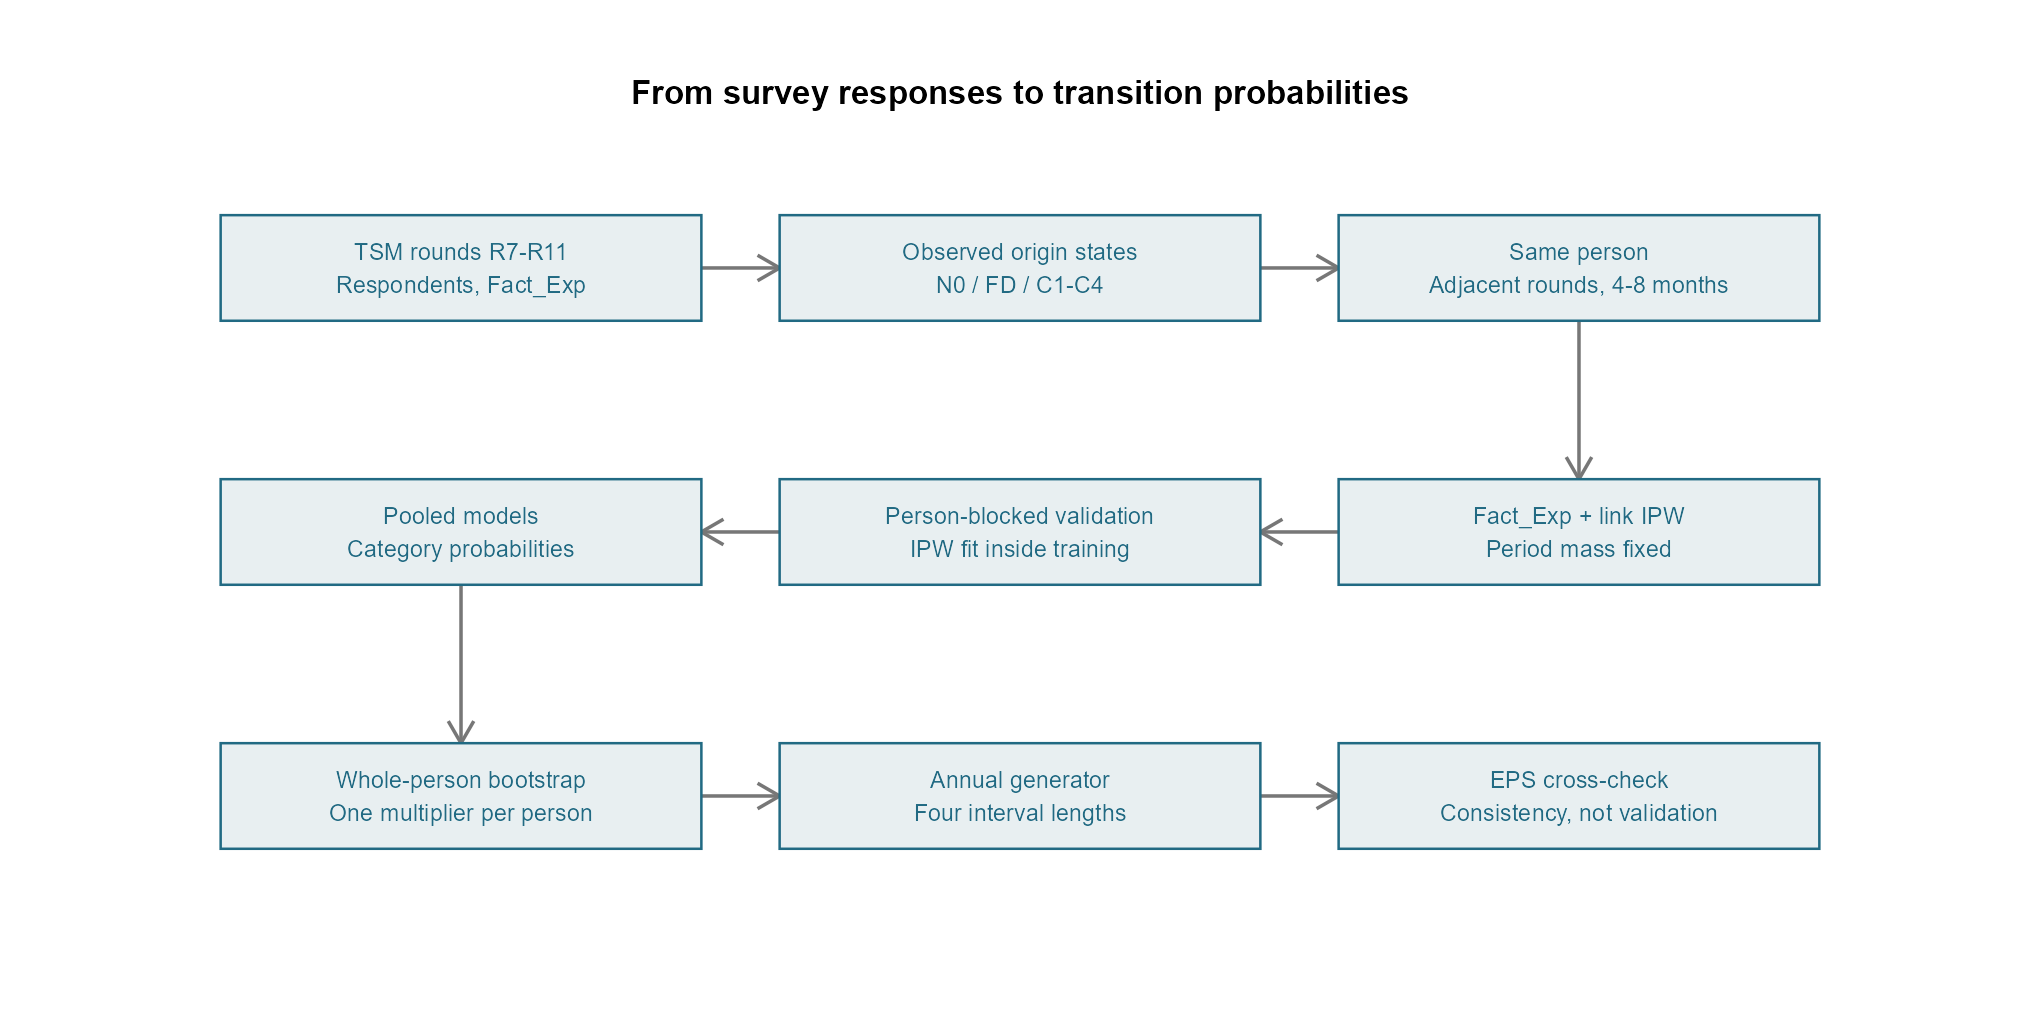

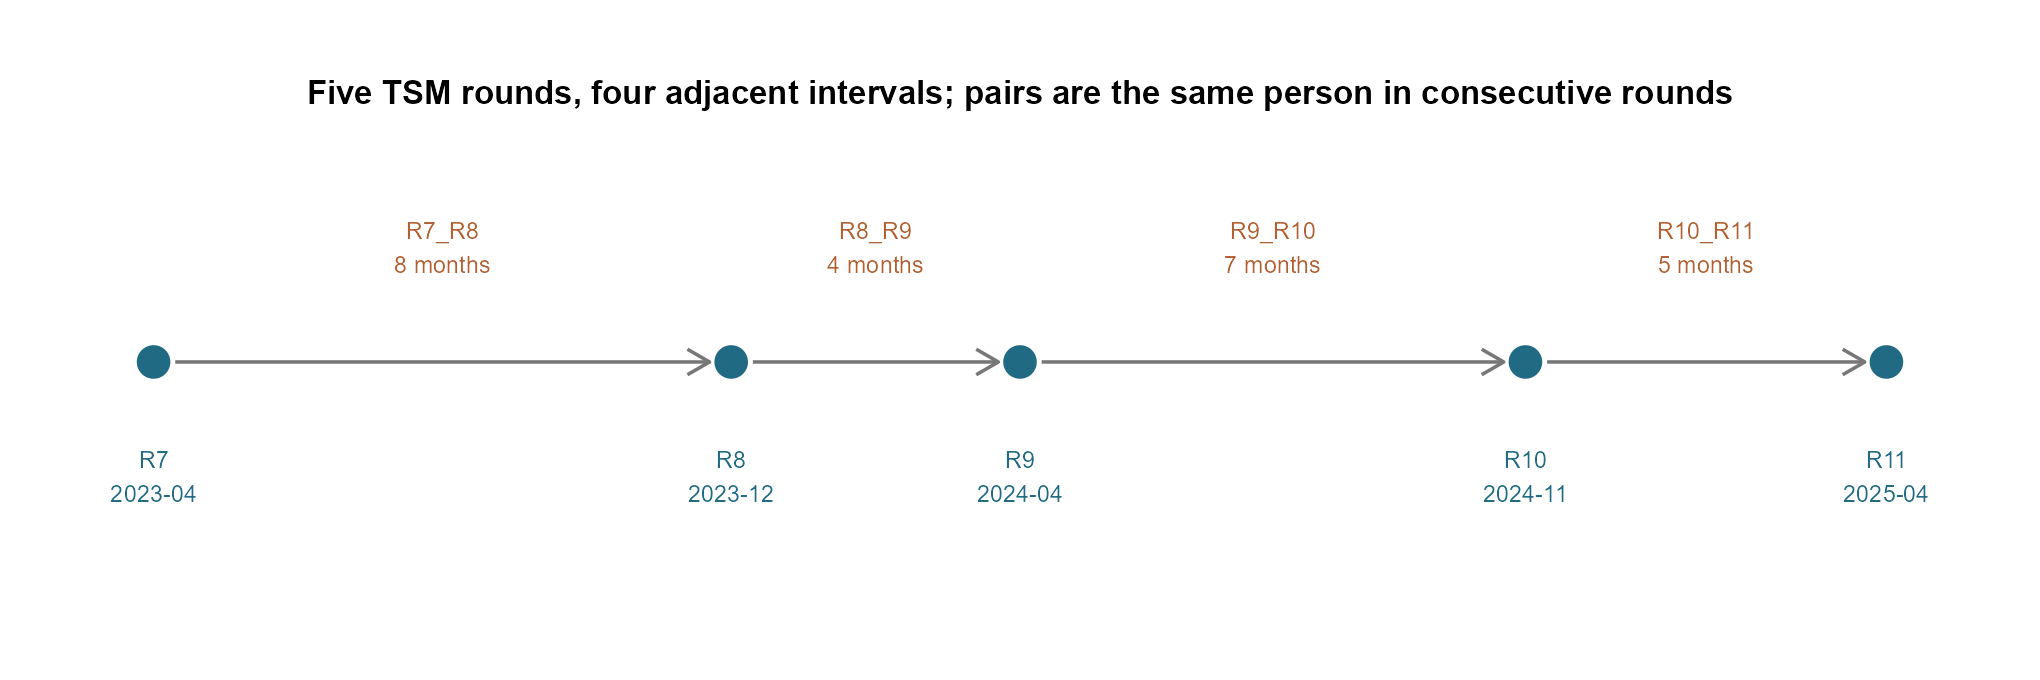

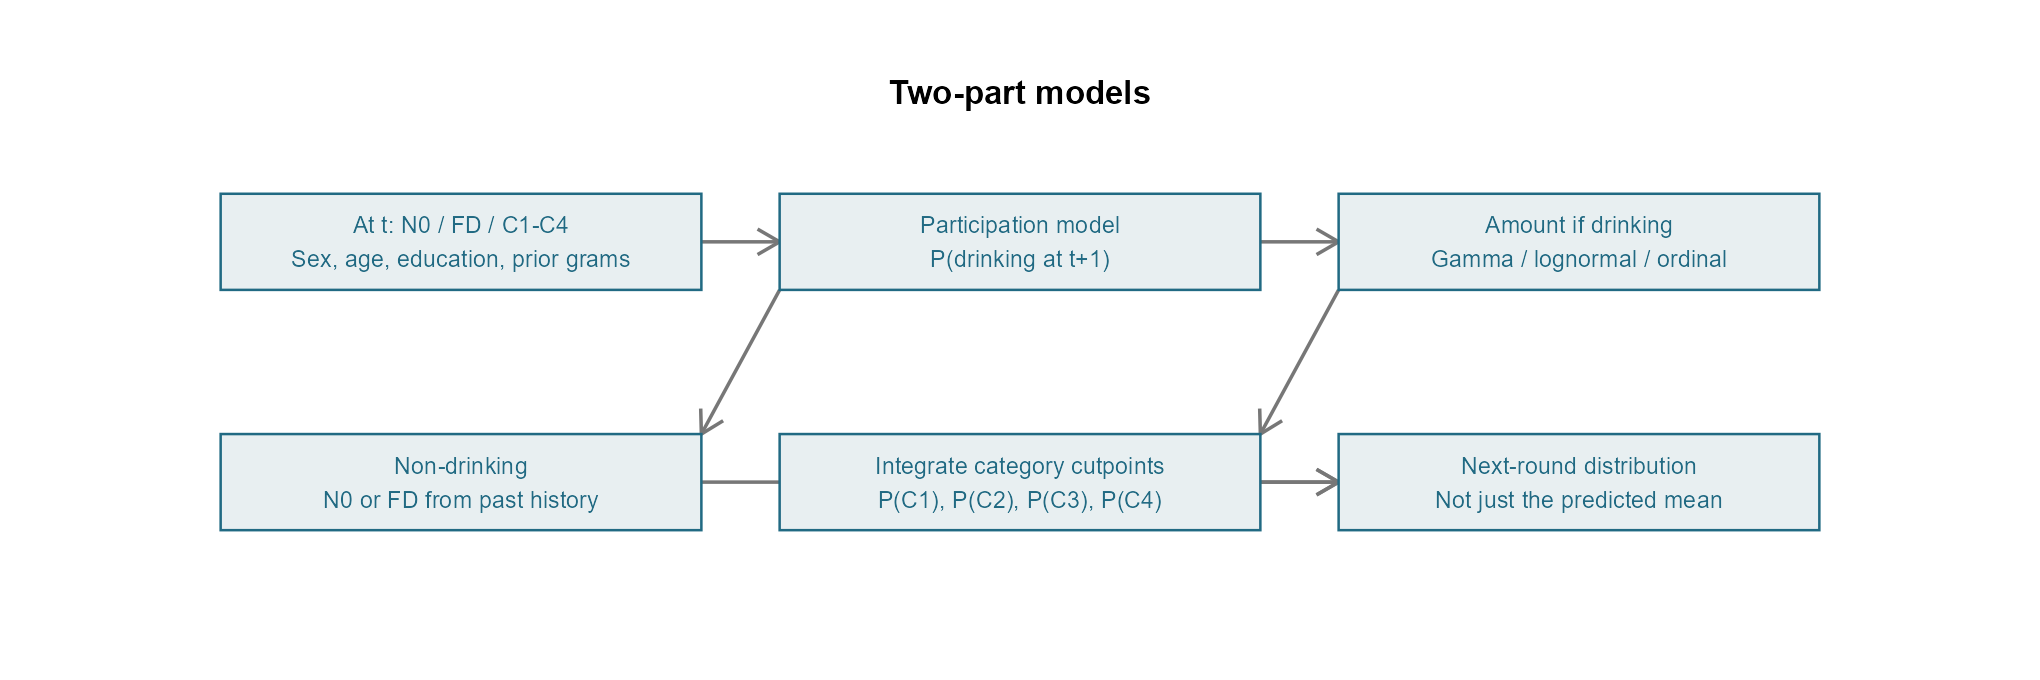

Elapsed: 0.14 minutes


In [4]:
#| label: tsm-data-design
.t0 <- Sys.time()
ts_load()
ts_W <- ts_waves(12)
ts_risk <- ts_make_risk(ts_W)
ts_period_mass <- vapply(ts_periods, function(p) sum(ts_risk$period == p & ts_risk$complete), 1)
names(ts_period_mass) <- ts_periods
ts_ip <- ts_ipw_fit(ts_risk)
ts_d <- ts_ipw_apply(ts_risk, ts_ip)
ts_check(nrow(ts_d) == length(unique(ts_d$row_id)), "One row per person and interval")
ts_check(all(ts_d$wn > 0) && all(is.finite(ts_d$wn)), "Positive finite main weights")
ts_check(!any(ts_d$state0 != "N0" & ts_d$state1 == "N0") && !any(ts_d$state0 == "N0" & ts_d$state1 == "FD"),
 "Observed pairs respect the history-state transition map")
ts_v2 <- ts_v2_regression(ts_W, ts_risk)
ts_save(ts_v2, "v2_regression_check")
ts_check(is.logical(ts_v2$match) && all(ts_v2$match), "v2 regression quantities match")
ts_link <- ts_link_audit(ts_W, ts_risk); ts_save(ts_link, "link_audit")
ts_counts <- as.data.frame(table(period = ts_d$period, sex = ts_d$sex, age_group = ts_d$age_group, state0 = ts_d$state0))
names(ts_counts)[5] <- "n"
ts_save(ts_counts, "row_counts_state0_by_stratum")
ts_cohort <- do.call(rbind, lapply(ts_periods, function(p) {
 r <- ts_risk[ts_risk$period == p, ]; d <- ts_d[ts_d$period == p, ]; tm <- ts_time[ts_time$period == p, ]
 data.frame(period = p, months = tm$months, years = tm$years, risk_set = nrow(r), destination_present = sum(r$destination_present),
   incompatible_links = sum(r$destination_present & !r$compatible), usable_pairs = nrow(d), persons = length(unique(d$id)),
   age_min = min(d$age), age_max = max(d$age), weight_ESS = sum(d$wn)^2 / sum(d$wn^2),
   main_weight = "Origin Fact_Exp + link IPW (stages a and c constant)")
}))
ts_hist_audit <- ts_history_audit(ts_W)
ts_edu_audit <- ts_education_audit(ts_W)
ts_harmonization <- do.call(rbind, lapply(split(ts_W, ts_W$wave), function(d)
 data.frame(wave = d$wave[1], respondents = nrow(d), aged_18_65 = sum(d$age >= 18 & d$age <= 65, na.rm = TRUE),
  current = sum(d$current %in% 1), N0 = sum(d$state %in% "N0"), FD = sum(d$state %in% "FD"),
  C1 = sum(d$cat %in% "C1"), C2 = sum(d$cat %in% "C2"), C3 = sum(d$cat %in% "C3"), C4 = sum(d$cat %in% "C4"),
  signal_1 = sum(d$signal %in% 1), signal_0 = sum(d$signal %in% 0), hed6_1 = sum(d$hed6 %in% 1),
  grams_max = max(d$grams, na.rm = TRUE), prior_use = sum(d$prior_use %in% TRUE))))
ts_save(ts_cohort, "cohort"); ts_save(ts_hist_audit, "abstention_history_audit")
ts_save(ts_edu_audit, "education_rule_audit"); ts_save(ts_harmonization, "harmonization_audit")
ts_save(as.data.frame(table(origin = ts_d$state0)), "origin_counts")
ts_fd_tenure <- ts_fd_tenure_audit(ts_W); ts_save(ts_fd_tenure, "fd_tenure_audit")
ts_show(ts_cohort, "Adjacent-round analysis populations; months between rounds are approximate")
ts_show(data.frame(pairs = nrow(ts_d), persons = length(unique(ts_d$id)), persons_with_two_or_more_pairs = sum(table(ts_d$id) >= 2),
 persons_with_four_pairs = sum(table(ts_d$id) == 4)), "Pairs and distinct people")
ts_show(ts_v2, "Regression against version 2 before the link-compatibility rule")
ts_show(ts_link, "Link audit: destination records present, compatible and used")
ts_show(ts_hist_audit, "Past-only history flags by round; all available ages")
ts_show(ts_fd_tenure, "FD depends on panel tenure: non-drinkers by number of earlier interviews, and FD by months since the last observed drinking")
ts_show(ts_harmonization, "Harmonized wave table by round; counts only")
ts_diagrams()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Weights and inverse probability weighting

The only released weight is the round-specific cross-sectional expansion factor `Fact_Exp`; there is no longitudinal weight, no primary sampling unit and no stratum. The origin weight is combined with the EPS three-stage inverse-probability correction. The three stages are the probability that the origin classification is observed, the probability that the destination record is linked given the origin, and the probability that the destination classification is observed given the link. In TSM the first and third stages are constant: every respondent in the risk set has a complete alcohol module at origin, and every compatible destination record has one too, so only the link stage is estimated. Its model uses the interval, origin state, sex, age group, education, log grams, the typical-quantity signal, the 6+ item, the depression screener, region, employment, partnership, home ownership, the number of earlier interviews and an indicator of entry after round 7.

Observation probabilities have a floor, completed weights are clipped at the training percentiles within each period, and each period keeps the mass of its observed complete pairs, so the pooled data are an analytical mixture of four weighted populations rather than one annual cohort. The link model and the clipping percentiles are learned inside every training fold and every bootstrap replicate, never on the held-out people; the probability floor is a fixed constant. Kish's effective sample size summarises weight dispersion and is not multiplied into any interval.


In [5]:
#| label: tsm-weight-audit
.t0 <- Sys.time()
ts_weight_audit <- do.call(rbind, lapply(split(ts_d, ts_d$period), function(d)
 data.frame(period = d$period[1], min_probability = min(d$p_obs), median_weight = stats::median(d$wn), max_weight = max(d$wn),
  clipped = sum(d$untrimmed != d$wcorrected), weight_ESS = sum(d$wn)^2 / sum(d$wn^2))))
ts_save(ts_weight_audit, "ipw_audit")
ts_kish <- do.call(rbind, lapply(split(ts_d, ts_key(ts_d, c("period", "sex"))), function(d)
 data.frame(period = d$period[1], sex = d$sex[1], n = nrow(d), weight_ESS = sum(d$wn)^2 / sum(d$wn^2),
  kish_design_effect = nrow(d) * sum(d$wn^2) / sum(d$wn)^2)))
# shortcut: the Kish table is displayed only (not in the plan's audit-table list); save it if a CSV is wanted.
ts_show(ts_weight_audit, "Weight diagnostics; ESS reflects weight dispersion only, no PSU or strata exist")
ts_show(ts_kish, "Kish effective sample size and design effect by period and sex; descriptive, not an interval multiplier")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


period,min_probability,median_weight,max_weight,clipped,weight_ESS
R7_R8,0.270,0.521,7.515,18,359.198
R8_R9,0.309,0.428,9.284,18,263.806
R9_R10,0.216,0.531,8.283,24,447.860
R10_R11,0.173,0.539,9.140,18,335.759


period,sex,n,weight_ESS,kish_design_effect
R10_R11,Men,332,139.187,2.385
R10_R11,Women,638,211.387,3.018
R7_R8,Men,330,133.564,2.471
R7_R8,Women,666,245.089,2.717
R8_R9,Men,300,100.444,2.987
R8_R9,Women,601,169.992,3.535
R9_R10,Men,449,186.253,2.411
R9_R10,Women,805,280.252,2.872


Elapsed: 0.00 minutes


## Models and fair comparison

The regression models receive the same information: previous state, log grams at origin for drinkers, sex, age group and their interaction, the interval and education. A uses only the origin-state cells by sex, age group and interval, and JRT_reference is the published specification without grams or education. The common right-hand side of the regression models is

$$
\text{state}_0 + \text{sex}\times\text{age group} + \text{period} + \log g_0 + \text{edu} + \text{edu missing}.
$$

| Model | What it does |
|---|---|
| A | Shrunken empirical matrix: cell counts borrow from sex, period and global margins; shrinkage strength tuned inside training. |
| A_education | The same matrix stratified additionally by education level. |
| Multinomial | Multinomial regression on the five destination classes. |
| Gamma | Two parts: participation at the next round, then a Gamma distribution of grams; class probabilities integrate the fitted distribution between the cutpoints. |
| Lognormal | Same two parts with a lognormal amount. |
| Ordinal_two_part | Participation, then a proportional-odds model over C1–C4. |
| NonPO_two_part | Participation, then a multinomial amount model, to test proportional odds through prediction. |
| Ordinal_single | One proportional-odds model over NC and C1–C4. |
| JRT_reference | The published JRT specification: state × age group, state × sex, sex × age group and period; no grams, no education. |
| Gamma_no_education, Gamma_education_interaction, Lognormal_education_interaction | Education removed or interacted with baseline drinking, sex and age. |
| Lognormal_tsm_extras | The common formula plus the TSM-only origin covariates (signal, 6+ item, depression screener, region, employment, history length). |

The main models compared in every table are A, Multinomial, Gamma, Lognormal, Ordinal_two_part, Ordinal_single and JRT_reference. The parametric amount models "share information" in the sense that a person's predicted distribution is informed by everyone with similar covariates, which allows a positive probability of C3 and C4 even where no such destination was observed; the price is dependence on the assumed shape. Dispersion is estimated with normalised weights, so multiplying every weight by ten must leave the predictions unchanged, and this is checked.

**Log loss, in plain words.** Each model assigns a probability to the category that actually happened. Log loss is minus the logarithm of that probability, averaged over the observed pairs with their weights. Suppose three people are observed: the first stays in C1 and the model gave that outcome probability 0.8, the second moves to NC with probability 0.5, and the third moves to C3 with probability 0.1. Their individual losses are −log 0.8, −log 0.5 and −log 0.1, and the average is the log loss. Exponentiating minus the log loss returns the "typical probability" the model gave to what happened, a geometric mean that is easier to read than the loss itself. The Brier score instead sums squared differences between the probability vector and the observed indicator, and accuracy only asks whether the most probable class was the observed one. All three are computed on held-out people.

**Bootstrap versus cross-validation.** Cross-validation answers "how well does the model predict people it has not seen?": the people are split into five groups, each group is predicted by models trained on the other four, with IPW and shrinkage learned on the training part, and the split is repeated three times with different seeds. The bootstrap answers "how much would the estimates move if a different sample of people had been interviewed?": people are resampled with replacement, all pairs of a person move together, IPW and models are refitted, and the spread of the refitted estimates gives the interval. The first measures predictive quality, the second measures sampling uncertainty; neither replaces the other.

Paired contrasts are differences in log loss between two models on the same held-out pairs, with intervals that treat each person as a cluster; they are conditional on the fitted held-out predictions. Every pair among the main models is reported.


In [6]:
#| label: tsm-model-validation
.t0 <- Sys.time()
ts_tunes <- list(ts_tune(ts_risk, FALSE), ts_tune(ts_risk, TRUE))
ts_k <- vapply(ts_tunes, function(x) x$k, 1)
ts_save(rbind(ts_tunes[[1]]$scores, ts_tunes[[2]]$scores), "full_fit_shrinkage_tuning")
ts_fits <- lapply(stats::setNames(names(ts_models), names(ts_models)), function(nm) ts_fit(ts_d, nm, ts_k[if (nm == "A_education") 2 else 1]))
ts_scale_test <- lapply(c("Gamma", "Lognormal", "Multinomial", "Ordinal_two_part"), function(nm) {
 d <- ts_d; d$wn <- 10 * d$wn
 diff <- max(abs(ts_prob(ts_fits[[nm]], ts_d) - ts_prob(ts_fit(d, nm, ts_k[1]), ts_d)))
 ts_check(diff < 1e-7, paste("Weight-scale invariance", nm))
 data.frame(model = nm, max_absolute_difference = diff)
})
ts_save(do.call(rbind, ts_scale_test), "weight_scale_invariance")
ts_cv_result <- ts_cv(ts_risk)
ts_cvtab <- ts_cv_tables(ts_cv_result)
ts_contrasts <- ts_score_contrasts(ts_cvtab)
ts_save(ts_cv_result$audit, "CV_fold_audit"); ts_save(ts_cv_result$tuning, "CV_inner_tuning")
ts_save(ts_cvtab$scores, "CV_repeated_scores"); ts_save(ts_cvtab$summary, "cv_scores")
ts_save(ts_contrasts, "CV_paired_comparisons")
ts_show(ts_cvtab$summary, "Held-out category scores; lower log loss and Brier are better", 5)
ts_show(ts_contrasts[, 1:8], "Paired comparisons; intervals use person clusters, conditional on held-out predictions", 5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


CV repeat 1/3, fold 1/5 complete
CV repeat 1/3, fold 2/5 complete
CV repeat 1/3, fold 3/5 complete
CV repeat 1/3, fold 4/5 complete
CV repeat 1/3, fold 5/5 complete
CV repeat 2/3, fold 1/5 complete
CV repeat 2/3, fold 2/5 complete
CV repeat 2/3, fold 3/5 complete
CV repeat 2/3, fold 4/5 complete
CV repeat 2/3, fold 5/5 complete
CV repeat 3/3, fold 1/5 complete
CV repeat 3/3, fold 2/5 complete
CV repeat 3/3, fold 3/5 complete
CV repeat 3/3, fold 4/5 complete
CV repeat 3/3, fold 5/5 complete


model,logloss,brier,accuracy
Lognormal,0.53922,0.33817,0.76665
Multinomial,0.54013,0.33814,0.76686
Ordinal_single,0.54054,0.33793,0.76655
NonPO_two_part,0.54149,0.33816,0.76653
Lognormal_tsm_extras,0.54197,0.33958,0.76475
Lognormal_education_interaction,0.54637,0.34339,0.76451
Gamma,0.54837,0.33824,0.76666
Ordinal_two_part,0.55003,0.33850,0.76656
Gamma_no_education,0.55247,0.34077,0.76807
Gamma_education_interaction,0.55805,0.34350,0.76452


model,reference,difference,se_person,lower,upper,relative_geometric_probability_gain_pct,mean_absolute_class_probability_change_pp
Lognormal,Gamma,-0.00915,0.00544,-0.01981,0.00151,0.91943,0.12609
Gamma,A,-0.01125,0.00975,-0.03038,0.00788,1.13161,3.30347
Lognormal,A,-0.02040,0.00728,-0.03467,-0.00614,2.06144,3.27414
NonPO_two_part,Ordinal_two_part,-0.00854,0.00398,-0.01634,-0.00074,0.85797,0.14958
Ordinal_two_part,Gamma,0.00166,0.00388,-0.00594,0.00926,-0.16599,0.18027
Ordinal_single,Gamma,-0.00782,0.00568,-0.01896,0.00332,0.78538,0.36033
Multinomial,Gamma,-0.00824,0.00631,-0.02062,0.00414,0.82744,0.27326
Multinomial,A,-0.01949,0.00742,-0.03404,-0.00495,1.96841,3.31087
Ordinal_two_part,A,-0.00959,0.00943,-0.02809,0.00891,0.96374,3.34375
Ordinal_single,A,-0.01908,0.00657,-0.03195,-0.00620,1.92587,3.20462


Elapsed: 1.36 minutes


## Calibration and the model decision

Calibration compares, for each destination class, the weighted share actually observed with the mean predicted probability, on held-out predictions. The same comparison is repeated within each origin cell, defined by origin state, sex and age group, so that a model that is right on average but wrong for a particular group can be seen; cells with few origin rows are flagged as sparse and should be read with that in mind.

The decision table records which model has the best average log loss and which has the best Brier score, and the paired contrast between Lognormal and A with its interval and its mean change in class probabilities. A contrast whose interval excludes zero separates the two scores clearly; one that includes zero does not, and a clear separation can still be small in practical terms.


In [7]:
#| label: tsm-calibration
.t0 <- Sys.time()
ts_cal <- do.call(rbind, lapply(c("A", "Gamma", "Lognormal", "Ordinal_two_part", "Ordinal_single", "Multinomial"), function(nm) {
 P <- ts_cvtab$prob[[nm]]
 data.frame(model = nm, category = ts_Y,
  observed = vapply(ts_Y, function(s) stats::weighted.mean(ts_d$y1 == s, ts_cvtab$w), 1),
  predicted = colSums(P * ts_cvtab$w) / sum(ts_cvtab$w))
}))
ts_save(ts_cal, "calibration_destination")
ts_show(ts_cal, "Held-out observed and predicted destination shares", 4)
ts_cal_cells <- ts_calibration_cells(ts_cvtab, ts_d)
ts_save(ts_cal_cells, "calibration_by_origin_cell")
ts_cal_show <- ts_cal_cells[!ts_cal_cells$sparse, ]
ts_show(utils::head(ts_cal_show[order(-abs(ts_cal_show$predicted - ts_cal_show$observed)), ], 15),
 "Largest held-out gaps among supported origin cells (n_origin of at least 30)", 4)
ts_la <- which(ts_contrasts$model == "Lognormal" & ts_contrasts$reference == "A")
stopifnot(length(ts_la) == 1)
ts_model_answer <- data.frame(best_logloss = ts_cvtab$summary$model[1],
 best_brier = ts_cvtab$summary$model[which.min(ts_cvtab$summary$brier)],
 lognormal_minus_A = ts_contrasts$difference[ts_la], lower = ts_contrasts$lower[ts_la], upper = ts_contrasts$upper[ts_la],
 mean_absolute_class_probability_change_pp = ts_contrasts$mean_absolute_class_probability_change_pp[ts_la],
 clear_lognormal_A_separation = ts_contrasts$lower[ts_la] > 0 | ts_contrasts$upper[ts_la] < 0)
ts_save(ts_model_answer, "model_decision_summary")
ts_show(ts_model_answer, "Current result, not a predetermined winner", 5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,category,observed,predicted
A,NC,0.4365,0.4347
A,C1,0.5585,0.5600
A,C2,0.0041,0.0039
A,C3,0.0009,0.0011
A,C4,0.0000,0.0003
Gamma,NC,0.4365,0.4369
Gamma,C1,0.5585,0.5607
Gamma,C2,0.0041,0.0019
Gamma,C3,0.0009,0.0004
Gamma,C4,0.0000,0.0001


model,state0,sex,age_group,destination,n_origin,observed,predicted,difference,absolute_difference,relative_difference,sparse
A,FD,Women,60-65,NC,82,0.7161,0.4406,-0.2755,0.2755,-0.3848,FALSE
A,FD,Women,60-65,C1,82,0.2839,0.5587,0.2748,0.2748,0.9682,FALSE
A,C1,Women,60-65,NC,199,0.4276,0.2300,-0.1977,0.1977,-0.4622,FALSE
A,C1,Women,60-65,C1,199,0.5724,0.7639,0.1915,0.1915,0.3346,FALSE
A,FD,Women,45-59,NC,131,0.6235,0.4406,-0.1829,0.1829,-0.2934,FALSE
A,FD,Women,45-59,C1,131,0.3765,0.5587,0.1821,0.1821,0.4838,FALSE
Multinomial,FD,Men,60-65,NC,37,0.5603,0.3891,-0.1712,0.1712,-0.3056,FALSE
A,FD,Men,30-44,C1,30,0.7491,0.5782,-0.1709,0.1709,-0.2281,FALSE
Multinomial,FD,Men,60-65,C1,37,0.4397,0.6099,0.1702,0.1702,0.3871,FALSE
A,FD,Men,30-44,NC,30,0.2509,0.4211,0.1702,0.1702,0.6781,FALSE


best_logloss,best_brier,lognormal_minus_A,lower,upper,mean_absolute_class_probability_change_pp,clear_lognormal_A_separation
Lognormal,Ordinal_single,-0.0204,-0.03467,-0.00614,3.27414,TRUE


Elapsed: 0.00 minutes


## Matrices and whole-person bootstrap intervals

Each matrix row averages the predicted probabilities among the people actually observed in that origin state, keeping their own grams and education. Rows without people are left empty and marked as unsupported; structural zeros, such as N0 to FD, are marked separately. Matrices are reported by period, sex and age group, pooled by sex and age group, pooled over everyone, and by education level. The pooled tables mix the four interval lengths, weighted by their pairs, so they are not probabilities over a defined horizon; the per-interval matrices are the primary TSM product.

Because TSM has no sampling design variables, the only uncertainty computed is the whole-person bootstrap: each replicate resamples people, applies the same multiplier to all pairs of a person, refits the link model, the weights and the outcome models, and recomputes every matrix and the annual generator. Intervals are built on the logit scale from the replicate standard deviation and are bounded at zero and one; rows unsupported in any replicate receive no interval rather than a fabricated one. Any failed replicate stops the inference. A stability table shows how the interval widths change with the number of replicates, and the Gamma and lognormal coefficients are exported with the same intervals.


In [8]:
#| label: tsm-person-inference
.t0 <- Sys.time()
ts_points <- ts_targets(ts_d, ts_fits[ts_main_models])
ts_pool_sexage <- do.call(rbind, lapply(ts_main_models, function(nm)
 ts_matrices(ts_d, ts_prob(ts_fits[[nm]], ts_d), nm, by = c("sex", "age_group"))))
ts_pool_tab <- do.call(rbind, lapply(ts_main_models, function(nm) {
 d <- ts_d; d$pooled <- "All"
 ts_matrices(d, ts_prob(ts_fits[[nm]], d), nm, by = "pooled")
}))
ts_edu_tab <- do.call(rbind, lapply(ts_main_models, function(nm) ts_matrices(ts_d, ts_prob(ts_fits[[nm]], ts_d), nm, by = "edu")))
ts_save(ts_edu_tab, "transition_matrices_education")
ts_show(ts_pool_tab[ts_pool_tab$from == ts_pool_tab$to & ts_pool_tab$model %in% c("A", "Gamma", "Lognormal"), c("model", "from", "n_origin", "estimate", "support")],
 "Pooled staying probabilities to the next round: a mixture of the four 4-8-month intervals weighted by their pairs; point estimates")
ts_ci_models <- c("A", "Gamma", "Lognormal", "Ordinal_single")
ts_person <- ts_bootstrap_person(model_names = ts_ci_models, annual = TRUE)
ts_person_ci <- function(tab) {
 keys <- names(ts_vector(tab))
 reps <- do.call(rbind, lapply(ts_person, function(x) x$target[keys]))
 ci <- cbind(tab, ts_interval(ts_vector(tab), reps))
 ci$interval_status[!ci$model %in% ts_ci_models] <- "not bootstrapped"
 ci
}
ts_ci <- ts_person_ci(ts_points)
ts_save(ts_ci, "transition_matrices_person_CI")
# The two pooled groupings carry different grouping columns; align them before binding.
ts_pool_ci <- ts_person_ci(ts_pool_sexage); ts_all_ci <- ts_person_ci(ts_pool_tab)
ts_pool_ci$pooled <- NA_character_; ts_all_ci$sex <- NA_character_; ts_all_ci$age_group <- NA_character_
ts_pool_ci <- rbind(ts_pool_ci, ts_all_ci[names(ts_pool_ci)])
ts_save(ts_pool_ci, "transition_matrices_pooled_person_CI")
ts_check(any(ts_pool_ci$interval_status == "available"), "Pooled person intervals available")
ts_personmat <- do.call(rbind, lapply(ts_person, function(x) x$target[names(ts_vector(ts_points[ts_points$model %in% ts_ci_models, ]))]))
ts_engine <- ts_coef(ts_fits)
ts_coef_names <- paste(ts_engine$model, ts_engine$component, ts_engine$term, sep = "::")
ts_engine <- cbind(ts_engine, ts_interval(ts_engine$estimate,
 do.call(rbind, lapply(ts_person, function(x) x$coefficients[ts_coef_names])), probability = FALSE))
ts_save(ts_engine, "engine_coefficients_person_CI")
ts_mc <- ts_bootstrap_stability(ts_personmat)
ts_save(ts_mc, "bootstrap_stability")
ts_show(ts_ci[ts_ci$model == "Gamma" & ts_ci$from == "C1" & ts_ci$to == "C1", c("period", "sex", "age_group", "n_origin", "estimate", "lower", "upper", "interval_status")],
 "Example: remaining in C1, Gamma model, whole-person bootstrap")
ts_show(ts_mc, "Bootstrap stability; whole-person replicates with IPW refitted")
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,from,n_origin,estimate,support
A,N0,1592,0.797,observed
A,FD,431,0.433,observed
A,C1,2086,0.779,observed
A,C2,6,0.247,sparse
A,C3,6,0.010,sparse
A,C4,0,NA,unobserved origin
Gamma,N0,1592,0.800,observed
Gamma,FD,431,0.435,observed
Gamma,C1,2086,0.779,observed
Gamma,C2,6,0.128,sparse


Person bootstrap 100/1000; IPW refitted
Person bootstrap 200/1000; IPW refitted
Person bootstrap 300/1000; IPW refitted
Person bootstrap 400/1000; IPW refitted
Person bootstrap 500/1000; IPW refitted
Person bootstrap 600/1000; IPW refitted
Person bootstrap 700/1000; IPW refitted
Person bootstrap 800/1000; IPW refitted
Person bootstrap 900/1000; IPW refitted
Person bootstrap 1000/1000; IPW refitted


period,sex,age_group,n_origin,estimate,lower,upper,interval_status
R10_R11,Men,18-29,23,0.801,0.667,0.890,available
R10_R11,Men,30-44,84,0.795,0.715,0.857,available
R10_R11,Men,45-59,72,0.755,0.654,0.835,available
R10_R11,Men,60-65,54,0.779,0.679,0.854,available
R10_R11,Women,18-29,34,0.790,0.678,0.871,available
R10_R11,Women,30-44,102,0.757,0.683,0.818,available
R10_R11,Women,45-59,103,0.647,0.555,0.730,available
R10_R11,Women,60-65,50,0.543,0.431,0.652,available
R7_R8,Men,18-29,37,0.828,0.722,0.899,available
R7_R8,Men,30-44,65,0.856,0.794,0.901,available


replicates,median_SE_ratio_to_1000,p90_absolute_relative_difference
100,0.981,0.302
250,0.990,0.191
500,0.993,0.112
1000,1.000,0.000


Elapsed: 47.80 minutes


## Transport, earlier history and rank matching

Transport trains the models on three intervals and tests on the fourth, with the test people removed from training, and repeats this for each interval; held-out rows borrow the period effect of the training interval closest in elapsed months, and the link weights of the held-out interval are fitted on training people only. It asks whether what is learned in some periods predicts another period of the same panel; it does not predict a future calendar period.

The history check uses pairs whose origin round has itself a compatible earlier round and compares models with and without the earlier state and grams. If adding the earlier state does not improve held-out prediction after adjustment, the data do not contradict the first-order Markov simplification; they do not prove it either. The Chapman–Kolmogorov diagnostic compares, on three-round cohorts with collapsed states, the direct two-step transition with the product of the two one-step matrices; it is a marginal composition check with a bootstrap interval, not a test.

Rank matching reproduces the margins of the observed panel within each sex and age group by coupling ranks instead of following individuals; comparing its matrix with the observed one shows how much persistence is created by the coupling itself.


In [9]:
#| label: tsm-transport-history
.t0 <- Sys.time()
ts_trans <- ts_transport(); ts_save(ts_trans$scores, "transport_scores"); ts_save(ts_trans$coverage, "transport_support")
ts_trans_text <- names(ts_trans$scores)[vapply(ts_trans$scores, function(v) is.character(v) || is.factor(v), TRUE)]
ts_transport_summary <- do.call(rbind, lapply(split(ts_trans$scores, ts_key(ts_trans$scores, ts_trans_text)), function(z)
 data.frame(z[1, ts_trans_text, drop = FALSE], logloss = stats::weighted.mean(z$logloss, z$weight_sum),
  brier = stats::weighted.mean(z$brier, z$weight_sum), n = sum(z$n), row.names = NULL)))
ts_save(ts_transport_summary, "transport_summary")
ts_show(ts_transport_summary, "Leave-one-interval-out transport; person-disjoint training and test", 4)
ts_hist <- ts_history_check(); ts_save(ts_hist, "adjusted_history_validation")
ts_show(ts_hist, "Does the state one round earlier add predictive information after adjustment?", 5)
ts_ck_tab <- ts_ck(); ts_save(ts_ck_tab, "chapman_kolmogorov_descriptive")
ts_rank_tab <- ts_rank(ts_d); ts_save(ts_rank_tab, "rank_matching_vs_panel")
ts_show(ts_rank_tab[ts_rank_tab$from == "C1" & ts_rank_tab$to == "C1", ],
 "C1 persistence: matched margins, different dependence", 3)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


held_out,proxy_period,model,logloss,brier,n
R10_R11,R8_R9,A,0.5933,0.3571,970
R10_R11,R8_R9,Gamma,0.5475,0.3332,970
R10_R11,R8_R9,JRT_reference,0.5938,0.3602,970
R10_R11,R8_R9,Lognormal,0.5408,0.3334,970
R10_R11,R8_R9,Multinomial,0.5408,0.3329,970
R10_R11,R8_R9,Ordinal_single,0.5530,0.3328,970
R10_R11,R8_R9,Ordinal_two_part,0.5395,0.3331,970
R7_R8,R9_R10,A,0.5474,0.3490,996
R7_R8,R9_R10,Gamma,0.5158,0.3330,996
R7_R8,R9_R10,JRT_reference,0.5449,0.3459,996


model,n_pairs,n_persons,difference_history_minus_current,lower,upper,population
Gamma,2147,1153,0.08088,-0.07032,0.23208,pairs with a compatible earlier wave; person-cluster Taylor; conditional OOF comparison
Gamma_education_interaction,2147,1153,0.08082,-0.07146,0.23311,pairs with a compatible earlier wave; person-cluster Taylor; conditional OOF comparison


period,source,from,to,probability
R7_R8,Observed_panel,C1,C1,0.788
R7_R8,Rank_matching,C1,C1,0.934
R8_R9,Observed_panel,C1,C1,0.692
R8_R9,Rank_matching,C1,C1,0.852
R9_R10,Observed_panel,C1,C1,0.849
R9_R10,Rank_matching,C1,C1,1.000
R10_R11,Observed_panel,C1,C1,0.754
R10_R11,Rank_matching,C1,C1,0.906


Elapsed: 0.39 minutes


## Annual probabilities: an additional modelling layer

The four intervals have different lengths. A single continuous-time generator with non-negative off-diagonal rates is fitted to all four jointly, each with its elapsed years, and the annual matrix is its exponential:

$$
P(\Delta)=\exp(Q\Delta),\qquad P(1)=\exp(Q).
$$

**What the annual staying probability means.** Take two states, drinking and not drinking, and suppose the observed matrix over an interval of half a year shows that a drinker is still a drinker at the end with probability 0.9. The annual staying probability is not 0.9 squared, because during the year the person can leave and come back; the generator describes the rates of leaving and returning per unit time, and the annual matrix is what those rates produce over one year. At 12 g per drink C4 is reachable only by women above 60 g/day and has almost no origins, so its annual row is either not estimated (an unobserved origin, reported with a blank estimate and no interval) or rests on a handful of pairs. The rows that rest on few people are C2 and C3, flagged sparse: their annual probabilities are model-derived numbers that depend on the penalty and the starting values of the optimiser, and their bootstrap intervals are wide. The sensitivity table repeats the fit with a weak, a primary and a stronger penalty and reports the largest change in any annual probability; large changes keep this layer exploratory. Time-homogeneous rates are an assumption, and the four intervals test it: each interval is also fitted alone, and a table compares its reconstruction error and staying probabilities with the joint generator's. A joint error well above the single-interval errors means the intervals imply different rates, so the annual matrix is a compromise between them, and short windows turn within-year fluctuation of infrequent drinkers into annual exits. Annual intervals come from the bootstrap replicates and condition on the primary penalty and start.


In [10]:
#| label: tsm-annual-layer
.t0 <- Sys.time()
# Single start 0.05 as in EPS so the point estimate matches the bootstrap replicates; the three-start grid is in the sensitivity table.
ts_annual_full <- lapply(ts_fits[c("A", "Gamma", "Lognormal")], function(f) ts_annual(ts_d, f, starts = .05, check_gradient = TRUE))
ts_ann_point <- unlist(lapply(ts_annual_full, function(x) as.vector(x$P)))
ts_ann_rep <- do.call(rbind, lapply(ts_person, function(x) x$annual))
ts_ann <- do.call(rbind, lapply(names(ts_annual_full), function(nm) {
 z <- ts_annual_full[[nm]]
 ts_check(max(abs(rowSums(z$P) - 1)) < 1e-8 && min(z$P) > -1e-10, paste("Annual stochastic matrix", nm))
 ts_check(z$semigroup_error < 1e-8, paste("Annual semigroup", nm))
 data.frame(model = nm, from = rep(ts_ST, 6), to = rep(ts_ST, each = 6), estimate = as.vector(z$P),
  weighted_reconstruction_RMSE = z$rmse, optimizer_code = z$convergence, gradient_error = z$gradient_error, semigroup_error = z$semigroup_error)
}))
ts_ann <- cbind(ts_ann, ts_interval(ts_ann_point, ts_ann_rep))
# Rows whose origin state has no observed pairs are penalty-driven, not estimated: report them as unsupported.
ts_ann_support <- function(tab, d) {
 n0 <- table(factor(as.character(d$state0), levels = unique(tab$from)))
 tab$n_origin <- as.integer(n0[as.character(tab$from)])
 tab$support <- ifelse(tab$n_origin == 0, "unobserved origin", ifelse(tab$n_origin < 30, "sparse", "observed"))
 bad <- tab$n_origin == 0
 for (v in intersect(c("estimate", "se", "lower", "upper"), names(tab))) tab[[v]][bad] <- NA_real_
 if ("interval_status" %in% names(tab)) tab$interval_status[bad] <- "unobserved origin"
 tab
}
ts_ann <- ts_ann_support(ts_ann, ts_d)
ts_save(ts_ann, "annual_pooled_matrices_person_CI")
ts_ann_sens <- do.call(rbind, lapply(c("A", "Gamma", "Lognormal"), function(nm) do.call(rbind, lapply(c(1e-5, 5e-5, 2e-4), function(pen) {
 z <- ts_annual(ts_d, ts_fits[[nm]], lambda = pen)
 data.frame(model = nm, penalty = pen, weighted_reconstruction_RMSE = z$rmse, start_objective_range = z$start_objective_range,
  max_annual_difference = max(abs(z$P - ts_annual_full[[nm]]$P)), optimizer_code = z$convergence)
}))))
ts_save(ts_ann_sens, "annual_generator_sensitivity")
# Time-homogeneity check: each interval fitted alone (primary penalty and start) against the joint generator.
ts_ann_intervals <- do.call(rbind, lapply(c("A", "Gamma", "Lognormal"), function(nm) do.call(rbind, lapply(ts_periods, function(p) {
 ii <- ts_d$period == p; z <- ts_annual(ts_d[ii, ], ts_fits[[nm]], starts = .05)
 P <- ts_prob(ts_fits[[nm]], ts_d[ii, ]); yrs <- ts_time$years[match(p, ts_time$period)]
 pj <- ts_expm(ts_annual_full[[nm]]$Q * yrs); pj5 <- cbind(pj[, 1] + pj[, 2], pj[, 3:6])
 err <- 0; mass <- 0
 for (s in seq_along(ts_ST)) { jj <- as.character(ts_d$state0[ii]) == ts_ST[s]; if (any(jj)) {
  target <- colSums(P[jj, , drop = FALSE] * ts_d$wn[ii][jj]) / sum(ts_d$wn[ii][jj])
  err <- err + sum(ts_d$wn[ii][jj]) * sum((pj5[s, ] - target)^2); mass <- mass + sum(ts_d$wn[ii][jj]) } }
 data.frame(model = nm, period = p, years = yrs, single_fit_RMSE = z$rmse, joint_fit_within_interval_RMSE = sqrt(err / mass),
  single_fit_annual_stay_N0 = z$P[1, 1], single_fit_annual_stay_FD = z$P[2, 2], single_fit_annual_stay_C1 = z$P[3, 3],
  joint_annual_stay_N0 = ts_annual_full[[nm]]$P[1, 1], joint_annual_stay_FD = ts_annual_full[[nm]]$P[2, 2],
  joint_annual_stay_C1 = ts_annual_full[[nm]]$P[3, 3], optimizer_code = z$convergence)
}))))
ts_save(ts_ann_intervals, "annual_interval_fits")
ts_show(ts_ann[ts_ann$from == ts_ann$to, c("model", "from", "to", "n_origin", "support", "estimate", "lower", "upper", "interval_status")],
 "Annual staying probabilities: model-derived, pooled; whole-person bootstrap intervals; unobserved origins are not estimated")
ts_show(ts_ann_sens, "Annual reconstruction sensitivity to penalty and restarts", 5)
ts_show(ts_ann_intervals[, c("model", "period", "years", "single_fit_RMSE", "joint_fit_within_interval_RMSE",
 "single_fit_annual_stay_N0", "joint_annual_stay_N0", "single_fit_annual_stay_C1", "joint_annual_stay_C1")],
 "Each interval fitted alone versus the joint generator: a time-homogeneity check; C2-C4 rows are not shown because they are penalty-driven", 4)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


model,from,to,n_origin,support,estimate,lower,upper,interval_status
A,N0,N0,1592,observed,0.593,0.517,0.664,available
A,FD,FD,431,observed,0.275,0.229,0.327,available
A,C1,C1,2086,observed,0.736,0.700,0.769,available
A,C2,C2,6,sparse,0.038,0.000,0.994,available
A,C3,C3,6,sparse,0.007,0.000,1.000,available
A,C4,C4,0,unobserved origin,NA,NA,NA,unobserved origin
Gamma,N0,N0,1592,observed,0.591,0.517,0.662,available
Gamma,FD,FD,431,observed,0.275,0.230,0.324,available
Gamma,C1,C1,2086,observed,0.738,0.703,0.770,available
Gamma,C2,C2,6,sparse,0.011,0.000,1.000,available


model,penalty,weighted_reconstruction_RMSE,start_objective_range,max_annual_difference,optimizer_code
A,1e-05,0.06225,0.00005,0.04114,0
A,5e-05,0.06245,0.00000,0.06614,0
A,2e-04,0.06304,0.00000,0.01866,0
Gamma,1e-05,0.07619,0.00003,0.21359,0
Gamma,5e-05,0.07615,0.00001,0.09040,0
Gamma,2e-04,0.07650,0.00000,0.01241,0
Lognormal,1e-05,0.07513,0.00015,0.14763,0
Lognormal,5e-05,0.07521,0.00001,0.07097,0
Lognormal,2e-04,0.07566,0.00000,0.00990,0


model,period,years,single_fit_RMSE,joint_fit_within_interval_RMSE,single_fit_annual_stay_N0,joint_annual_stay_N0,single_fit_annual_stay_C1,joint_annual_stay_C1
A,R7_R8,0.6667,0.0099,0.0416,0.6547,0.5926,0.6991,0.7362
A,R8_R9,0.3333,0.0137,0.0911,0.4666,0.5926,0.6675,0.7362
A,R9_R10,0.5833,0.0068,0.0696,0.6060,0.5926,0.7804,0.7362
A,R10_R11,0.4167,0.0092,0.0292,0.5760,0.5926,0.7062,0.7362
Gamma,R7_R8,0.6667,0.0124,0.0561,0.6571,0.5914,0.7225,0.7381
Gamma,R8_R9,0.3333,0.0066,0.1144,0.5354,0.5914,0.6182,0.7381
Gamma,R9_R10,0.5833,0.0078,0.0718,0.5686,0.5914,0.8020,0.7381
Gamma,R10_R11,0.4167,0.0116,0.0517,0.6094,0.5914,0.6819,0.7381
Lognormal,R7_R8,0.6667,0.0119,0.0558,0.6570,0.5916,0.7186,0.7343
Lognormal,R8_R9,0.3333,0.0062,0.1132,0.5353,0.5916,0.6170,0.7343


Elapsed: 0.21 minutes


## Cross-check against EPS

The EPS notebook exports annual matrices for A, Gamma and Lognormal with design-based intervals, and the observed-origin matrices of its two intervals. Three comparisons are made with aggregates only. First, the annual staying probabilities of the two panels are placed side by side, each with its own interval. Second, a generator is recovered from each EPS annual matrix, projected to the TSM interval lengths and scored on the observed TSM pairs, next to the TSM models' in-sample and held-out scores and an origin-only TSM matrix, which is the like-for-like reference because the EPS projection also conditions on the origin state alone. Third, the TSM generator is projected to the EPS interval lengths and compared with the EPS observed-origin pooled matrices on the five collapsed destinations; the FD origin is flagged as not comparable, because TSM FD and EPS FD are different constructs.

This is external consistency, not validation. The populations differ, the periods differ, the instruments differ in wording and recall window, and the TSM intervals are months while the EPS intervals are years, so agreement does not establish that either engine is right and disagreement does not identify which one is wrong.


In [11]:
#| label: tsm-eps-crosscheck
.t0 <- Sys.time()
ts_cross <- ts_crosscheck_eps(ts_d, ts_fits, ts_annual_full, cvtab = ts_cvtab, annual_ci = ts_ann)
ts_unobserved <- names(which(table(factor(as.character(ts_d$state0), levels = ts_ST)) == 0))
ts_j <- match(paste(ts_cross$annual$model, ts_cross$annual$from), paste(ts_ann$model, ts_ann$from))
ts_cross$annual$n_origin <- ifelse(ts_cross$annual$source == "TSM", ts_ann$n_origin[ts_j], NA_integer_)
ts_cross$annual$support <- ifelse(ts_cross$annual$source == "TSM", ts_ann$support[ts_j], "EPS")
ts_cross$annual$comparable <- ts_cross$annual$from != "FD"   # TSM FD drank months earlier; EPS FD abstained for years
ts_bad <- ts_cross$annual$source == "TSM" & ts_cross$annual$from %in% ts_unobserved
ts_cross$annual$estimate[ts_bad] <- NA_real_; ts_cross$annual$lower[ts_bad] <- NA_real_; ts_cross$annual$upper[ts_bad] <- NA_real_
# Origin-only TSM baseline: the EPS projection also conditions on the origin state alone, so this is its like-for-like reference.
ts_origin_only <- local({
 w <- ts_d$wn; m <- tapply(w, list(factor(as.character(ts_d$state0), levels = ts_ST), ts_d$y1), sum); m[is.na(m)] <- 0
 m <- m / rowSums(m); m[!is.finite(m)] <- 0
 P <- m[as.character(ts_d$state0), , drop = FALSE]; loss <- ts_loss(P, ts_d$y1)
 one <- function(ii, label) data.frame(source = "TSM_origin_only_insample", model = "origin_only", period = label,
  logloss = stats::weighted.mean(loss$logloss[ii], w[ii]), brier = stats::weighted.mean(loss$brier[ii], w[ii]), n = length(ii), recovery_rmse = NA_real_)
 rbind(one(seq_len(nrow(ts_d)), "All"), do.call(rbind, lapply(ts_periods, function(p) one(which(ts_d$period == p), p))))
})
ts_cross$projection_eps_to_tsm <- rbind(ts_cross$projection_eps_to_tsm, ts_origin_only)
ts_save(ts_cross$annual, "eps_crosscheck_annual")
ts_save(ts_cross$projection_eps_to_tsm, "eps_crosscheck_projection_eps_to_tsm")
ts_save(ts_cross$projection_eps_matrices, "eps_crosscheck_projection_eps_matrices")
ts_save(ts_cross$projection_tsm_to_eps, "eps_crosscheck_projection_tsm_to_eps")
ts_save(ts_cross$projection_tsm_to_eps_summary, "eps_crosscheck_projection_tsm_to_eps_summary")
ts_show(ts_cross$annual[ts_cross$annual$from == ts_cross$annual$to, ],
 "Annual staying probabilities, TSM and EPS, each with its own interval; external consistency, not validation")
ts_show(ts_cross$projection_eps_to_tsm, "EPS generators projected to the TSM intervals and scored on TSM pairs, next to the TSM models", 4)
ts_show(ts_cross$projection_tsm_to_eps_summary, "TSM generators projected to the EPS interval lengths versus the EPS observed-origin pooled matrices", 4)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


source,model,from,to,estimate,lower,upper,staying,n_origin,support,comparable
TSM,A,N0,N0,0.593,0.517,0.664,TRUE,1592,observed,TRUE
TSM,A,FD,FD,0.275,0.229,0.327,TRUE,431,observed,FALSE
TSM,A,C1,C1,0.736,0.700,0.769,TRUE,2086,observed,TRUE
TSM,A,C2,C2,0.038,0.000,0.994,TRUE,6,sparse,TRUE
TSM,A,C3,C3,0.007,0.000,1.000,TRUE,6,sparse,TRUE
TSM,A,C4,C4,NA,NA,NA,TRUE,0,unobserved origin,TRUE
EPS,A,N0,N0,0.913,0.903,0.922,TRUE,NA,EPS,TRUE
EPS,A,FD,FD,0.869,0.822,0.905,TRUE,NA,EPS,FALSE
EPS,A,C1,C1,0.819,0.793,0.841,TRUE,NA,EPS,TRUE
EPS,A,C2,C2,0.524,0.346,0.696,TRUE,NA,EPS,TRUE


source,model,period,logloss,brier,n,recovery_rmse
EPS_projection,A,All,0.7637,0.4325,4121,0.0039
EPS_projection,A,R7_R8,0.6663,0.3873,996,0.0039
EPS_projection,A,R8_R9,0.9032,0.4951,901,0.0039
EPS_projection,A,R9_R10,0.7259,0.4167,1254,0.0039
EPS_projection,A,R10_R11,0.7830,0.4413,970,0.0039
EPS_projection,Gamma,All,0.7608,0.4315,4121,0.0040
EPS_projection,Gamma,R7_R8,0.6630,0.3860,996,0.0040
EPS_projection,Gamma,R8_R9,0.9000,0.4936,901,0.0040
EPS_projection,Gamma,R9_R10,0.7242,0.4163,1254,0.0040
EPS_projection,Gamma,R10_R11,0.7793,0.4401,970,0.0040


model,eps_period,years,cells_included,cells,weighted_RMSE,max_absolute_difference
A,VI_VII,3.671,supported origins,20,0.1978,0.3822
A,VII_VIII,4.030,supported origins,25,0.2595,0.5247
Gamma,VI_VII,3.671,supported origins,20,0.1983,0.3845
Gamma,VII_VIII,4.030,supported origins,25,0.2600,0.5270
Lognormal,VI_VII,3.671,supported origins,20,0.1976,0.3835
Lognormal,VII_VIII,4.030,supported origins,25,0.2592,0.5260
A,VI_VII,3.671,excluding FD origin,20,0.1978,0.3822
A,VII_VIII,4.030,excluding FD origin,20,0.2597,0.5247
Gamma,VI_VII,3.671,excluding FD origin,20,0.1983,0.3845
Gamma,VII_VIII,4.030,excluding FD origin,20,0.2601,0.5270


Elapsed: 0.02 minutes


## Primary result: merged C3 + C4 (C3plus)

Since 2026-10-26 this merged variant is the headline result of the notebook; the six-state matrices above remain as detail. The SIMAH microsimulation and the NESARC-based transition literature it draws on use a top category that merges the two highest volume levels. The variant here merges C3 and C4 into C3plus at origin and destination, refits A, Lognormal and Ordinal_single, repeats the cross-validation (one repeat), the pooled matrices and the annual layer, and places the staying probabilities next to the six-state ones. The scores are not comparable across variants because the outcome classes differ; the matrices show what the merge does to the top row.


In [12]:
#| label: tsm-merged-C3plus
.t0 <- Sys.time()
ts_merged <- ts_merged_variant(ts_risk)
ts_save(ts_merged$cv_scores, "merged_C3plus_cv_scores")
ts_save(ts_merged$pooled, "merged_C3plus_pooled_matrices")
ts_merged$annual <- ts_ann_support(ts_merged$annual, ts_merged$d)
ts_save(ts_merged$annual, "merged_C3plus_annual")
ts_stay6 <- ts_pool_tab[ts_pool_tab$from == ts_pool_tab$to & ts_pool_tab$model %in% unique(ts_merged$pooled$model), c("model", "from", "n_origin", "estimate")]
ts_stay_m <- ts_merged$pooled[ts_merged$pooled$from == ts_merged$pooled$to, c("model", "from", "n_origin", "estimate")]
names(ts_stay6)[2:4] <- paste0("six_state_", names(ts_stay6)[2:4]); names(ts_stay_m)[2:4] <- paste0("merged_", names(ts_stay_m)[2:4])
ts_stay6$row <- stats::ave(seq_len(nrow(ts_stay6)), ts_stay6$model, FUN = seq_along)
ts_stay_m$row <- stats::ave(seq_len(nrow(ts_stay_m)), ts_stay_m$model, FUN = seq_along)
ts_show(merge(ts_stay6, ts_stay_m, by = c("model", "row"), all = TRUE)[, -2],
 "Pooled staying probabilities side by side: six states versus merged C3plus")
ts_show(ts_merged$cv_scores, "Merged-variant held-out scores; not comparable with the six-state scores", 5)
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete


model,six_state_from,six_state_n_origin,six_state_estimate,merged_from,merged_n_origin,merged_estimate
A,N0,1592,0.797,N0,1592,0.797
A,FD,431,0.433,FD,431,0.434
A,C1,2086,0.779,C1,2086,0.779
A,C2,6,0.247,C2,6,0.252
A,C3,6,0.010,C3plus,6,0.012
A,C4,0,NA,NA,NA,NA
Lognormal,N0,1592,0.800,N0,1592,0.800
Lognormal,FD,431,0.435,FD,431,0.435
Lognormal,C1,2086,0.774,C1,2086,0.774
Lognormal,C2,6,0.133,C2,6,0.133


model,logloss,brier,accuracy
Ordinal_single,0.54081,0.33944,0.76446
Lognormal,0.54202,0.33940,0.76382
A,0.55760,0.35067,0.76613


Elapsed: 0.18 minutes


## Sensitivities

Conversion: every main model is refitted at 15.7 g per drink, and the pooled matrices at that conversion are exported; the difference measures how much classification depends on drink size and does not say which size is correct. Upper band: the open "ten or more" band is set to sixteen drinks instead of ten. Weights: base weights alone, base weights trimmed at the same percentiles, untrimmed IPW weights and the primary trimmed IPW weights, so the inverse-probability correction is separated from the trimming. Education: the strict and reached rules replace the lenient one, with cross-validated scores for A and Lognormal and pooled matrices. Link rule: the strict EPS age bounds replace the primary widened bounds, for destination links and for the history chain, with their own link audit, the pairs retained, cross-validated scores and pooled matrices. Typical-quantity signal: its weighted share by destination category and a person-clustered regression on destination, sex, age group, origin signal and period; the 6+ item is tabulated by destination category and by origin state.


CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete
CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete
CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete


CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete
CV repeat 1/1, fold 1/5 complete
CV repeat 1/1, fold 2/5 complete
CV repeat 1/1, fold 3/5 complete
CV repeat 1/1, fold 4/5 complete
CV repeat 1/1, fold 5/5 complete


grams_per_drink,model,quantity,probability
12.0,A,Drinking_t1,0.5646
12.0,A,Escalation_from_C1,0.0066
12.0,A,C3_C4_t1,0.0010
12.0,Multinomial,Drinking_t1,0.5623
12.0,Multinomial,Escalation_from_C1,0.0062
12.0,Multinomial,C3_C4_t1,0.0011
12.0,Gamma,Drinking_t1,0.5618
12.0,Gamma,Escalation_from_C1,0.0039
12.0,Gamma,C3_C4_t1,0.0005
12.0,Lognormal,Drinking_t1,0.5618


scenario,model,quantity,probability
top_16_drinks,A,Drinking_t1,0.5647
top_16_drinks,A,Escalation_from_C1,0.0066
top_16_drinks,A,C3_C4_t1,0.0018
top_16_drinks,Gamma,Drinking_t1,0.5617
top_16_drinks,Gamma,Escalation_from_C1,0.0043
top_16_drinks,Gamma,C3_C4_t1,0.0005
top_16_drinks,Lognormal,Drinking_t1,0.5617
top_16_drinks,Lognormal,Escalation_from_C1,0.0086
top_16_drinks,Lognormal,C3_C4_t1,0.0019


scenario,current_t1,C3_C4_t1,weight_ESS
base_only,0.5656,6e-04,1181.419
base_trimmed,0.5659,4e-04,1482.509
IPW_untrimmed,0.5592,6e-04,1116.372
base_plus_IPW,0.5618,5e-04,1397.461


rule,model,quantity,probability
lenient,A,Drinking_t1,0.5646
lenient,A,Escalation_from_C1,0.0066
lenient,A,C3_C4_t1,0.0010
lenient,Lognormal,Drinking_t1,0.5618
lenient,Lognormal,Escalation_from_C1,0.0084
lenient,Lognormal,C3_C4_t1,0.0018
strict,A,Drinking_t1,0.5644
strict,A,Escalation_from_C1,0.0066
strict,A,C3_C4_t1,0.0010
strict,Lognormal,Drinking_t1,0.5616


variant,model,logloss,brier,accuracy,pairs,persons
lenient,Lognormal,0.54228,0.33936,0.76388,4121,1915
lenient,A,0.55831,0.35071,0.76619,4121,1915
strict,Lognormal,0.54251,0.33998,0.76350,4121,1915
strict,A,0.55792,0.35052,0.76637,4121,1915
reached,Lognormal,0.54259,0.33906,0.76329,4121,1915
reached,A,0.55882,0.35078,0.76608,4121,1915


variant,model,logloss,brier,accuracy,pairs,persons
primary_bounds_tolerance_1,Lognormal,0.54228,0.33936,0.76388,4121,1915
primary_bounds_tolerance_1,A,0.55831,0.35071,0.76619,4121,1915
strict_EPS_bounds,Lognormal,0.52778,0.33099,0.76937,3888,1845
strict_EPS_bounds,A,0.54690,0.34267,0.77202,3888,1845


variant,model,quantity,probability
primary_bounds_tolerance_1,A,Drinking_t1,0.5646
primary_bounds_tolerance_1,A,Escalation_from_C1,0.0066
primary_bounds_tolerance_1,A,C3_C4_t1,0.0010
primary_bounds_tolerance_1,Lognormal,Drinking_t1,0.5618
primary_bounds_tolerance_1,Lognormal,Escalation_from_C1,0.0084
primary_bounds_tolerance_1,Lognormal,C3_C4_t1,0.0018
strict_EPS_bounds,A,Drinking_t1,0.5647
strict_EPS_bounds,A,Escalation_from_C1,0.0070
strict_EPS_bounds,A,C3_C4_t1,0.0007
strict_EPS_bounds,Lognormal,Drinking_t1,0.5618


level,category,sex,n,share_hed6
destination,C1,Men,914,0.382
destination,C1,Women,1131,0.213
destination,C2,Men,5,0.387
destination,C2,Women,9,0.824
destination,C3,Men,2,1.000
destination,C3,Women,1,1.000
destination,NC,Men,490,0.000
destination,NC,Women,1569,0.000
origin,N0,All,1592,0.000
origin,FD,All,431,0.000


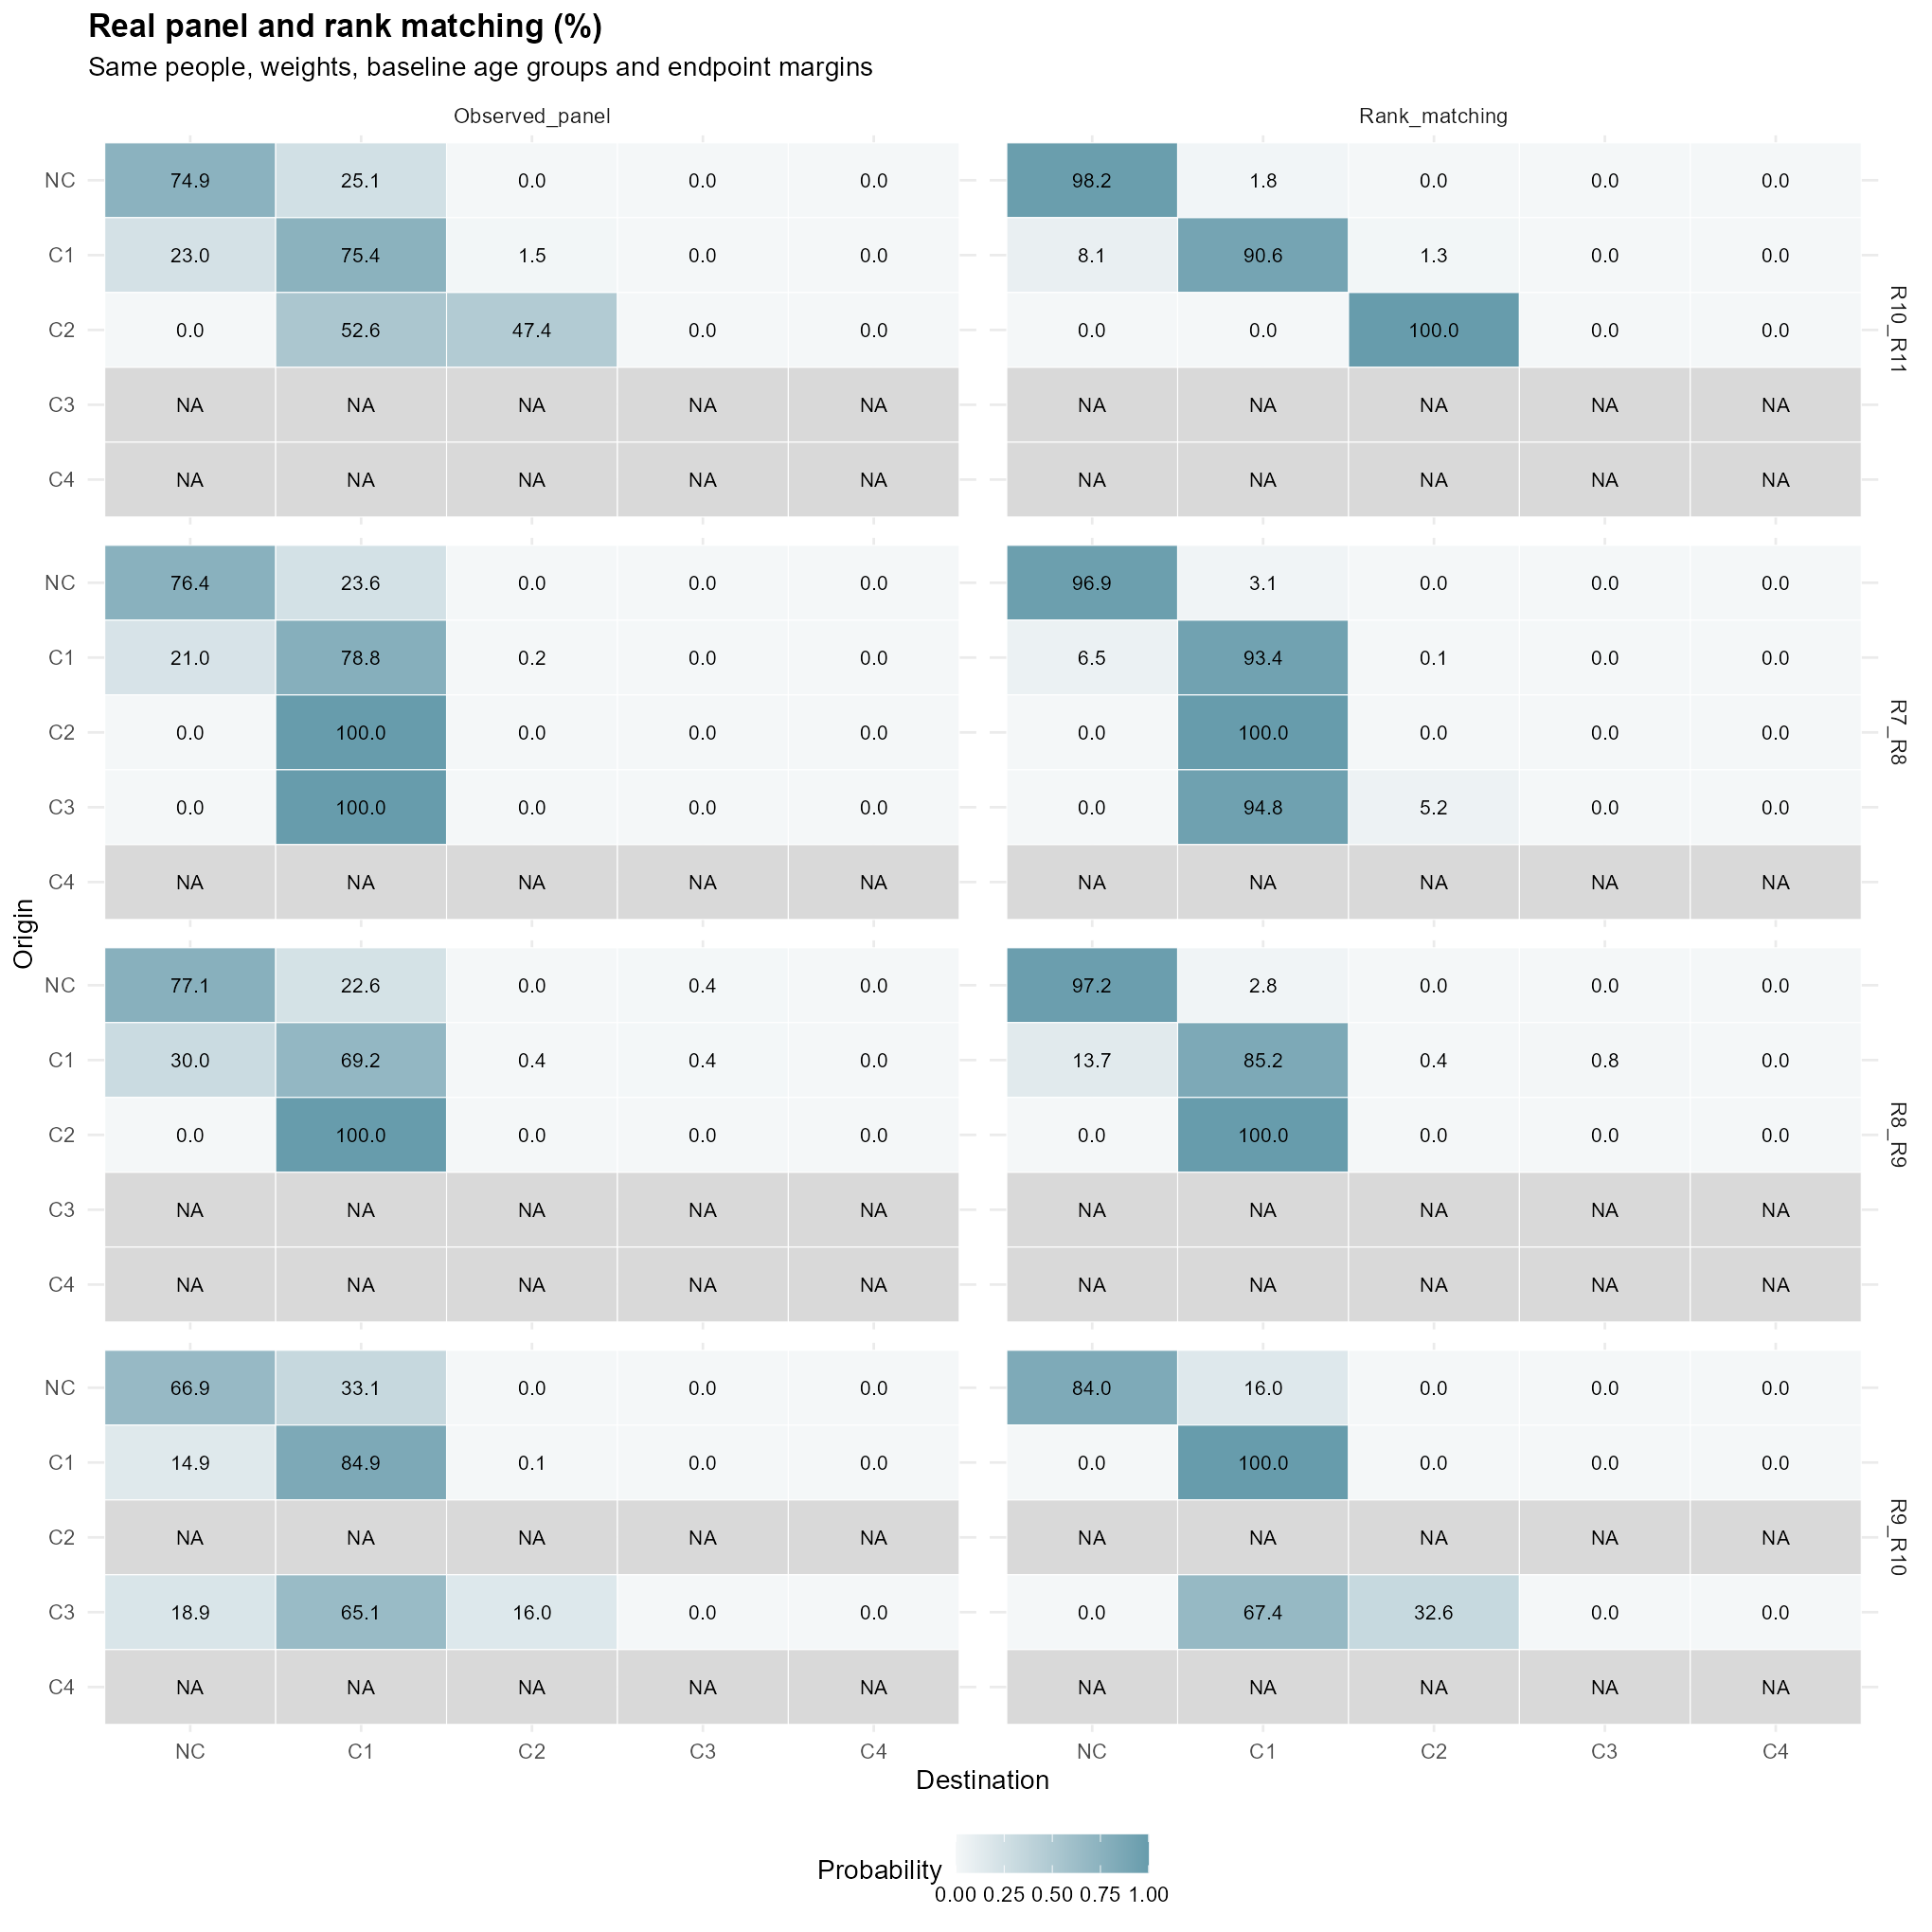

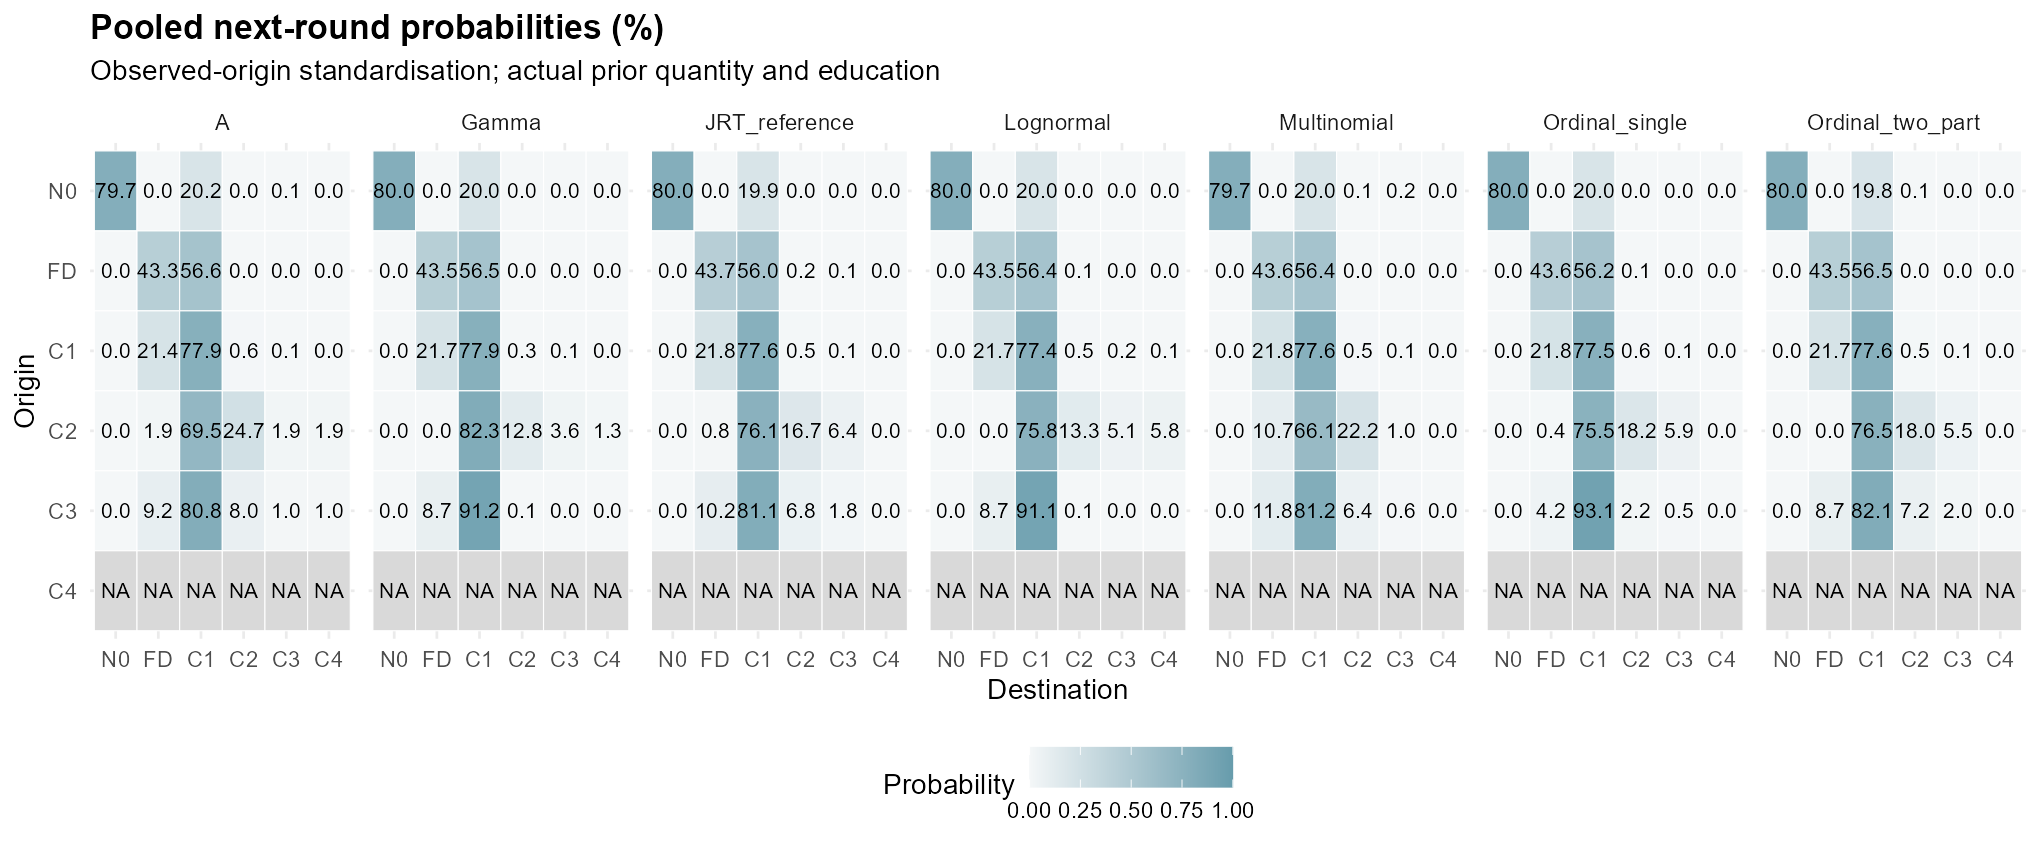

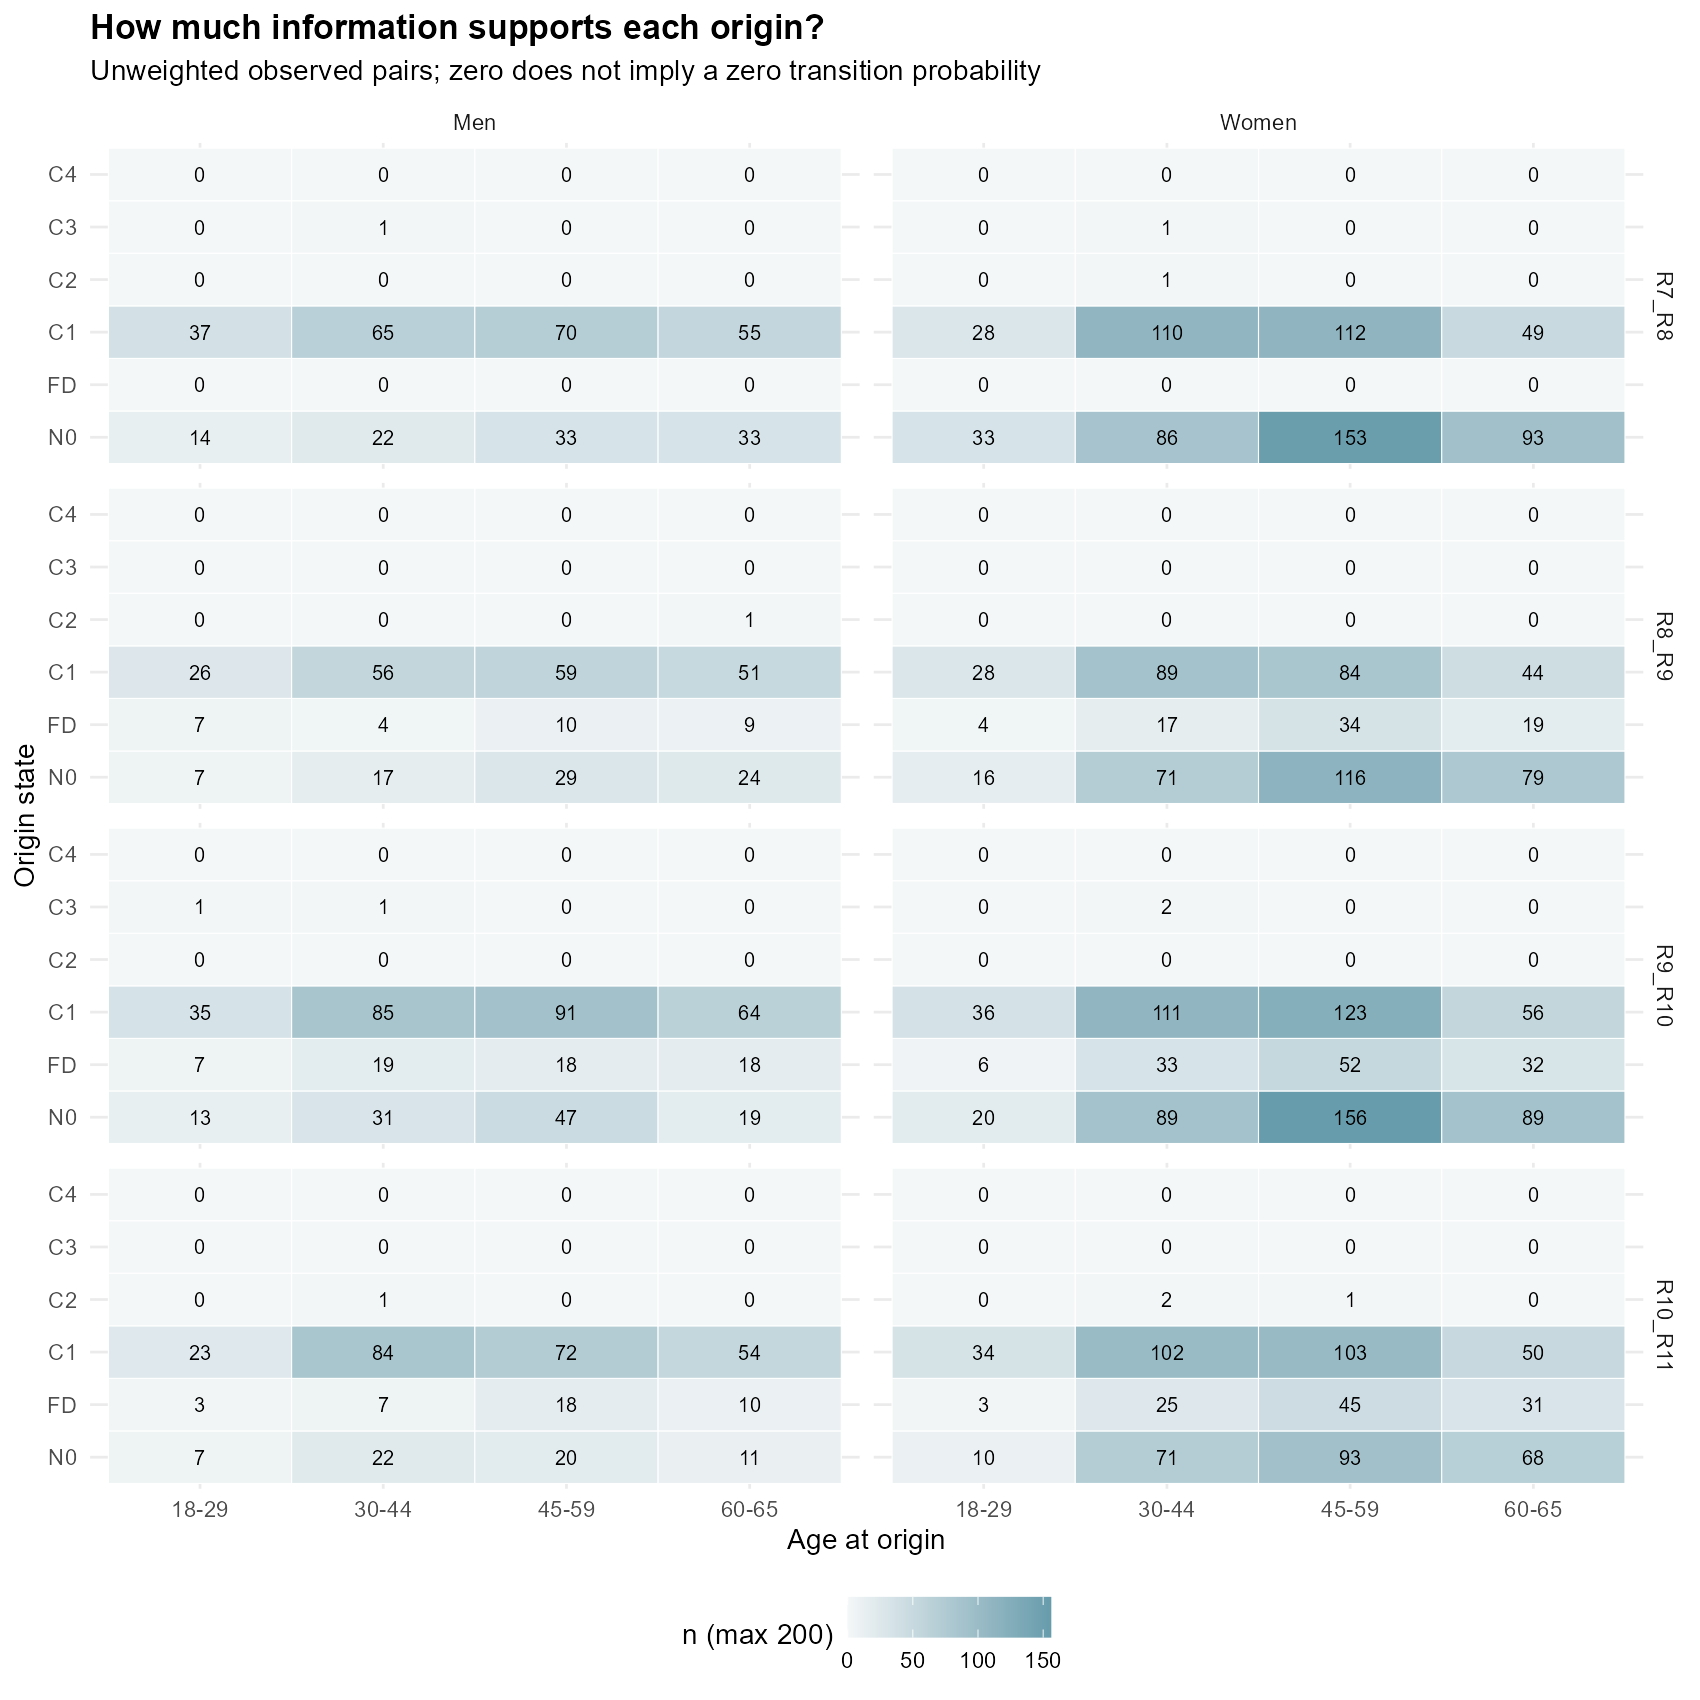

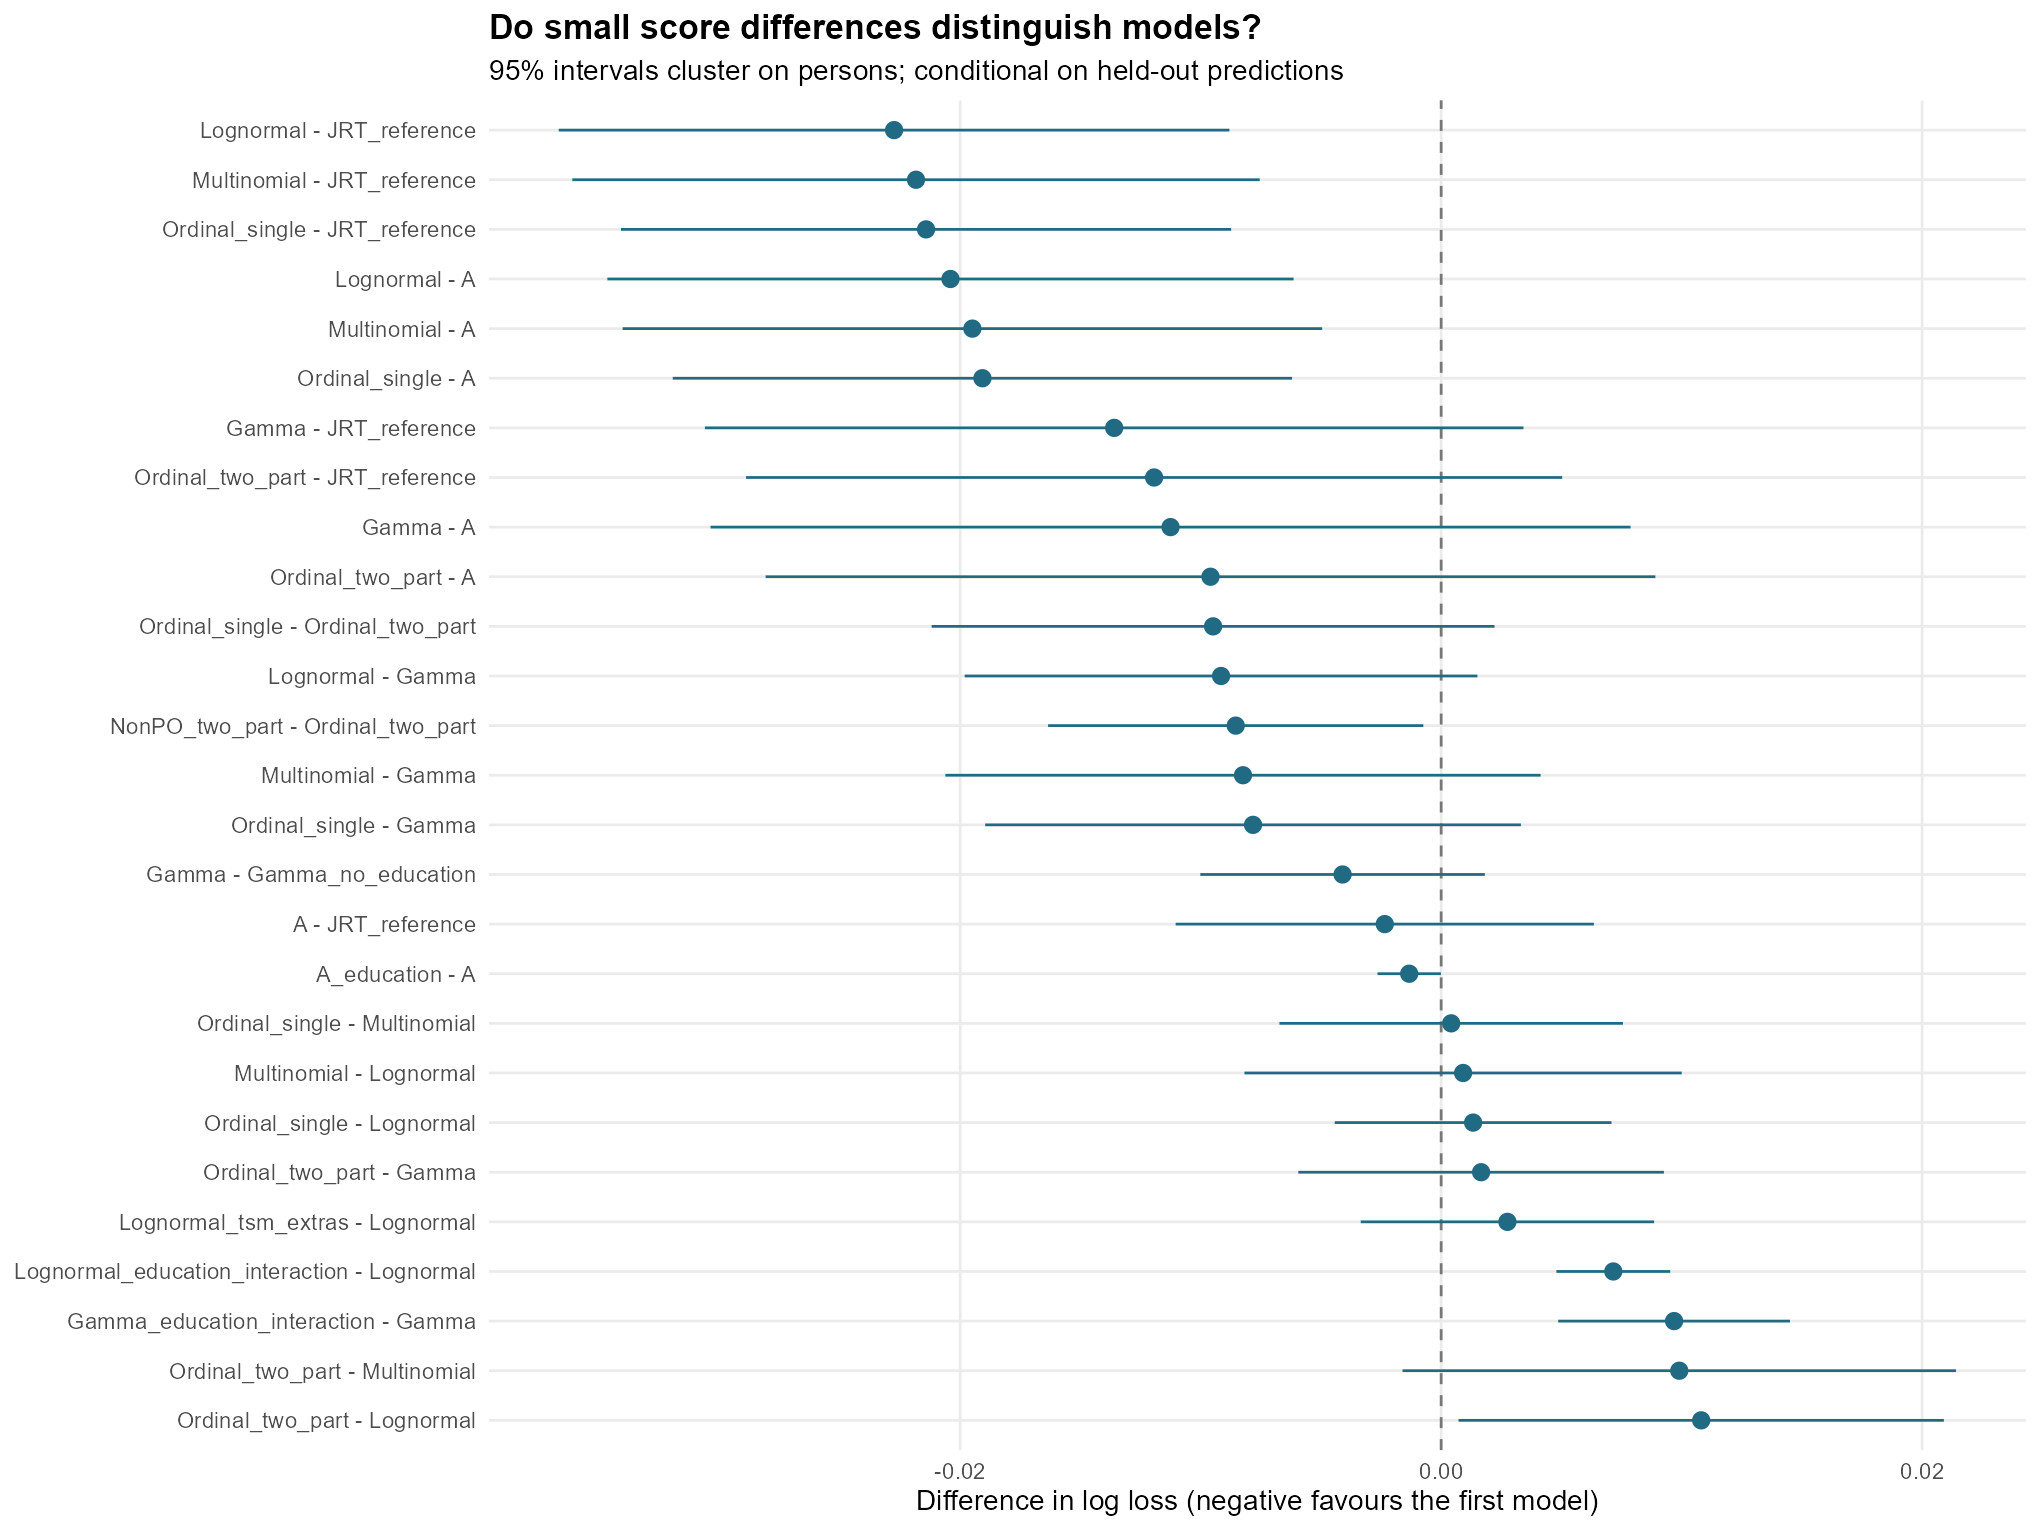

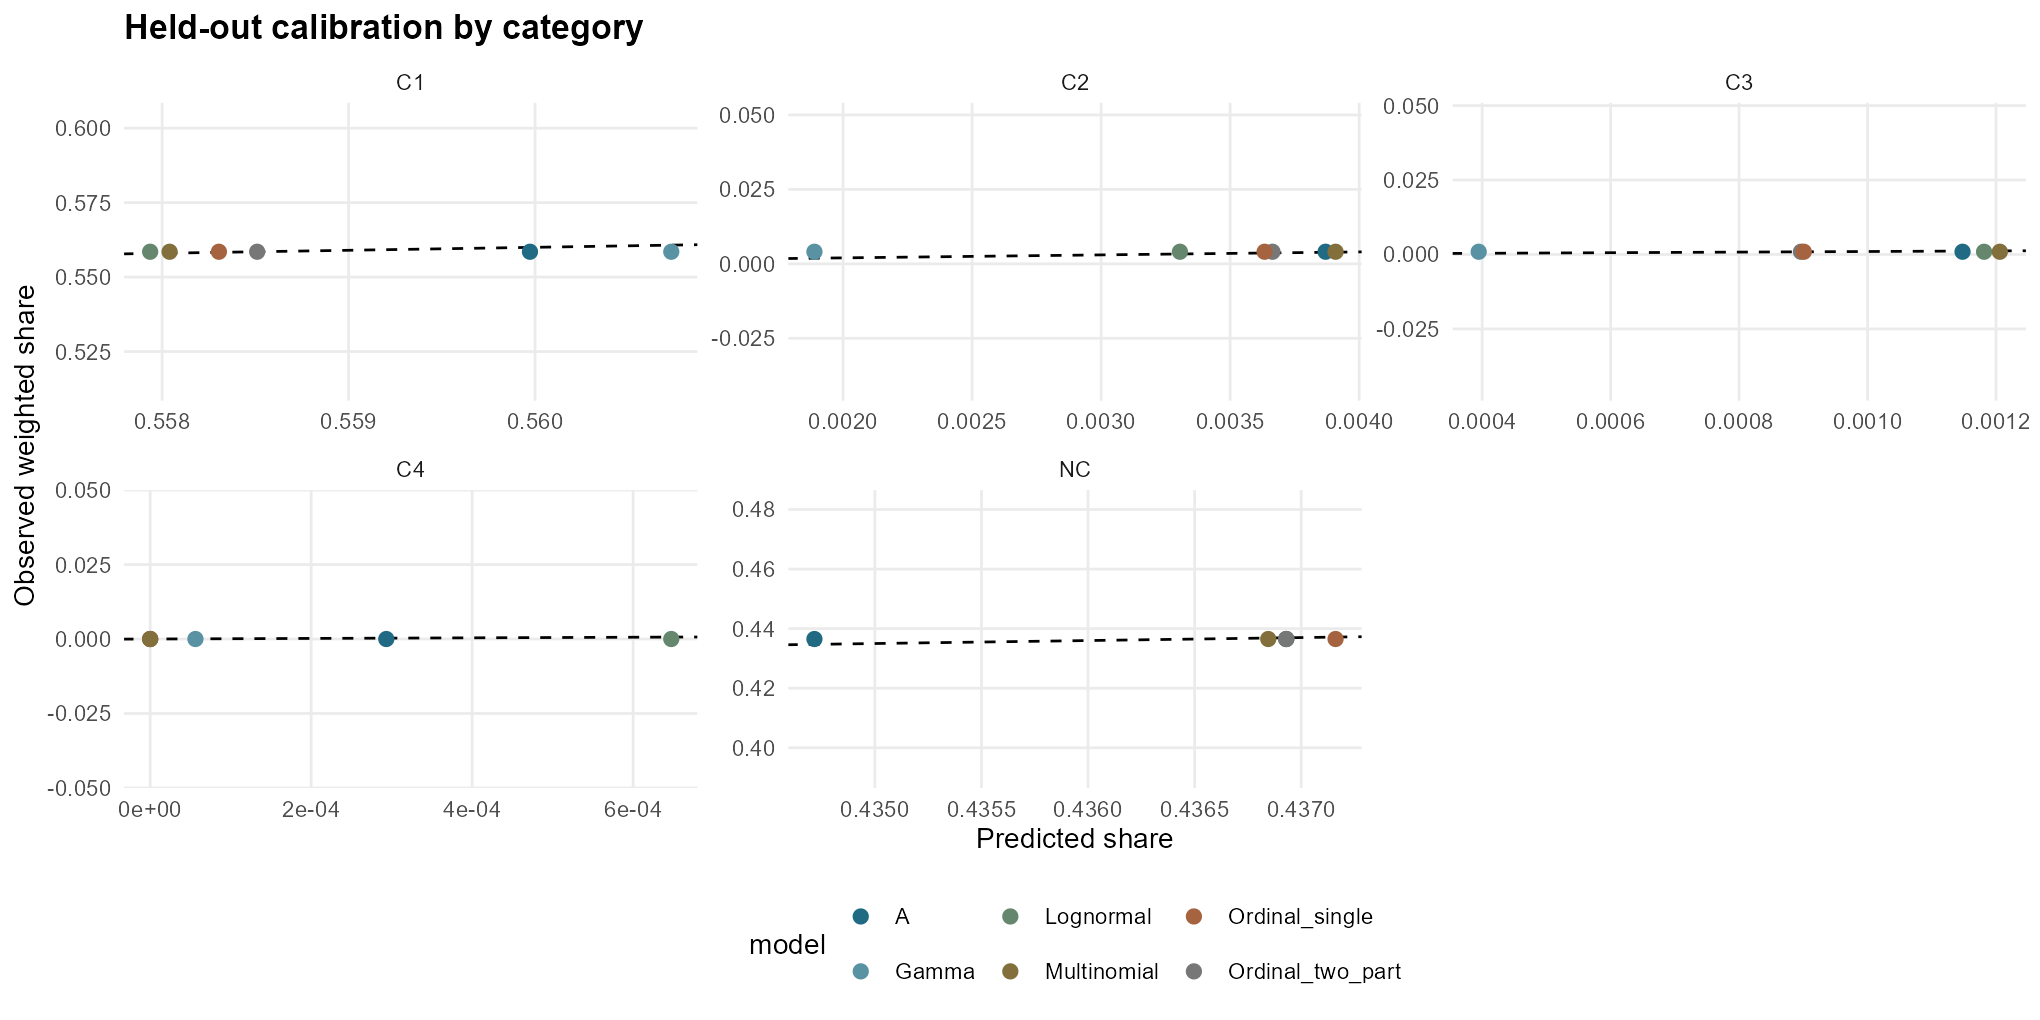

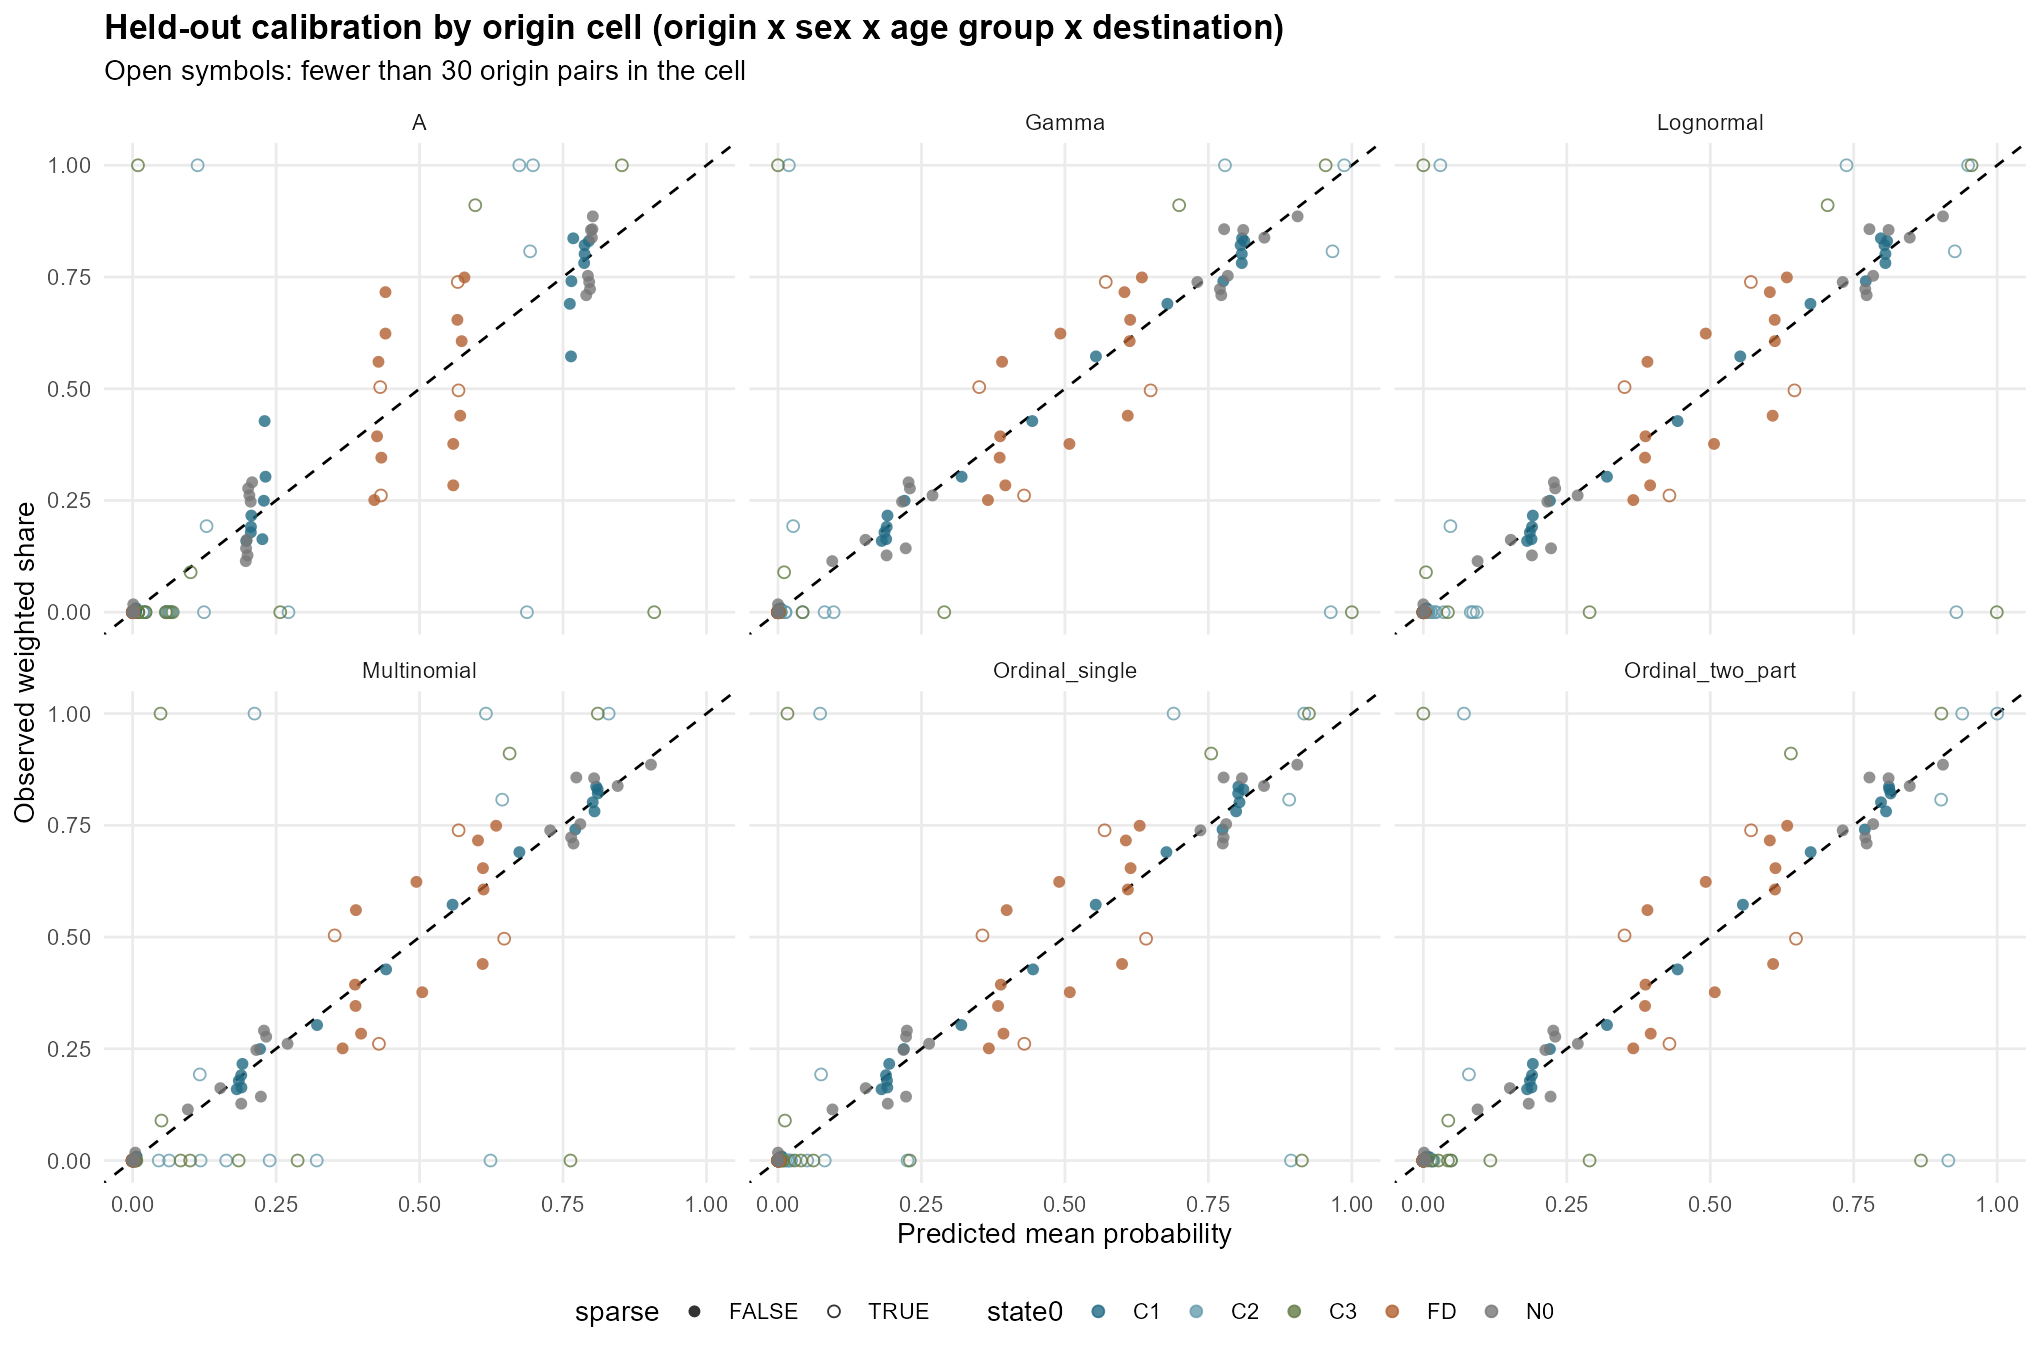

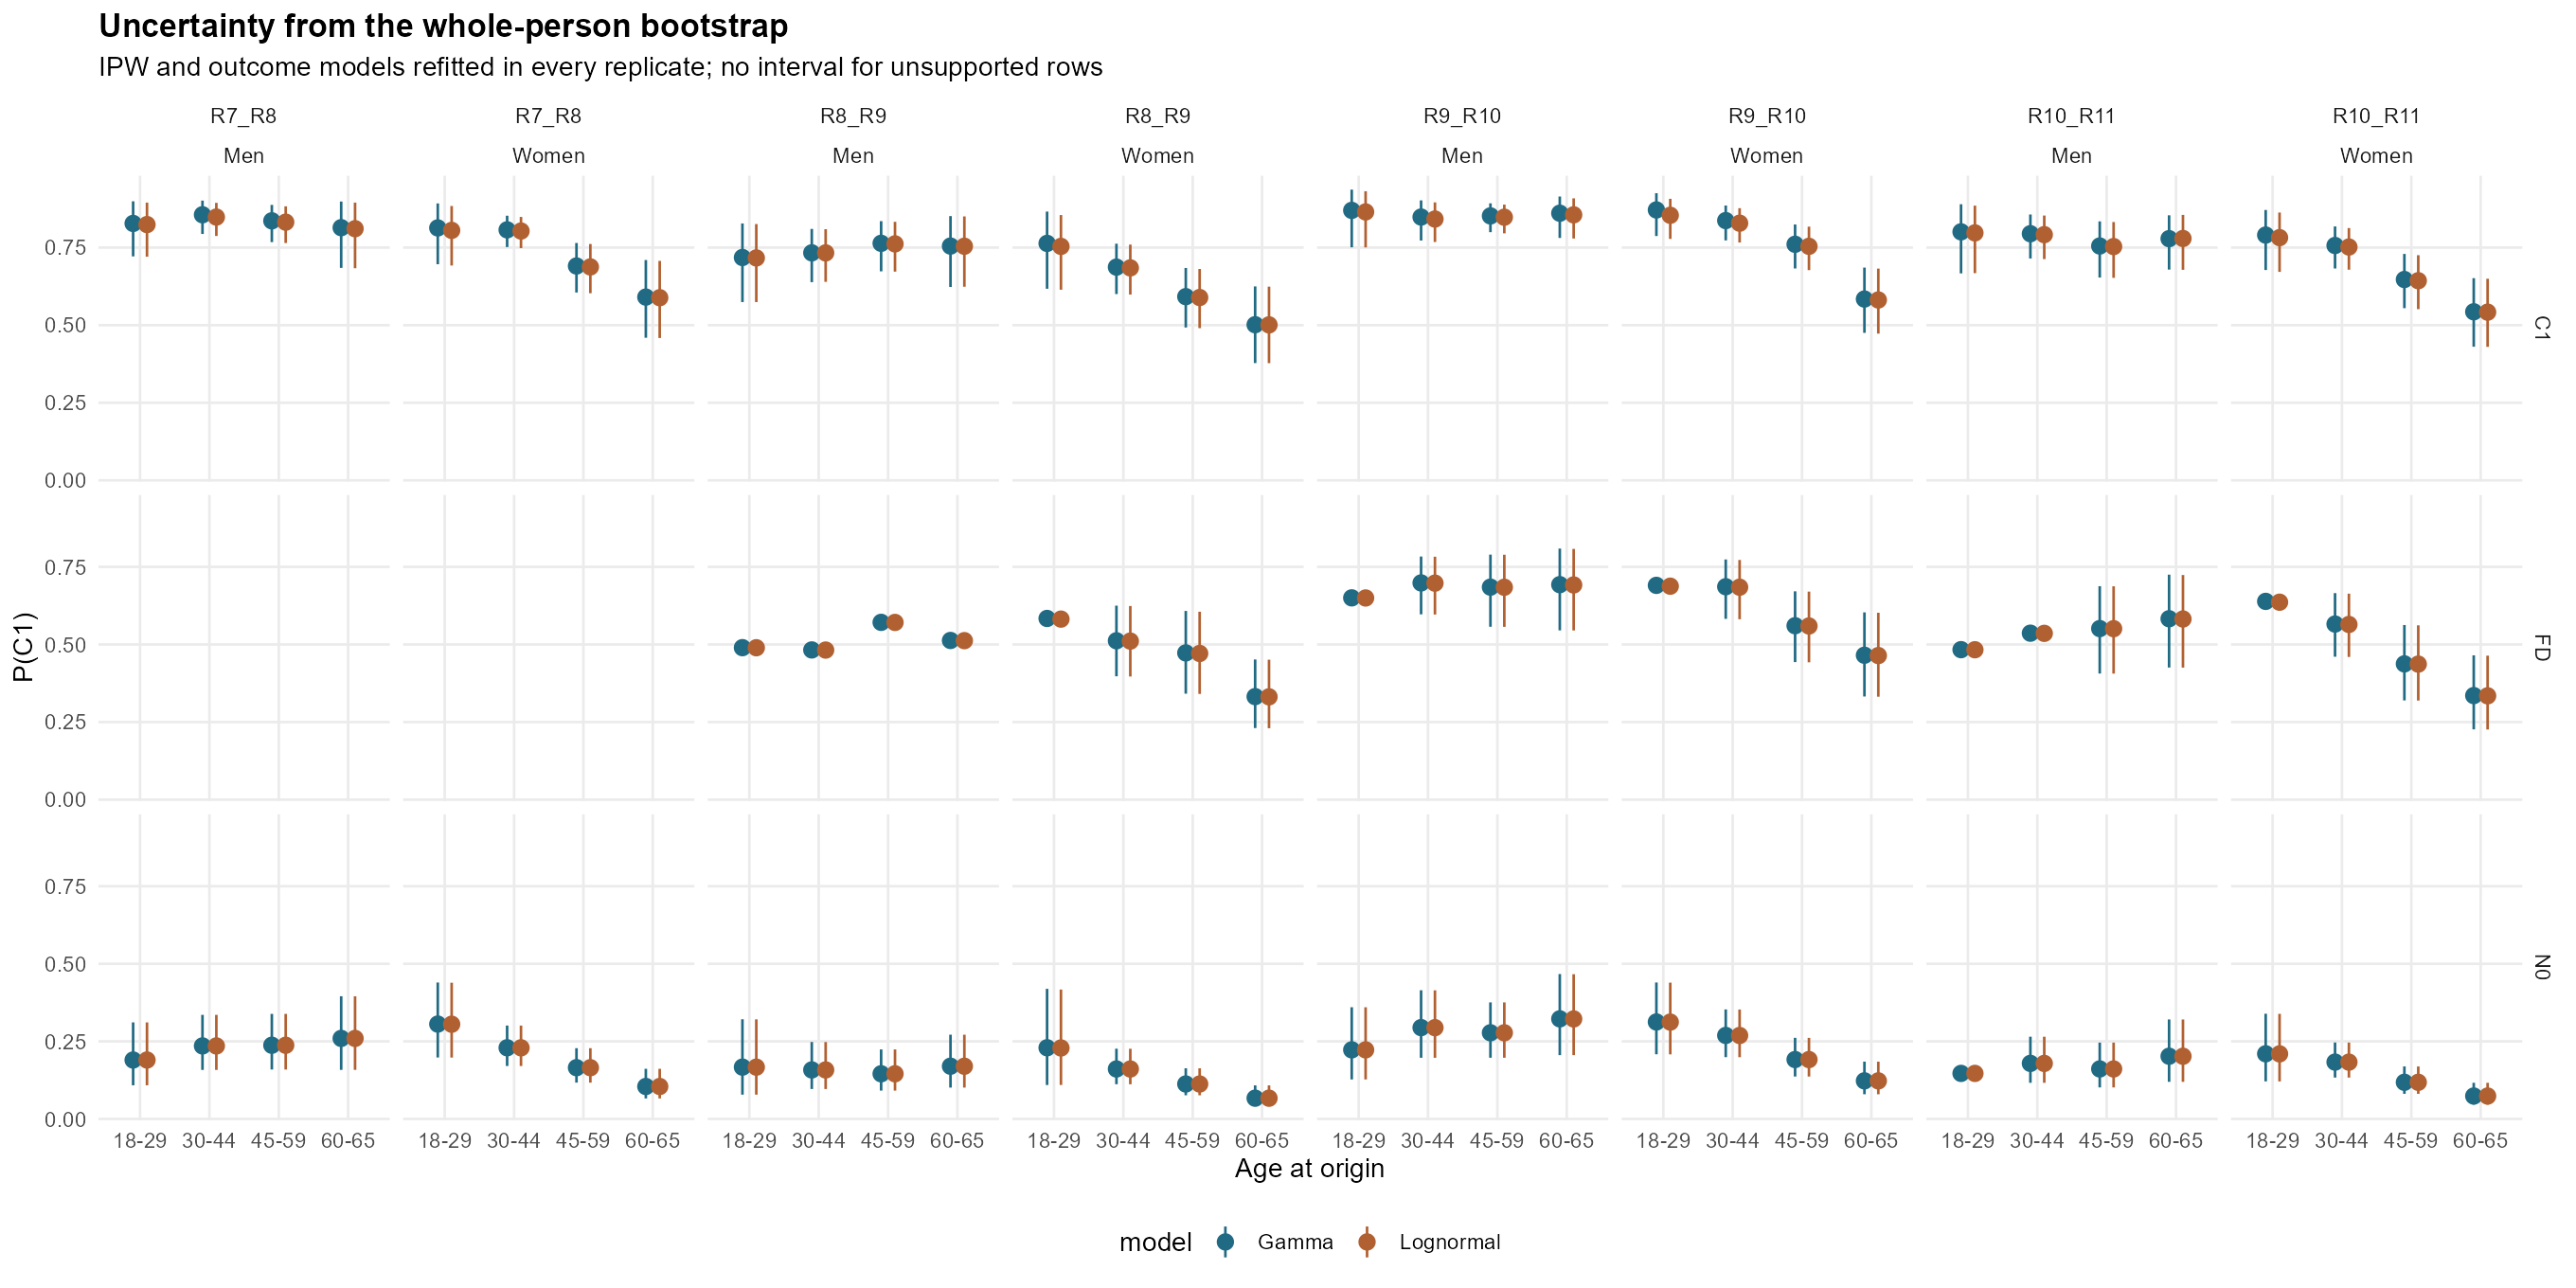

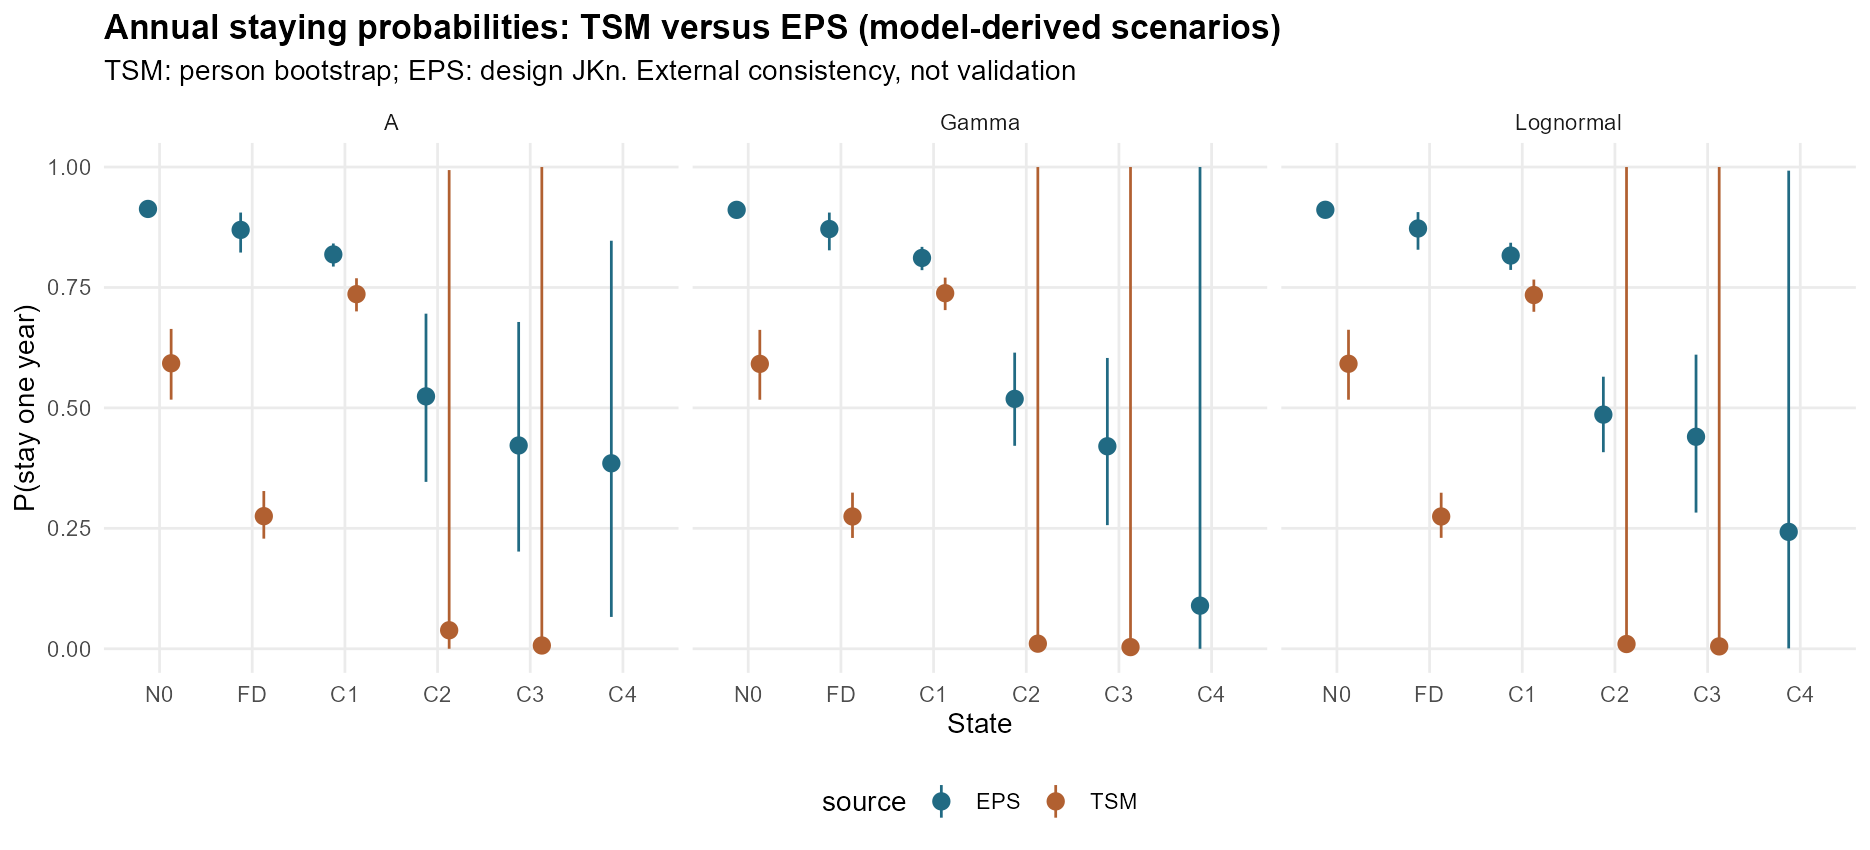

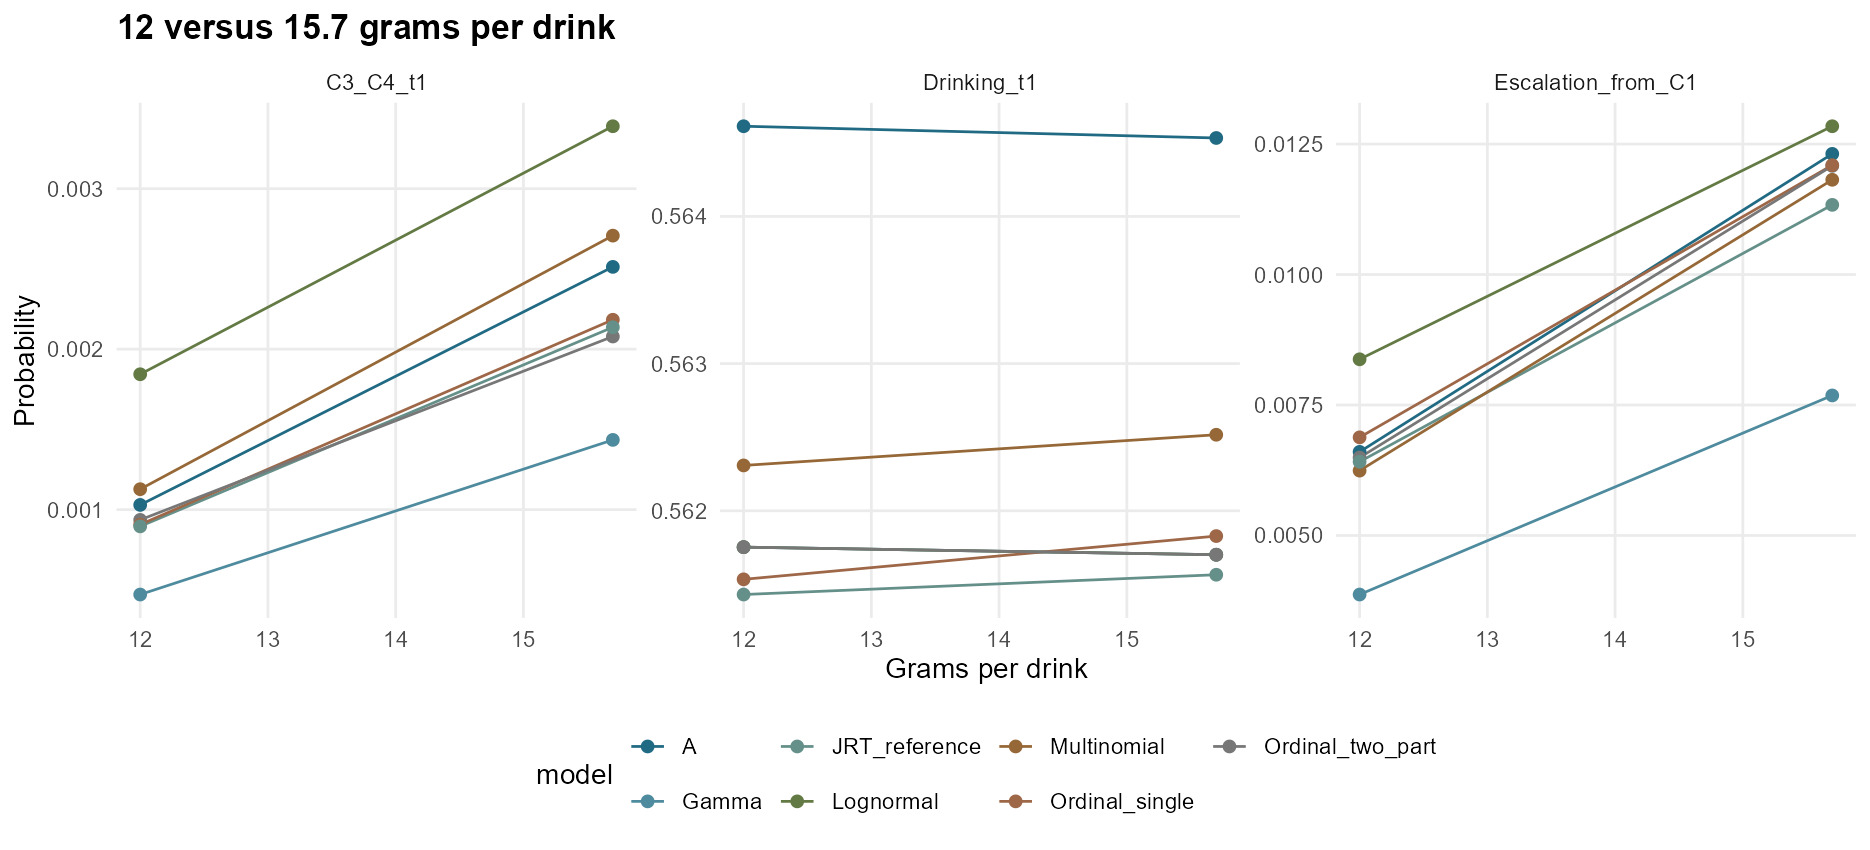

Elapsed: 0.87 minutes


In [13]:
#| label: tsm-sensitivities
.t0 <- Sys.time()
ts_conv <- lapply(c(12, 15.7), function(g) {
 r <- ts_make_risk(ts_waves(g)); d <- ts_ipw_apply(r, ts_ipw_fit(r)); d$pooled <- "All"
 fits <- lapply(stats::setNames(ts_main_models, ts_main_models), function(nm) ts_fit(d, nm, ts_k[1]))
 list(sensitivity = do.call(rbind, lapply(ts_main_models, function(nm) {
  pr <- ts_prob(fits[[nm]], d)
  data.frame(grams_per_drink = g, model = nm, quantity = c("Drinking_t1", "Escalation_from_C1", "C3_C4_t1"),
   probability = c(stats::weighted.mean(1 - pr[, 1], d$wn),
    stats::weighted.mean(rowSums(pr[d$state0 == "C1", 3:5, drop = FALSE]), d$wn[d$state0 == "C1"]),
    stats::weighted.mean(rowSums(pr[, 4:5, drop = FALSE]), d$wn)))
 })), pooled = if (g == 15.7) do.call(rbind, lapply(ts_main_models, function(nm) ts_matrices(d, ts_prob(fits[[nm]], d), nm, by = "pooled"))))
})
ts_sensitivity <- do.call(rbind, lapply(ts_conv, function(x) x$sensitivity))
ts_save(ts_sensitivity, "conversion_sensitivity")
ts_save(ts_conv[[2]]$pooled, "transition_matrices_15_7g")
ts_upper <- ts_upper_band_sensitivity()
ts_save(ts_upper$summary, "upper_band_sensitivity"); ts_save(ts_upper$pooled, "upper_band_pooled_matrices")
# Four weighting scenarios separate the inverse-probability correction from the trimming of extreme expansion factors.
ts_weight_sens <- do.call(rbind, lapply(c("base_only", "base_trimmed", "IPW_untrimmed", "base_plus_IPW"), function(s) {
 d <- ts_d
 for (p in ts_periods) {
  ii <- d$period == p
  w <- switch(s, base_only = d$wbase[ii],
   base_trimmed = { cap <- ts_wquant(d$wbase[ii], d$mult[ii], c(.01, .99)); pmin(pmax(d$wbase[ii], cap[1]), cap[2]) },
   IPW_untrimmed = d$untrimmed[ii], base_plus_IPW = d$wn[ii])
  d$wn[ii] <- w / sum(w) * ts_period_mass[[p]]
 }
 pr <- ts_prob(ts_fit(d, "Gamma", ts_k[1]), d)
 data.frame(scenario = s, current_t1 = stats::weighted.mean(1 - pr[, 1], d$wn), C3_C4_t1 = stats::weighted.mean(rowSums(pr[, 4:5]), d$wn),
  weight_ESS = sum(d$wn)^2 / sum(d$wn^2))
}))
ts_save(ts_weight_sens, "weight_refit_sensitivity")
ts_edu_sens <- ts_education_sensitivity()
ts_save(ts_edu_sens$summary, "education_sensitivity"); ts_save(ts_edu_sens$pooled, "education_sensitivity_pooled_matrices")
# Held-out scores of alternative risk sets (one CV repeat): the period masses follow each variant's own complete pairs.
ts_variant_cv <- function(r, label, models = c("A", "Lognormal")) {
 old_mass <- ts_period_mass
 ts_period_mass <<- stats::setNames(vapply(ts_periods, function(p) sum(r$period == p & r$complete), 1), ts_periods)
 on.exit(ts_period_mass <<- old_mass, add = TRUE)
 d <- ts_ipw_apply(r, ts_ipw_fit(r))
 tab <- ts_cv_tables(ts_cv(r, model_names = models, repeats = 1, d = d), d = d)$summary
 cbind(variant = label, tab, pairs = nrow(d), persons = length(unique(d$id)), row.names = NULL)
}
ts_edu_cv <- rbind(ts_variant_cv(ts_risk, "lenient"),
 ts_variant_cv(ts_make_risk(ts_waves(education_rule = "strict")), "strict"),
 ts_variant_cv(ts_make_risk(ts_waves(education_rule = "reached")), "reached"))
ts_save(ts_edu_cv, "education_sensitivity_cv")
# Link rule sensitivity: the strict EPS age bounds (tolerance 0) instead of the primary bounds widened by one year.
ts_W_strict <- ts_waves(tolerance = 0); ts_risk_strict <- ts_make_risk(ts_W_strict, tolerance = 0)
ts_save(ts_link_audit(ts_W_strict, ts_risk_strict, tolerance = 0), "link_audit_strict_bounds")
ts_link_cv <- rbind(ts_variant_cv(ts_risk, "primary_bounds_tolerance_1"), ts_variant_cv(ts_risk_strict, "strict_EPS_bounds"))
ts_link_pooled <- ts_point_sensitivity(list(primary_bounds_tolerance_1 = ts_risk, strict_EPS_bounds = ts_risk_strict), c("A", "Lognormal"), "variant")
ts_save(ts_link_cv, "link_bounds_sensitivity_cv"); ts_save(ts_link_pooled$summary, "link_bounds_sensitivity")
ts_save(ts_link_pooled$pooled, "link_bounds_pooled_matrices")
ts_hed_result <- ts_hed(); ts_save(ts_hed_result$coef, "typical_quantity_signal_coefficients")
ts_save(ts_hed_result$proportions, "typical_quantity_signal_by_category")
z1 <- ts_d[!is.na(ts_d$hed6_1), ]; z0 <- ts_d[!is.na(ts_d$hed6_0), ]
ts_hed6 <- rbind(
 do.call(rbind, lapply(split(z1, ts_key(z1, c("y1", "sex"))), function(z) data.frame(level = "destination", category = as.character(z$y1[1]),
  sex = as.character(z$sex[1]), n = nrow(z), share_hed6 = stats::weighted.mean(z$hed6_1, z$wn)))),
 do.call(rbind, lapply(split(z0, z0$state0, drop = TRUE), function(z) data.frame(level = "origin", category = as.character(z$state0[1]),
  sex = "All", n = nrow(z), share_hed6 = stats::weighted.mean(z$hed6_0, z$wn)))))
rownames(ts_hed6) <- NULL
ts_save(ts_hed6, "hed6_item_by_category")
ts_show(ts_sensitivity, "Conversion sensitivity, refitted main models at 12 and 15.7 g per drink", 4)
ts_show(ts_upper$summary, "Upper band 16 drinks instead of 10; point estimates", 4)
ts_show(ts_weight_sens, "Refitted weight sensitivity: base, trimmed base, untrimmed IPW and primary weights", 4)
ts_show(ts_edu_sens$summary, "Education rule sensitivity: strict and reached-level variants; point estimates", 4)
ts_show(ts_edu_cv, "Education rule sensitivity: held-out scores, one CV repeat", 5)
ts_show(ts_link_cv, "Link rule sensitivity: pairs retained and held-out scores under the strict EPS age bounds", 5)
ts_show(ts_link_pooled$summary, "Link rule sensitivity: pooled point estimates", 4)
ts_show(ts_hed6, "Weighted share reporting the 6+ item by destination category and by origin state", 3)
ts_plots()
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


## Limitations, review and reproducibility

- The TSM alcohol items have no recall window, so "current drinking", FD and the quantity signals are proxies, not ENPG 30-day constructs.
- No primary sampling units or strata are released; `Fact_Exp` is cross-sectional, and the whole-person bootstrap is the only uncertainty computed. It does not reconstruct the original design variance.
- Round dates are approximate fieldwork months, and the date of round 11 is unverified; the elapsed months, and with them the link rule and the annual layer, inherit this approximation.
- At 12 g per drink C4 is unreachable for men and nearly empty for women (above 60 g/day) with the primary lookup; its probabilities come mostly from model tails and from the conversion sensitivities.
- TSM intervals are short compared with the multi-year EPS intervals; short intervals observe fewer changes and make the annual layer depend more on the generator assumptions.
- FD requires observed earlier drinking within the panel; N0 is incomplete history. TSM FD identifies people who drank within the previous year or two, so its relapse rate is a different quantity from the EPS former-drinker row.
- Pooled next-round tables mix four interval lengths; only the annual layer compares with EPS, with the caveat that a generator fitted to months-long windows is a compromise across intervals.

The checks recorded during execution are listed in the table below and exported together with the configuration, the fit warnings and the session information without machine paths. The notebook is executed in a fresh kernel twice, in the working output folder and in a reproduction folder; an external verifier compares the exported tables byte by byte, checks the notebook metadata against the source files and inserts the quick-reading summary and the reproduction check. Reproducing results does not prove the assumptions true.


In [14]:
#| label: tsm-reproducibility
.t0 <- Sys.time()
ts_checks_table <- data.frame(check = names(ts_checks), passed = unlist(ts_checks), row.names = NULL)
ts_save(ts_checks_table, "analysis_checks")
ts_save(data.frame(seed = ts_seed, person_bootstrap_replicates = ts_B, CV_repetitions = ts_repeats,
 periods = paste(ts_periods, collapse = ";"), grams_primary = 12, education_rule = "lenient"), "analysis_configuration")
ww <- as.data.frame(table(ts_warnings), stringsAsFactors = FALSE); names(ww) <- c("warning", "n")
ts_save(ww, "fit_warnings")
ts_check(all(ts_checks_table$passed), "All recorded checks passed")
ts_show(ts_checks_table, "Executed checks on real TSM data")
si <- utils::capture.output(utils::sessionInfo())
writeLines(si[!grepl("[A-Za-z]:[/\\\\]", si)], file.path(ts_out, "session_info.txt"))
cat(sprintf("Elapsed: %.2f minutes\n", as.numeric(difftime(Sys.time(), .t0, units = "mins"))))


check,passed
One row per person and interval,TRUE
Positive finite main weights,TRUE
Observed pairs respect the history-state transition map,TRUE
v2 regression quantities match,TRUE
Weight-scale invariance Gamma,TRUE
Weight-scale invariance Lognormal,TRUE
Weight-scale invariance Multinomial,TRUE
Weight-scale invariance Ordinal_two_part,TRUE
Disjoint persons CV 1:1,TRUE
Disjoint persons CV 1:2,TRUE


Elapsed: 0.00 minutes


## Reproduction check: PASS

The notebook ran twice in **fresh R kernels**, with 14 completed code cells and no errors. All **63 CSV files (17,405 aggregate rows)** are byte-identical between the main run and the reproduction. They include 1,000 whole-person replicates with refitted IPW.

The external verifier checked the embedded source hashes, exported results and every recorded R check. This cell reports that subsequent verification; it does not simulate another execution. Figures were inspected separately. Model assumptions and external validity still require assessment.

[Review report](__andres_control/tsm_v3_review.md) · [File comparison](__andres_control/tsm_markov_outputs/reproducibility_check.csv)

## References

- Calvo E, Medina JT, Ornstein KA, Staudinger UM, Fried LP, Keyes KM. Cross-country and historical variation in alcohol consumption among older men and women: leveraging recently harmonized survey data in 21 countries. *Drug and Alcohol Dependence*. 2020;215:108219. DOI [10.1016/j.drugalcdep.2020.108219](https://doi.org/10.1016/j.drugalcdep.2020.108219).
- Kilian C, Buckley C, Lemp JM, Kou X, Kerr WC, Mulia N, Purshouse RC, Rehm J, Probst C. Targeting alcohol use in high-risk population groups: a US microsimulation study of beverage-specific pricing policies. *Lancet Public Health*. 2025. DOI [10.1016/S2468-2667(25)00165-3](https://doi.org/10.1016/S2468-2667(25)00165-3).
- Puka K, Buckley C, Mulia N, Lasserre AM, Rehm J, Probst C. Educational attainment and lifestyle risk factors associated with all-cause mortality in the US. *Addiction*. 2023. DOI [10.1111/add.16024](https://doi.org/10.1111/add.16024).
- SIMAH microsimulation, release 0.1.1. DOI [10.5281/zenodo.15641639](https://doi.org/10.5281/zenodo.15641639). This notebook estimates Chilean transition components; it does not execute SIMAH or import US parameter values.
- EPS engine and notebook: `__andres_control/eps_markov_core.R`, `__andres_control/eps_markov_transitions_EN.ipynb`; harmonization source `__andres_control/eps_alcohol_prevalencia_persistencia.ipynb`.
- TSM version 2 notes and outputs: `_tsm/notes/TSM_ENPG_v2_EN.md`, `_tsm/notes/TSM_ENPG_v2_findings.md`, `_tsm/notes/v2_outputs/`; version 3 contract `__andres_control/tsm_v3_plan_2026-10-19.md`; questionnaires in `_tsm/docs/`.
